# Weekly Sales Forecasting – DSMarket

**Goal.** Forecast weekly unit sales for every item–store combination, to support stock planning for a retail chain.

**Data.** 3,049 items × 10 stores in 3 cities (New York, Boston, Philadelphia), 279 weeks (Jan 2011 – Apr 2016). About 6.7 M item–store–week rows after aggregating daily sales to weeks. Extra sources: weekly prices, an event calendar, weather (Meteostat) and the product clusters from notebook 02.

**Approach.**
- **Features:** sales lags (1, 4, 26, 52 weeks), 4-week rolling mean, prior-year price level and regional / quarterly sales shares, calendar sine/cosine, event-proximity ("heat") features, weather, one-hot store and department, product cluster.
- **Models:** XGBoost (raw target and log-difference target) and Lasso regression with a square-root target.
- **Validation:** chronological split – train weeks 53–253, validation weeks 255–268, test weeks 270–278 (the first 52 weeks are dropped because the 52-week lag is not available). Hyperparameters are tuned with Optuna and `LassoCV`; details in section 4. All errors are one-step-ahead: lag features use the real sales of previous weeks.
- **Baseline:** naive forecast = last week's sales (`lag_1_sale`), evaluated on the same rows as each model.

**Final metrics** (units per item–store–week; full table at the end of section 7):

| Model | Set | RMSE | MAE | WMAPE | RMSE improvement vs naive | WMAPE improvement vs naive |
|---|---|---|---|---|---|---|
| Lasso (sqrt target) | Validation (weeks 255–268) | 8.70 | 3.36 | 41.5% | +11.2% | +13.6% |
| Naive (lag-1) | Validation (weeks 255–268) | 9.79 | 3.89 | 48.0% | – | – |
| Lasso (sqrt target) | Test (weeks 270–278) | 7.71 | 3.37 | 35.0% | +9.7% | +13.0% |
| Naive (lag-1) | Test (weeks 270–278) | 8.54 | 3.87 | 40.2% | – | – |
| XGBoost (log-diff target) | Test (weeks 270–278)\* | 8.62 | 3.49 | 36.1% | −0.5% | +9.9% |
| Naive (lag-1) | Test (weeks 270–278)\* | 8.58 | 3.88 | 40.1% | – | – |

WMAPE = Σ|y − ŷ| / Σy. Improvement = (1 − model error / naive error); positive means the model is better.
\*The XGBoost test set excludes rows with missing feature values (269,541 of 274,410 rows).

At company level (WMAPE of the weekly totals) the naive forecast is better: 12.6% / 4.4% (validation / test) vs 15.5% / 8.6% for Lasso and 15.7% for XGBoost (test).

**Conclusion.** Lasso is the selected model. On test weeks that were not used for any modelling choice, it reduces item-level error vs the naive baseline by about 10% (RMSE) and 13% (WMAPE). It is also cheap to train and stable in recursive forecasts, while XGBoost does not beat the naive baseline on RMSE. **Limitation:** both models are trained on a transformed target (sqrt / log) and under-forecast total volume (predicted volume ≈ 89–91% of actual sales for Lasso, 84% for XGBoost), so for weekly company totals the naive forecast is more accurate. Next steps: correct the back-transformation bias (e.g. a smearing factor) or train on the raw target with a Poisson/Tweedie objective, and evaluate multi-week recursive forecasts.

## 1. Importing libraries and files

In [41]:
import numpy as np
import pandas as pd

In [42]:

path = './Data_for_Power_BI/weekly_data_for_power_bi.csv'
path_cluster = './df_cluster.csv'
path_events = './Data_for_Power_BI/daily_calendar_with_expanded_events.csv'


In [ ]:
df_weekly = pd.read_csv(path)
df_calendar_original = pd.read_csv(path_events)
df_cluster = pd.read_csv(path_cluster)

In [ ]:
df_calendar = df_calendar_original.groupby('yearweek').agg({'date': 'min', 'Weekly_Event' : 'first'}).reset_index()
df_calendar['Year'] = pd.to_datetime(df_calendar['date']).dt.year
df_calendar['Quarter'] = pd.to_datetime(df_calendar['date']).dt.quarter
df_calendar['Month'] = pd.to_datetime(df_calendar['date']).dt.month
df_calendar['Day_month'] = pd.to_datetime(df_calendar['date']).dt.day

In [ ]:
df_calendar.head()

,yearweek,date,Weekly_Event,Year,Quarter,Month,Day_month
0,201105.0,2011-01-29,No Event,2011,1,1,29
1,201106.0,2011-02-05,Superbowl,2011,1,2,5
2,201107.0,2011-02-12,Valentine's Day,2011,1,2,12
3,201108.0,2011-02-19,Presidents' Day,2011,1,2,19
4,201109.0,2011-02-26,No Event,2011,1,2,26


In [ ]:
df_weekly.head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,week_number
0,ACCESORIES_1_004,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201105.0,10,5.77,57.72,1
1,ACCESORIES_1_004,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201105.0,15,5.77,86.58,1
2,ACCESORIES_1_004,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201105.0,33,5.77,190.48,1
3,ACCESORIES_1_004,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201105.0,8,5.77,46.18,1
4,ACCESORIES_1_004,PHI_1,ACCESORIES,ACCESORIES_1,Philadelphia,Midtown_Village,201105.0,6,5.77,34.63,1


In [ ]:
df_weekly.shape

(6721786, 11)

In [ ]:
df_cluster.head()

,sales_ratio_mean,sell_price_mean,sales_ratio_relative_std,release_week,Sociability,Regionality,Seasonality,%trend_slope,price_elasticity,cluster,item
0,2.760999,11.043445,0.290107,131,0.0,0.400899,0.150287,0.0,-0.330625,5,ACCESORIES_1_001
1,1.855793,5.275790,0.582964,6,0.0,0.366412,0.127449,0.0,-0.059177,4,ACCESORIES_1_002
2,1.252894,3.943779,0.565078,161,0.0,0.178200,0.104309,0.0,0.029035,0,ACCESORIES_1_003
3,14.145769,5.981574,0.228632,1,1.0,0.315894,0.030596,0.0,0.308701,4,ACCESORIES_1_004
4,5.570844,3.832410,0.422320,14,0.0,0.212243,0.097256,0.0,-0.369176,1,ACCESORIES_1_005


In [ ]:
df_cluster.shape

(3049, 11)

In [ ]:
df_calendar.shape

(279, 7)

In [ ]:
df_weekly.week_number.max()

279

In [ ]:
df_weekly[df_weekly.week_number > 104].shape

(4886761, 11)

In [ ]:
df_weekly[df_weekly.week_number > 278]['yearweek'].unique()

array([201617.])

In [ ]:
# Merge calendar features into weekly dataframe
df_weekly = df_weekly.merge(df_calendar[['yearweek', 'Year', 'Quarter', 'Month', 'Day_month']], on='yearweek', how='left')

In [ ]:
df_weekly.head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,week_number,Year,Quarter,Month,Day_month
0,ACCESORIES_1_004,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201105.0,10,5.77,57.72,1,2011,1,1,29
1,ACCESORIES_1_004,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201105.0,15,5.77,86.58,1,2011,1,1,29
2,ACCESORIES_1_004,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201105.0,33,5.77,190.48,1,2011,1,1,29
3,ACCESORIES_1_004,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201105.0,8,5.77,46.18,1,2011,1,1,29
4,ACCESORIES_1_004,PHI_1,ACCESORIES,ACCESORIES_1,Philadelphia,Midtown_Village,201105.0,6,5.77,34.63,1,2011,1,1,29


## 2. Feature Engineering

In [ ]:
df_weekly.columns

Index(['item', 'store_code', 'category_x', 'department', 'region', 'store',
       'yearweek', 'sale', 'sell_price', 'daily_revenue', 'week_number',
       'Year', 'Quarter', 'Month', 'Day_month'],
      dtype='object')

### Price features

In [ ]:
df_price_mean = df_weekly.groupby(['Year', 'item']).agg({'sell_price': 'mean', 'department' : 'first'}).reset_index()
df_price_mean.rename(columns={'sell_price': 'price_mean_year'}, inplace=True)
df_price_mean.head()

,Year,item,price_mean_year,department
0,2011,ACCESORIES_1_002,5.280000,ACCESORIES_1
1,2011,ACCESORIES_1_004,5.693054,ACCESORIES_1
2,2011,ACCESORIES_1_005,3.610588,ACCESORIES_1
3,2011,ACCESORIES_1_008,0.641891,ACCESORIES_1
4,2011,ACCESORIES_1_009,2.251861,ACCESORIES_1


In [ ]:
df_price_depart = df_price_mean.groupby(['Year', 'department']).agg({'price_mean_year': 'mean'}).reset_index()
df_price_depart.rename(columns={'price_mean_year': 'price_mean_department_year'}, inplace=True)
df_price_depart.head()

,Year,department,price_mean_department_year
0,2011,ACCESORIES_1,7.001967
1,2011,ACCESORIES_2,3.733769
2,2011,HOME_&_GARDEN_1,6.085186
3,2011,HOME_&_GARDEN_2,7.343540
4,2011,SUPERMARKET_1,4.203097


In [ ]:
df_prices_aggregated = df_price_mean.merge(df_price_depart, on=['Year', 'department'], how='left')
df_prices_aggregated.head()

,Year,item,price_mean_year,department,price_mean_department_year
0,2011,ACCESORIES_1_002,5.280000,ACCESORIES_1,7.001967
1,2011,ACCESORIES_1_004,5.693054,ACCESORIES_1,7.001967
2,2011,ACCESORIES_1_005,3.610588,ACCESORIES_1,7.001967
3,2011,ACCESORIES_1_008,0.641891,ACCESORIES_1,7.001967
4,2011,ACCESORIES_1_009,2.251861,ACCESORIES_1,7.001967


In [ ]:
df_prices_aggregated['price_proportion_item_department'] = df_prices_aggregated['price_mean_year'] / df_prices_aggregated['price_mean_department_year']
df_prices_aggregated.head()

,Year,item,price_mean_year,department,price_mean_department_year,price_proportion_item_department
0,2011,ACCESORIES_1_002,5.280000,ACCESORIES_1,7.001967,0.754074
1,2011,ACCESORIES_1_004,5.693054,ACCESORIES_1,7.001967,0.813065
2,2011,ACCESORIES_1_005,3.610588,ACCESORIES_1,7.001967,0.515653
3,2011,ACCESORIES_1_008,0.641891,ACCESORIES_1,7.001967,0.091673
4,2011,ACCESORIES_1_009,2.251861,ACCESORIES_1,7.001967,0.321604


In [ ]:
# To join df_prices_aggregated to df_weekly with a 1-year lag,
# we shift Year to Year + 1 (each year uses last year's prices)

df_prices_aggregated['Year_lag1'] = df_prices_aggregated['Year'] + 1

In [ ]:
# Add the new features to df_weekly
df_weekly = df_weekly.merge(df_prices_aggregated
                            [['item', 'Year_lag1', 'price_mean_year', 'price_proportion_item_department']],
                            left_on=['item', 'Year'],
                            right_on=['item', 'Year_lag1'],
                            how='left')
df_weekly.head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,week_number,Year,Quarter,Month,Day_month,Year_lag1,price_mean_year,price_proportion_item_department
0,ACCESORIES_1_004,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201105.0,10,5.77,57.72,1,2011,1,1,29,NaN,NaN,NaN
1,ACCESORIES_1_004,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201105.0,15,5.77,86.58,1,2011,1,1,29,NaN,NaN,NaN
2,ACCESORIES_1_004,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201105.0,33,5.77,190.48,1,2011,1,1,29,NaN,NaN,NaN
3,ACCESORIES_1_004,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201105.0,8,5.77,46.18,1,2011,1,1,29,NaN,NaN,NaN
4,ACCESORIES_1_004,PHI_1,ACCESORIES,ACCESORIES_1,Philadelphia,Midtown_Village,201105.0,6,5.77,34.63,1,2011,1,1,29,NaN,NaN,NaN


In [ ]:
df_weekly[df_weekly.Year >= 2012].head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,week_number,Year,Quarter,Month,Day_month,Year_lag1,price_mean_year,price_proportion_item_department
760780,ACCESORIES_1_002,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201202.0,0,5.28,0.00,51,2012,1,1,7,2012.0,5.28,0.754074
760781,ACCESORIES_1_002,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201202.0,0,5.28,0.00,51,2012,1,1,7,2012.0,5.28,0.754074
760782,ACCESORIES_1_002,BOS_3,ACCESORIES,ACCESORIES_1,Boston,Back_Bay,201202.0,1,5.28,5.28,51,2012,1,1,7,2012.0,5.28,0.754074
760783,ACCESORIES_1_002,NYC_1,ACCESORIES,ACCESORIES_1,New York,Greenwich_Village,201202.0,1,5.28,5.28,51,2012,1,1,7,2012.0,5.28,0.754074
760784,ACCESORIES_1_002,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201202.0,0,5.28,0.00,51,2012,1,1,7,2012.0,5.28,0.754074


In [ ]:
df_weekly.drop(columns=['Year_lag1'], inplace=True)

In [ ]:
df_weekly['changed_price_vs_mean'] = (df_weekly['sell_price'] / df_weekly['price_mean_year']) - 1

### Product maturity features

In [ ]:
# Add the cluster label and the release week
df_weekly = df_weekly.merge(df_cluster[['item', 'cluster', 'release_week']], on='item', how='left')

In [ ]:
df_weekly.head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,week_number,Year,Quarter,Month,Day_month,price_mean_year,price_proportion_item_department,changed_price_vs_mean,cluster,release_week
0,ACCESORIES_1_004,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201105.0,10,5.77,57.72,1,2011,1,1,29,NaN,NaN,NaN,4,1
1,ACCESORIES_1_004,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201105.0,15,5.77,86.58,1,2011,1,1,29,NaN,NaN,NaN,4,1
2,ACCESORIES_1_004,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201105.0,33,5.77,190.48,1,2011,1,1,29,NaN,NaN,NaN,4,1
3,ACCESORIES_1_004,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201105.0,8,5.77,46.18,1,2011,1,1,29,NaN,NaN,NaN,4,1
4,ACCESORIES_1_004,PHI_1,ACCESORIES,ACCESORIES_1,Philadelphia,Midtown_Village,201105.0,6,5.77,34.63,1,2011,1,1,29,NaN,NaN,NaN,4,1


In [ ]:
# Time on the market (weeks since release)
df_weekly['market_presence'] = df_weekly['week_number'] - df_weekly['release_week']

### Calendar features

In [ ]:
# Sine / cosine encoding of the month (yearly cycle)
df_weekly['sin_year'] = np.sin(2 * np.pi * df_weekly['Month'] / 12)
df_weekly['cos_year'] = np.cos(2 * np.pi * df_weekly['Month'] / 12)
df_weekly.head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,...,Month,Day_month,price_mean_year,price_proportion_item_department,changed_price_vs_mean,cluster,release_week,market_presence,sin_year,cos_year
0,ACCESORIES_1_004,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201105.0,10,5.77,57.72,...,1,29,NaN,NaN,NaN,4,1,0,0.5,0.866025
1,ACCESORIES_1_004,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201105.0,15,5.77,86.58,...,1,29,NaN,NaN,NaN,4,1,0,0.5,0.866025
2,ACCESORIES_1_004,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201105.0,33,5.77,190.48,...,1,29,NaN,NaN,NaN,4,1,0,0.5,0.866025
3,ACCESORIES_1_004,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201105.0,8,5.77,46.18,...,1,29,NaN,NaN,NaN,4,1,0,0.5,0.866025
4,ACCESORIES_1_004,PHI_1,ACCESORIES,ACCESORIES_1,Philadelphia,Midtown_Village,201105.0,6,5.77,34.63,...,1,29,NaN,NaN,NaN,4,1,0,0.5,0.866025


In [ ]:
df_weekly[['Month', 'cos_year']].value_counts()

Month  cos_year     
12      1.000000e+00    660088
3       6.123234e-17    640125
4      -5.000000e-01    594577
1       8.660254e-01    573464
8      -5.000000e-01    566746
2       5.000000e-01    559127
11      8.660254e-01    549342
10      5.000000e-01    537768
5      -8.660254e-01    524237
6      -1.000000e+00    515704
9      -1.836970e-16    507913
7      -8.660254e-01    492695
Name: count, dtype: int64

### Weather features

In [ ]:
!pip install meteostat

In [ ]:
from meteostat import Point, Daily
from datetime import datetime, timedelta

In [ ]:

# Coordinates of the airport weather stations
cities_config = {
    "Boston": Point(42.3656, -71.0096),       # KBOS
    "Philadelphia": Point(39.8730, -75.2437), # KPHL
    "New York": Point(40.6446, -73.7797)      # KJFK
}

In [ ]:
start = datetime(2011, 1, 1)
end = datetime(2016, 12, 31)

In [ ]:
def weekyearnum(dt):
    return dt.strftime("%Y%W")

def myweeyearknum(dt):
    offsetdt = dt + timedelta(days=+2) # Adding 2 days offset
    return weekyearnum(offsetdt)

In [ ]:
list_of_dfs = []

for city_name, location in cities_config.items():

    data = Daily(location, start, end)
    data = data.fetch()

    data['rainy_day'] = (data['prcp'] > 0).astype(int)

    data['yearweek'] = data.index.to_series().apply(myweeyearknum)

    weekly_weather = data.groupby('yearweek').agg({
    'tavg': 'mean',  # Average Temp
    'tmin': 'min',   # Minimum Temp
    'tmax': 'max',   # Maximum Temp
    'prcp': 'sum',   # Total precipitation volume
    'snow': 'sum',   # Total snowfall
    'wspd': 'mean',  # Average wind speed
    'rainy_day': 'sum'  # Count of rainy days in the week
    })

    weekly_weather.rename(columns={'rainy_day': 'rain_days_count'}, inplace=True)

    weekly_weather['region'] = city_name

    weekly_weather = weekly_weather.reset_index()
    weekly_weather['yearweek'] = weekly_weather['yearweek'].astype(int)

    list_of_dfs.append(weekly_weather)

final_weather_df = pd.concat(list_of_dfs)
final_weather_df.to_csv('./weekly_weather_data_NYC_BOS_PHI.csv', index=False)

In [ ]:
final_weather_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 960 entries, 0 to 319
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   yearweek         960 non-null    int64  
 1   tavg             960 non-null    Float64
 2   tmin             960 non-null    Float64
 3   tmax             960 non-null    Float64
 4   prcp             960 non-null    Float64
 5   snow             960 non-null    Float64
 6   wspd             960 non-null    Float64
 7   rain_days_count  960 non-null    int64  
 8   region           960 non-null    object 
dtypes: Float64(6), int64(2), object(1)
memory usage: 80.6+ KB


In [ ]:
final_weather_df.head()

,yearweek,tavg,tmin,tmax,prcp,snow,wspd,rain_days_count,region
0,201101,1.514286,-5.6,13.3,4.3,66.0,15.171429,2,Boston
1,201102,-2.357143,-7.8,1.7,43.0,157.0,23.142857,3,Boston
2,201103,-2.5,-10.0,4.4,47.4,265.0,16.928571,3,Boston
3,201104,-6.071429,-18.9,1.7,21.4,379.0,15.471429,3,Boston
4,201105,-3.642857,-8.9,2.8,33.2,470.0,14.771429,2,Boston


In [ ]:
final_weather_df.shape

(960, 9)

In [ ]:
final_weather_df.isnull().sum()

yearweek           0
tavg               0
tmin               0
tmax               0
prcp               0
snow               0
wspd               0
rain_days_count    0
region             0
dtype: int64

In [ ]:
df_weekly = df_weekly.merge(final_weather_df, on=['yearweek', 'region'], how='left')

### Event features

In [ ]:
df_calendar.head()

,yearweek,date,Weekly_Event,Year,Quarter,Month,Day_month
0,201105.0,2011-01-29,No Event,2011,1,1,29
1,201106.0,2011-02-05,Superbowl,2011,1,2,5
2,201107.0,2011-02-12,Valentine's Day,2011,1,2,12
3,201108.0,2011-02-19,Presidents' Day,2011,1,2,19
4,201109.0,2011-02-26,No Event,2011,1,2,26


In [ ]:
# We already have weather data (snow, wind, etc.), so adding the
# "blizzard" and "hurricane" events for that week would be redundant

clima_redundante = ["Blizzard", "Hurricane"]

def limpiar_eventos_climaticos(texto_evento):
    for termino in clima_redundante:
        if termino in texto_evento:
            return "No Event"

    return texto_evento

# Clean the calendar
df_calendar['Weekly_Event_Clean'] = df_calendar['Weekly_Event'].apply(limpiar_eventos_climaticos)

In [ ]:
def crear_variable_anticipacion(df, event_column, string_event, max_weeks=8):
    """
    Creates a 'heat' feature (0 to max_weeks) indicating proximity to an event.
    df: DataFrame of the calendar (ordered)
    event_column: Name of the column with event texts (e.g., 'Weekly_Event_Clean')
    string_event: Text to search for (e.g., "Valentine's")
    max_weeks: How many weeks before to start counting (e.g., 4 or 8)
    """

    # identification of event occurrences (Boolean)
    is_event = df[event_column].str.contains(string_event, na=False, regex=False)

    # index series where event occurs
    event_indices = pd.Series(np.where(is_event, df.index, np.nan), index=df.index)

    # fill NaNs backwards with next valid event index
    next_event_index = event_indices.bfill()

    # Transform distance into "heat" (invert)
    distance = next_event_index - df.index
    heat_feature = distance.apply(lambda x: max(0, max_weeks - x) if not np.isnan(x) else 0)

    return heat_feature

In [ ]:
df_calendar = df_calendar.sort_values('yearweek').reset_index(drop=True)

df_calendar['valentines_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Valentine's Day", max_weeks=4)
df_calendar['xmas_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Christmas", max_weeks=8)
df_calendar['superbowl_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Superbowl", max_weeks=3)
df_calendar['thanksgiving_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Thanksgiving", max_weeks=3)
df_calendar['july4_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Independence Day", max_weeks=3)

# Visual check
print(df_calendar[['yearweek', 'Weekly_Event_Clean', 'valentines_heat', 'xmas_heat', 'superbowl_heat', 'thanksgiving_heat', 'july4_heat']].head(20))

    yearweek            Weekly_Event_Clean  valentines_heat  xmas_heat  \
0   201105.0                      No Event              2.0        0.0   
1   201106.0                     Superbowl              3.0        0.0   
2   201107.0               Valentine's Day              4.0        0.0   
3   201108.0               Presidents' Day              0.0        0.0   
4   201109.0                      No Event              0.0        0.0   
5   201110.0                      No Event              0.0        0.0   
6   201111.0                      No Event              0.0        0.0   
7   201112.0                      No Event              0.0        0.0   
8   201113.0                      No Event              0.0        0.0   
9   201114.0                      No Event              0.0        0.0   
10  201115.0                      No Event              0.0        0.0   
11  201116.0        Patriots' Day (Boston)              0.0        0.0   
12  201117.0                 Easter Su

In [ ]:
shopping_keys = ["Black Friday", "Cyber Monday", "Christmas", "Valentine's Day"]
closed_keys = ["New Year's Day", "Thanksgiving", "Christmas", "Independence Day"]

In [ ]:
def classify_event(event_string, keys):
    """Returns 1 if any key is found in the event string description."""
    if event_string == "No Event":
        return 0
    # Check if any key substring is present in the weekly event string
    for key in keys:
        if key in event_string:
            return 1
    return 0

In [ ]:
df_calendar['is_shopping_event'] = df_calendar['Weekly_Event_Clean'].apply(lambda x: classify_event(x, shopping_keys))
df_calendar['is_holiday_closed'] = df_calendar['Weekly_Event_Clean'].apply(lambda x: classify_event(x, closed_keys))

In [ ]:
df_calendar.head()

,yearweek,date,Weekly_Event,Year,Quarter,Month,Day_month,Weekly_Event_Clean,valentines_heat,xmas_heat,superbowl_heat,thanksgiving_heat,july4_heat,is_shopping_event,is_holiday_closed
0,201105.0,2011-01-29,No Event,2011,1,1,29,No Event,2.0,0.0,2.0,0.0,0.0,0,0
1,201106.0,2011-02-05,Superbowl,2011,1,2,5,Superbowl,3.0,0.0,3.0,0.0,0.0,0,0
2,201107.0,2011-02-12,Valentine's Day,2011,1,2,12,Valentine's Day,4.0,0.0,0.0,0.0,0.0,1,0
3,201108.0,2011-02-19,Presidents' Day,2011,1,2,19,Presidents' Day,0.0,0.0,0.0,0.0,0.0,0,0
4,201109.0,2011-02-26,No Event,2011,1,2,26,No Event,0.0,0.0,0.0,0.0,0.0,0,0


In [ ]:
# Merge the calendar event features into df_weekly
df_weekly = df_weekly.merge(df_calendar[['yearweek', 'valentines_heat', 'xmas_heat', 'superbowl_heat',
                                        'thanksgiving_heat', 'july4_heat', 'is_shopping_event', 'is_holiday_closed']],
                            on='yearweek', how='left')

In [ ]:
df_weekly.head()

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,...,snow,wspd,rain_days_count,valentines_heat,xmas_heat,superbowl_heat,thanksgiving_heat,july4_heat,is_shopping_event,is_holiday_closed
0,ACCESORIES_1_004,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201105.0,10,5.77,57.72,...,470.0,14.771429,2,2.0,0.0,2.0,0.0,0.0,0,0
1,ACCESORIES_1_004,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201105.0,15,5.77,86.58,...,470.0,14.771429,2,2.0,0.0,2.0,0.0,0.0,0,0
2,ACCESORIES_1_004,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201105.0,33,5.77,190.48,...,147.0,17.214286,3,2.0,0.0,2.0,0.0,0.0,0,0
3,ACCESORIES_1_004,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201105.0,8,5.77,46.18,...,147.0,17.214286,3,2.0,0.0,2.0,0.0,0.0,0,0
4,ACCESORIES_1_004,PHI_1,ACCESORIES,ACCESORIES_1,Philadelphia,Midtown_Village,201105.0,6,5.77,34.63,...,121.0,13.314286,3,2.0,0.0,2.0,0.0,0.0,0,0


In [ ]:
df_weekly[df_weekly['xmas_heat'] == 8]

,item,store_code,category_x,department,region,store,yearweek,sale,sell_price,daily_revenue,...,snow,wspd,rain_days_count,valentines_heat,xmas_heat,superbowl_heat,thanksgiving_heat,july4_heat,is_shopping_event,is_holiday_closed
710630,ACCESORIES_1_002,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201152.0,0,5.28,0.00,...,0.0,19.966667,3,0.0,8.0,0.0,0.0,0.0,1,1
710631,ACCESORIES_1_002,BOS_2,ACCESORIES,ACCESORIES_1,Boston,Roxbury,201152.0,2,5.28,10.56,...,0.0,19.966667,3,0.0,8.0,0.0,0.0,0.0,1,1
710632,ACCESORIES_1_002,BOS_3,ACCESORIES,ACCESORIES_1,Boston,Back_Bay,201152.0,1,5.28,5.28,...,0.0,19.966667,3,0.0,8.0,0.0,0.0,0.0,1,1
710633,ACCESORIES_1_002,NYC_1,ACCESORIES,ACCESORIES_1,New York,Greenwich_Village,201152.0,2,5.28,10.56,...,0.0,22.433333,1,0.0,8.0,0.0,0.0,0.0,1,1
710634,ACCESORIES_1_002,NYC_2,ACCESORIES,ACCESORIES_1,New York,Harlem,201152.0,4,5.28,21.12,...,0.0,22.433333,1,0.0,8.0,0.0,0.0,0.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6142574,SUPERMARKET_3_827,NYC_3,SUPERMARKET,SUPERMARKET_3,New York,Tribeca,201551.0,22,1.20,26.40,...,0.0,17.228571,4,0.0,8.0,0.0,0.0,0.0,1,1
6142575,SUPERMARKET_3_827,NYC_4,SUPERMARKET,SUPERMARKET_3,New York,Brooklyn,201551.0,0,1.20,0.00,...,0.0,17.228571,4,0.0,8.0,0.0,0.0,0.0,1,1
6142576,SUPERMARKET_3_827,PHI_1,SUPERMARKET,SUPERMARKET_3,Philadelphia,Midtown_Village,201551.0,11,1.20,13.20,...,0.0,15.471429,4,0.0,8.0,0.0,0.0,0.0,1,1
6142577,SUPERMARKET_3_827,PHI_2,SUPERMARKET,SUPERMARKET_3,Philadelphia,Yorktown,201551.0,11,1.20,13.20,...,0.0,15.471429,4,0.0,8.0,0.0,0.0,0.0,1,1


### Lag and rolling-mean features

In [ ]:

# Lags (Past values)
df_weekly.sort_values(by=[ 'item', 'store_code', 'yearweek'], inplace=True)
# Previous week sales (t-1)
df_weekly['lag_1_sale'] = df_weekly.groupby(['item', 'store_code'])['sale'].shift(1)

# Sales 4 weeks ago (approx 1 month)
df_weekly['lag_4_sale'] = df_weekly.groupby(['item', 'store_code'])['sale'].shift(4)

# Sales 26 weeks ago (approx 6 months)
df_weekly['lag_26_sale'] = df_weekly.groupby(['item', 'store_code'])['sale'].shift(26)

# Sales 52 weeks ago (approx 1 year)
df_weekly['lag_52_sale'] = df_weekly.groupby(['item', 'store_code'])['sale'].shift(52)



In [ ]:
df_weekly[df_weekly.item == 'ACCESORIES_1_004'][['item', 'sale', 'lag_1_sale', 'lag_4_sale', 'lag_52_sale']].head()

,item,sale,lag_1_sale,lag_4_sale,lag_52_sale
0,ACCESORIES_1_004,10,NaN,NaN,NaN
10932,ACCESORIES_1_004,10,10.0,NaN,NaN
22907,ACCESORIES_1_004,7,10.0,NaN,NaN
35426,ACCESORIES_1_004,11,7.0,NaN,NaN
48225,ACCESORIES_1_004,12,11.0,10.0,NaN


In [ ]:
df_weekly = df_weekly.sort_values(by=['item', 'store_code', 'week_number'])
g = df_weekly.groupby(['item', 'store_code'])['sale']

# Shift by one week first so the rolling mean only uses past sales.
df_weekly['shifted_sale'] = g.shift(1)

# Rolling mean per series on the shifted column
df_weekly['rolling_mean_4w_sale'] = df_weekly.groupby(['item', 'store_code'])['shifted_sale'] \
                                              .transform(lambda x: x.rolling(window=4, min_periods=1).mean())

In [ ]:
df_weekly.drop(columns=['shifted_sale'], inplace=True)

In [ ]:
df_weekly[(df_weekly.item == 'ACCESORIES_1_001') & (df_weekly.store_code == 'NYC_2')][['item', 'sale', 'store_code', 'yearweek', 'rolling_mean_4w_sale']].head(50)

,item,sale,store_code,yearweek,rolling_mean_4w_sale
2493417,ACCESORIES_1_001,2,NYC_2,201330.0,NaN
2518266,ACCESORIES_1_001,1,NYC_2,201331.0,2.000000
2543160,ACCESORIES_1_001,5,NYC_2,201332.0,1.500000
2568084,ACCESORIES_1_001,3,NYC_2,201333.0,2.666667
2593099,ACCESORIES_1_001,3,NYC_2,201334.0,2.750000
2618171,ACCESORIES_1_001,8,NYC_2,201335.0,3.000000
2643320,ACCESORIES_1_001,0,NYC_2,201336.0,4.750000
2668543,ACCESORIES_1_001,4,NYC_2,201337.0,3.500000
2693863,ACCESORIES_1_001,4,NYC_2,201338.0,3.750000
2719260,ACCESORIES_1_001,4,NYC_2,201339.0,4.000000


### Regionality features

In [ ]:
column_segmentation = 'region'

In [ ]:
df_weekly_sales_region_year =  df_weekly.groupby(['item','Year', column_segmentation])['sale'].sum().reset_index()

In [ ]:
df_weekly_sales_year =  df_weekly.groupby(['item','Year'])['sale'].sum().reset_index().rename(columns={'sale':'sale_year'})

In [ ]:
df_weekly_sales_region_year = df_weekly_sales_region_year.merge(df_weekly_sales_year, on=['item', 'Year'], how='left')

In [ ]:
df_weekly_sales_region_year.head()

,item,Year,region,sale,sale_year
0,ACCESORIES_1_001,2013,Boston,146,598
1,ACCESORIES_1_001,2013,New York,406,598
2,ACCESORIES_1_001,2013,Philadelphia,46,598
3,ACCESORIES_1_001,2014,Boston,316,1282
4,ACCESORIES_1_001,2014,New York,817,1282


In [ ]:
df_weekly_sales_region_year['sale_region_proportion'] = df_weekly_sales_region_year['sale'] / df_weekly_sales_region_year['sale_year']

In [ ]:
lag_year = 1
df_weekly_sales_region_year[f'Year_lag_{lag_year}'] = df_weekly_sales_region_year['Year'] + lag_year

In [ ]:
df_weekly_sales_region_year.head()

,item,Year,region,sale,sale_year,sale_region_proportion,Year_lag_1
0,ACCESORIES_1_001,2013,Boston,146,598,0.244147,2014
1,ACCESORIES_1_001,2013,New York,406,598,0.678930,2014
2,ACCESORIES_1_001,2013,Philadelphia,46,598,0.076923,2014
3,ACCESORIES_1_001,2014,Boston,316,1282,0.246490,2015
4,ACCESORIES_1_001,2014,New York,817,1282,0.637285,2015


In [ ]:
# Join on (item, region, Year) = (item, region, Year_lag_1): each year uses the previous year's share
df_weekly = df_weekly.merge(df_weekly_sales_region_year[['item', 'region', 'Year_lag_1', 'sale_region_proportion']],
                            left_on=['item', 'region', 'Year'], right_on=['item', 'region', 'Year_lag_1'],
                            how='left')

In [ ]:
df_weekly.drop(columns=['Year_lag_1'], inplace=True)

### Seasonality features

In [ ]:
column_segmentation = 'Quarter'

In [ ]:
df_weekly_sales_quarter_year =  df_weekly.groupby(['item','Year', column_segmentation])['sale'].sum().reset_index()

In [ ]:
df_weekly_sales_year =  df_weekly.groupby(['item','Year'])['sale'].sum().reset_index().rename(columns={'sale':'sale_year'})

In [ ]:
df_weekly_sales_quarter_year = df_weekly_sales_quarter_year.merge(df_weekly_sales_year, on=['item', 'Year'], how='left')

In [ ]:
df_weekly_sales_quarter_year.head()

,item,Year,Quarter,sale,sale_year
0,ACCESORIES_1_001,2013,3,224,598
1,ACCESORIES_1_001,2013,4,374,598
2,ACCESORIES_1_001,2014,1,327,1282
3,ACCESORIES_1_001,2014,2,303,1282
4,ACCESORIES_1_001,2014,3,302,1282


In [ ]:
# Share of the year's sales made in each quarter
df_weekly_sales_quarter_year['sale_quarter_proportion'] = df_weekly_sales_quarter_year['sale'] / df_weekly_sales_quarter_year['sale_year']

In [ ]:
lag_year = 1
df_weekly_sales_quarter_year[f'Year_lag_{lag_year}'] = df_weekly_sales_quarter_year['Year'] + lag_year

In [ ]:
df_weekly_sales_quarter_year.head()

,item,Year,Quarter,sale,sale_year,sale_quarter_proportion,Year_lag_1
0,ACCESORIES_1_001,2013,3,224,598,0.374582,2014
1,ACCESORIES_1_001,2013,4,374,598,0.625418,2014
2,ACCESORIES_1_001,2014,1,327,1282,0.255070,2015
3,ACCESORIES_1_001,2014,2,303,1282,0.236349,2015
4,ACCESORIES_1_001,2014,3,302,1282,0.235569,2015


In [ ]:
df_weekly = df_weekly.merge(df_weekly_sales_quarter_year[['item', column_segmentation, 'Year_lag_1', 'sale_quarter_proportion']],
                            left_on=['item', column_segmentation, 'Year'], right_on=['item', column_segmentation, 'Year_lag_1'],
                            how='left')

In [ ]:
df_weekly.drop(columns=['Year_lag_1'], inplace=True)

## 3. Column encoding

In [ ]:
df_weekly.columns

Index(['item', 'store_code', 'category_x', 'department', 'region', 'store',
       'yearweek', 'sale', 'sell_price', 'daily_revenue', 'week_number',
       'Year', 'Quarter', 'Month', 'Day_month', 'price_mean_year',
       'price_proportion_item_department', 'changed_price_vs_mean', 'cluster',
       'release_week', 'market_presence', 'sin_year', 'cos_year', 'tavg',
       'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'rain_days_count',
       'valentines_heat', 'xmas_heat', 'superbowl_heat', 'thanksgiving_heat',
       'july4_heat', 'is_shopping_event', 'is_holiday_closed', 'lag_1_sale',
       'lag_4_sale', 'lag_26_sale', 'lag_52_sale', 'rolling_mean_4w_sale',
       'sale_region_proportion', 'sale_quarter_proportion'],
      dtype='object')

In [ ]:
df_weekly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6721786 entries, 0 to 6721785
Data columns (total 44 columns):
 #   Column                            Dtype  
---  ------                            -----  
 0   item                              object 
 1   store_code                        object 
 2   category_x                        object 
 3   department                        object 
 4   region                            object 
 5   store                             object 
 6   yearweek                          float64
 7   sale                              int64  
 8   sell_price                        float64
 9   daily_revenue                     float64
 10  week_number                       int64  
 11  Year                              int32  
 12  Quarter                           int32  
 13  Month                             int32  
 14  Day_month                         int32  
 15  price_mean_year                   float64
 16  price_proportion_item_department  fl

In [ ]:
df_weekly.isnull().sum()

item                                      0
store_code                                0
category_x                                0
department                                0
region                                    0
store                                     0
yearweek                                  0
sale                                      0
sell_price                                0
daily_revenue                             0
week_number                               0
Year                                      0
Quarter                                   0
Month                                     0
Day_month                                 0
price_mean_year                     1102724
price_proportion_item_department    1102724
changed_price_vs_mean               1102724
cluster                                   0
release_week                              0
market_presence                           0
sin_year                                  0
cos_year                        

In [ ]:
df_weekly.shape

(6721786, 44)

### Null handling

In [ ]:
columns_with_nulls = ['price_mean_year', 'price_proportion_item_department', 'changed_price_vs_mean', 'lag_1_sale', 'lag_4_sale', 'lag_26_sale', 'lag_52_sale', 'rolling_mean_4w_sale', 'sale_region_proportion', 'sale_quarter_proportion']

In [ ]:
# Fill nulls with a sentinel value of -1000 (tree models can split on it)
null_value = -1000
for column in columns_with_nulls:
  df_weekly[column] = df_weekly[column].fillna(null_value)

In [ ]:
df_weekly.isnull().sum()

item                                0
store_code                          0
category_x                          0
department                          0
region                              0
store                               0
yearweek                            0
sale                                0
sell_price                          0
daily_revenue                       0
week_number                         0
Year                                0
Quarter                             0
Month                               0
Day_month                           0
price_mean_year                     0
price_proportion_item_department    0
changed_price_vs_mean               0
cluster                             0
release_week                        0
market_presence                     0
sin_year                            0
cos_year                            0
tavg                                0
tmin                                0
tmax                                0
prcp        

### Categorical (object) columns

In [ ]:
columns_object = ['item', 'store_code','category_x', 'department', 'region', 'store']

In [ ]:
for column in columns_object:
  print(column)
  print(df_weekly[column].unique())

item
['ACCESORIES_1_001' 'ACCESORIES_1_002' 'ACCESORIES_1_003' ...
 'SUPERMARKET_3_825' 'SUPERMARKET_3_826' 'SUPERMARKET_3_827']
store_code
['BOS_1' 'BOS_2' 'BOS_3' 'NYC_1' 'NYC_2' 'NYC_3' 'NYC_4' 'PHI_1' 'PHI_2'
 'PHI_3']
category_x
['ACCESORIES' 'HOME_&_GARDEN' 'SUPERMARKET']
department
['ACCESORIES_1' 'ACCESORIES_2' 'HOME_&_GARDEN_1' 'HOME_&_GARDEN_2'
 'SUPERMARKET_1' 'SUPERMARKET_2' 'SUPERMARKET_3']
region
['Boston' 'New York' 'Philadelphia']
store
['South_End' 'Roxbury' 'Back_Bay' 'Greenwich_Village' 'Harlem' 'Tribeca'
 'Brooklyn' 'Midtown_Village' 'Yorktown' 'Queen_Village']


In [ ]:
df_weekly.groupby('department')['item'].nunique()

department
ACCESORIES_1       416
ACCESORIES_2       149
HOME_&_GARDEN_1    532
HOME_&_GARDEN_2    515
SUPERMARKET_1      216
SUPERMARKET_2      398
SUPERMARKET_3      823
Name: item, dtype: int64

In [ ]:
df_weekly.groupby('store')['region'].first()

store
Back_Bay                   Boston
Brooklyn                 New York
Greenwich_Village        New York
Harlem                   New York
Midtown_Village      Philadelphia
Queen_Village        Philadelphia
Roxbury                    Boston
South_End                  Boston
Tribeca                  New York
Yorktown             Philadelphia
Name: region, dtype: object

Encoding decisions: `item` is folded into `unique_id` (item + store) and used as the index; `store_code` and `department` are one-hot encoded; `region`, `store` and `category_x` are dropped because they are redundant with them.

In [ ]:
df_weekly['unique_id'] = df_weekly['item'] + '_' + df_weekly['store_code']

In [ ]:
df_weekly.drop(columns=['item'], inplace=True)

In [ ]:
columns_object_to_drop = ['category_x','region', 'store', 'yearweek', 'daily_revenue']
df_weekly.drop(columns=columns_object_to_drop, inplace=True)

In [ ]:
columns_object_to_ohe = ['store_code', 'department']

In [ ]:
# One-hot encoding with get_dummies
df_weekly = pd.get_dummies(df_weekly, columns=columns_object_to_ohe, drop_first=True)

In [ ]:
df_weekly.columns

Index(['sale', 'sell_price', 'week_number', 'Year', 'Quarter', 'Month',
       'Day_month', 'price_mean_year', 'price_proportion_item_department',
       'changed_price_vs_mean', 'cluster', 'release_week', 'market_presence',
       'sin_year', 'cos_year', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd',
       'rain_days_count', 'valentines_heat', 'xmas_heat', 'superbowl_heat',
       'thanksgiving_heat', 'july4_heat', 'is_shopping_event',
       'is_holiday_closed', 'lag_1_sale', 'lag_4_sale', 'lag_26_sale',
       'lag_52_sale', 'rolling_mean_4w_sale', 'sale_region_proportion',
       'sale_quarter_proportion', 'unique_id', 'store_code_BOS_2',
       'store_code_BOS_3', 'store_code_NYC_1', 'store_code_NYC_2',
       'store_code_NYC_3', 'store_code_NYC_4', 'store_code_PHI_1',
       'store_code_PHI_2', 'store_code_PHI_3', 'department_ACCESORIES_2',
       'department_HOME_&_GARDEN_1', 'department_HOME_&_GARDEN_2',
       'department_SUPERMARKET_1', 'department_SUPERMARKET_2',
       'd

In [ ]:
df_weekly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6721786 entries, 0 to 6721785
Data columns (total 52 columns):
 #   Column                            Dtype  
---  ------                            -----  
 0   sale                              int64  
 1   sell_price                        float64
 2   week_number                       int64  
 3   Year                              int32  
 4   Quarter                           int32  
 5   Month                             int32  
 6   Day_month                         int32  
 7   price_mean_year                   float64
 8   price_proportion_item_department  float64
 9   changed_price_vs_mean             float64
 10  cluster                           int64  
 11  release_week                      int64  
 12  market_presence                   int64  
 13  sin_year                          float64
 14  cos_year                          float64
 15  tavg                              Float64
 16  tmin                              Fl

In [ ]:
df_weekly.shape

(6721786, 52)

## 4. Chronological train / validation / test split

No shuffling: every split uses only earlier weeks for training.

| Split | Weeks | Use |
|---|---|---|
| Train | 53–253 | model fitting (the first 52 weeks are dropped: no 52-week lag) |
| Validation | 255–268 | model / transform selection, early stopping, Optuna objective |
| Test | 270–278 | final evaluation only |

Weeks 254 and 269 fall between the `range` limits and are not used. Section 7 builds its own masks: train `week < 255`, validation `255 ≤ week < 270`, test `270 ≤ week < 279`.

Hyperparameter tuning:
- **XGBoost – Optuna.** The study whose parameters are reused later (`xgb_best_params`) scores each trial on the validation weeks. A first, exploratory study used `TimeSeriesSplit` (3 folds) on the training rows. Because those rows are sorted by item and store, not by week, its folds split by product rather than by time, so it is not a temporal validation.
- **Lasso – `LassoCV`** (3-fold KFold on the training rows) to choose alpha; the target transform (sqrt vs log vs Yeo-Johnson) is chosen on the validation weeks.

All metrics are one-step-ahead: lag features use the real sales of previous weeks.

In [ ]:
# Drop the first full year (52 weeks): lag features are not available there
week_number_delete = 52

In [ ]:
df_weekly = df_weekly[df_weekly.week_number > week_number_delete]

In [ ]:
df_weekly.shape

(5927218, 52)

## 5. XGBoost baseline

In [ ]:
max_week = df_weekly.week_number.max()
min_week = df_weekly.week_number.min()

week_number_val = 255
week_number_test = 270
max_week_test = 279

In [ ]:
def get_data_splits(df, split_dates):
    X_ = (
        df[df["week_number"].isin(split_dates)]
        .drop(
            ["sale", "week_number"]
        , axis = 1
        ).set_index("unique_id")
    )
    y_ = df[df["week_number"].isin(split_dates)].set_index("unique_id")["sale"]
    
    print(split_dates)
    print(X_.shape, y_.shape)
    
    return X_, y_

In [ ]:
train_dates = range(min_week, week_number_val - 1)
val_dates = range(week_number_val, week_number_test - 1)
test_dates = range(week_number_test, max_week_test)

In [ ]:
x_train, y_train = get_data_splits(df_weekly, train_dates)
x_val, y_val = get_data_splits(df_weekly, val_dates)
x_test, y_test = get_data_splits(df_weekly, test_dates)

range(53, 254)
(5134765, 49) (5134765,)
range(255, 269)
(426602, 49) (426602,)
range(270, 279)
(274410, 49) (274410,)


In [ ]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error

In [ ]:
model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=30,
    max_depth=13,
    random_state=42
)

In [ ]:
model.fit(
    X = x_train,
    y = y_train,
    eval_set = [(x_train, y_train), (x_val, y_val)]
)

[0]	validation_0-rmse:19.29354	validation_1-rmse:15.03454
[1]	validation_0-rmse:14.93835	validation_1-rmse:12.21743
[2]	validation_0-rmse:12.11686	validation_1-rmse:10.41054
[3]	validation_0-rmse:10.29797	validation_1-rmse:9.44465
[4]	validation_0-rmse:9.16045	validation_1-rmse:8.89000
[5]	validation_0-rmse:8.44701	validation_1-rmse:8.59365
[6]	validation_0-rmse:7.98093	validation_1-rmse:8.43811
[7]	validation_0-rmse:7.67573	validation_1-rmse:8.36155
[8]	validation_0-rmse:7.45171	validation_1-rmse:8.32875
[9]	validation_0-rmse:7.26265	validation_1-rmse:8.31132
[10]	validation_0-rmse:7.11386	validation_1-rmse:8.28638
[11]	validation_0-rmse:6.99728	validation_1-rmse:8.27965
[12]	validation_0-rmse:6.89631	validation_1-rmse:8.27508
[13]	validation_0-rmse:6.77847	validation_1-rmse:8.28060
[14]	validation_0-rmse:6.69777	validation_1-rmse:8.28365
[15]	validation_0-rmse:6.61717	validation_1-rmse:8.28612
[16]	validation_0-rmse:6.55167	validation_1-rmse:8.27603
[17]	validation_0-rmse:6.49717	val

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [ ]:
from sklearn.metrics import root_mean_squared_error
y_train_pred = model.predict(x_train)
rmse_train = root_mean_squared_error(y_true = y_train, y_pred=y_train_pred)
rmse_train

5.891999244689941

In [ ]:
y_val_pred = model.predict(x_val)
rmse_test = root_mean_squared_error(y_true = y_val, y_pred=y_val_pred)
rmse_test

8.349903106689453

In [ ]:
y_test_pred = model.predict(x_test)
rmse_test = root_mean_squared_error(y_true = y_test, y_pred=y_test_pred)
rmse_test

8.270241737365723

In [ ]:
import matplotlib.pyplot as plt

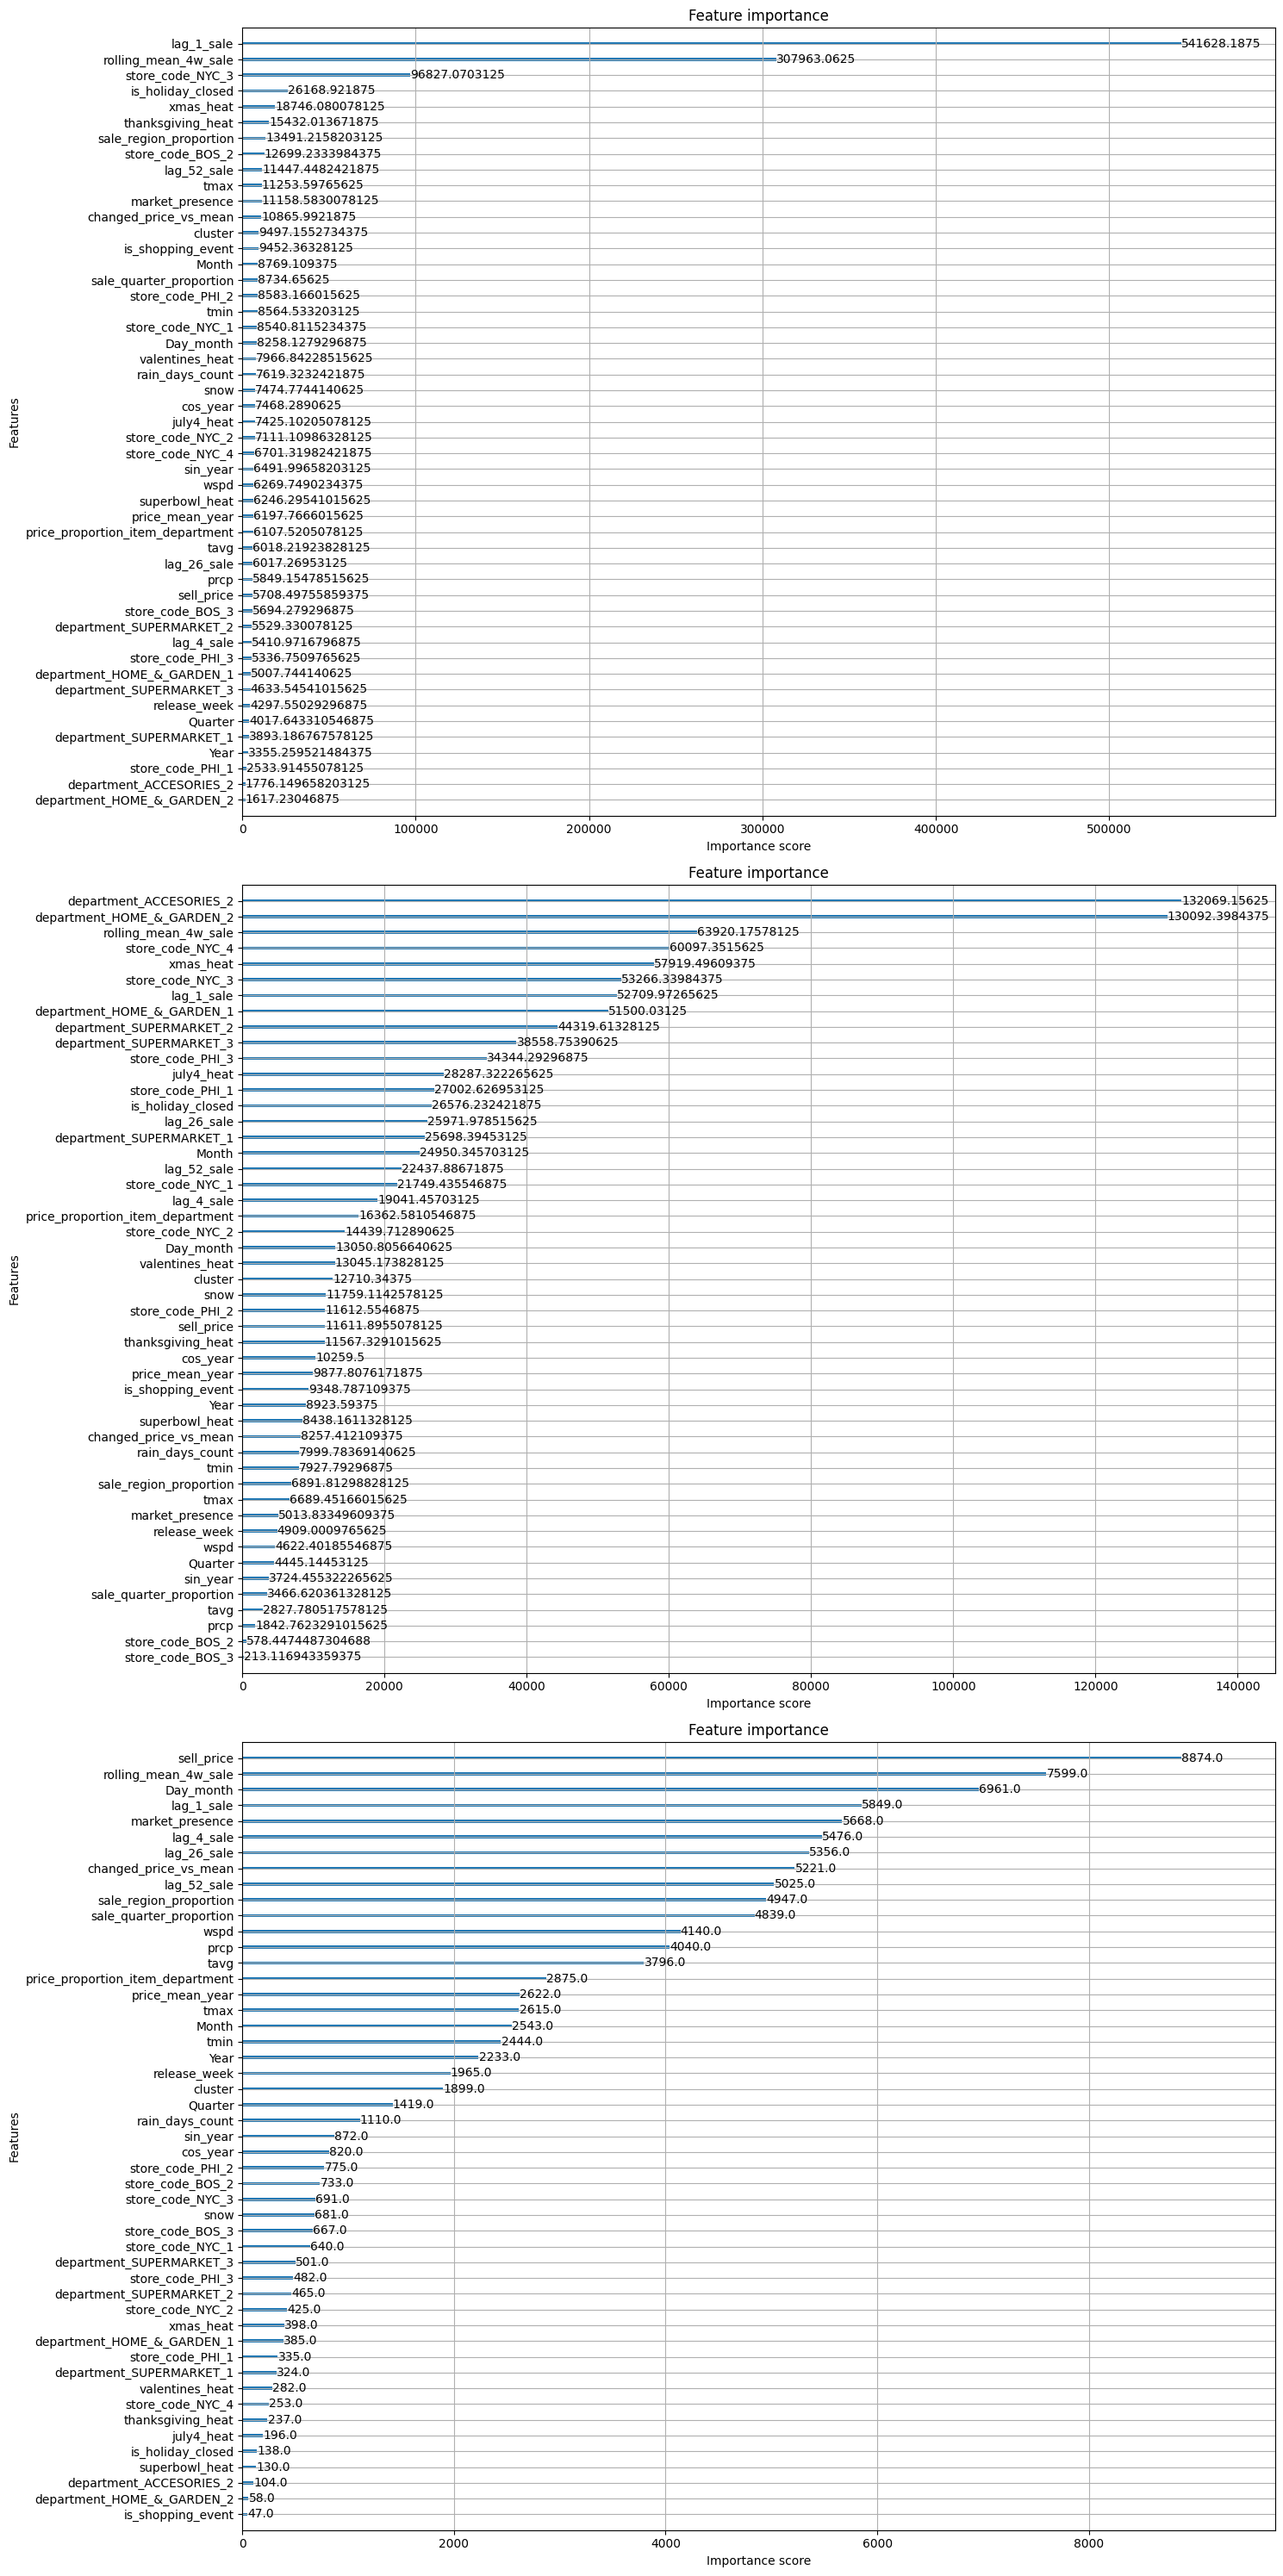

In [ ]:
fig = plt.figure(figsize=(15, 30))
ax1, ax2, ax3 = fig.subplots(3, 1)
xgb.plot_importance(booster = model, ax = ax1, importance_type = "gain")
xgb.plot_importance(booster = model, ax = ax2, importance_type = "cover")
xgb.plot_importance(booster = model, ax = ax3, importance_type = "weight")
plt.tight_layout();

### Random feature-subset search

In [ ]:
results = {}

In [ ]:
df_weekly.shape

(5927218, 52)

In [ ]:
columnas = df_weekly.columns
meta_data = ['unique_id', 'week_number', 'sale']
list_features = list(set(columnas) - set(meta_data))
print(list_features)

['lag_26_sale', 'sell_price', 'department_ACCESORIES_2', 'july4_heat', 'valentines_heat', 'tmax', 'tavg', 'department_SUPERMARKET_1', 'store_code_PHI_1', 'department_HOME_&_GARDEN_2', 'store_code_NYC_3', 'lag_4_sale', 'market_presence', 'store_code_NYC_1', 'tmin', 'changed_price_vs_mean', 'sale_region_proportion', 'prcp', 'superbowl_heat', 'lag_1_sale', 'thanksgiving_heat', 'xmas_heat', 'price_proportion_item_department', 'cluster', 'cos_year', 'store_code_BOS_2', 'store_code_NYC_2', 'store_code_PHI_3', 'sale_quarter_proportion', 'lag_52_sale', 'department_SUPERMARKET_3', 'department_SUPERMARKET_2', 'wspd', 'Month', 'store_code_PHI_2', 'sin_year', 'is_holiday_closed', 'rolling_mean_4w_sale', 'Year', 'price_mean_year', 'Quarter', 'store_code_BOS_3', 'snow', 'release_week', 'rain_days_count', 'department_HOME_&_GARDEN_1', 'store_code_NYC_4', 'Day_month', 'is_shopping_event']


In [ ]:
def select_features(list_features):
  import random
  # Pick a random number of features
  k = random.randint(10, 20)
  features_selected = random.sample(list_features, k)
  return features_selected

In [ ]:
# Training loop with random feature subsets
for i in range(1, 100):
  print(i)
  features_selected = select_features(list_features)
  x_train_i = x_train[features_selected]
  x_val_i = x_val[features_selected]
  model = xgb.XGBRegressor( random_state = 42,
    objective='reg:squarederror',
    n_estimators=15,
    max_depth=10
  )
  model.fit(
    X = x_train_i,
    y = y_train
    #eval_set = [(X_train, y_train), (X_test, y_test)],
    #early_stopping_rounds = 20
  )
  y_train_pred = model.predict(x_train_i)
  rmse_train = root_mean_squared_error(y_true = y_train, y_pred=y_train_pred)
  y_val_pred = model.predict(x_val_i)
  rmse_test = root_mean_squared_error(y_true = y_val, y_pred=y_val_pred)
  results[i] = [list(set(features_selected) - set(meta_data)), rmse_train, rmse_test]
  

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


In [ ]:
df_results = pd.DataFrame.from_dict(results, orient='index', columns=['features', 'rmse_train', 'rmse_test'])
df_results.sort_values(by='rmse_test', inplace=True)
df_results['rmse_test'].min()

8.200313568115234

In [ ]:
df_results

,features,rmse_train,rmse_test
7,"[department_SUPERMARKET_3, wspd, Month, store_...",8.578605,8.200314
44,"[lag_52_sale, department_SUPERMARKET_2, depart...",9.713314,8.315386
64,"[snow, lag_26_sale, department_ACCESORIES_2, c...",9.165411,8.331149
82,"[lag_52_sale, department_SUPERMARKET_3, lag_26...",9.415110,8.587355
80,"[lag_26_sale, sell_price, store_code_PHI_2, va...",9.154408,8.657762
...,...,...,...
50,"[department_ACCESORIES_2, valentines_heat, dep...",22.853504,19.038788
26,"[store_code_NYC_3, market_presence, department...",21.985283,19.046444
54,"[Quarter, cluster, market_presence, snow, is_h...",24.244045,19.152710
33,"[store_code_NYC_3, department_SUPERMARKET_2, j...",25.442629,19.315842


In [ ]:
best_features = df_results[df_results['rmse_test'] < 9]['features']

In [ ]:
best_features.shape

(17,)

In [ ]:
dict_features = {}
for features in best_features:
    # Count how often each feature appears
    for feature in features:
        dict_features[feature] = dict_features.get(feature, 0) + 1

In [ ]:
# Convert to a DataFrame for easier inspection
dict_features_df = pd.DataFrame.from_dict(dict_features, orient='index', columns=['count'])
dict_features_df.sort_values(by='count', ascending=False, inplace=True)
dict_features_df

,count
rolling_mean_4w_sale,16
tavg,10
Quarter,10
department_HOME_&_GARDEN_1,9
Month,9
store_code_PHI_2,9
xmas_heat,9
Day_month,9
lag_1_sale,9
release_week,8


In [ ]:
df_results.tail(15)

,features,rmse_train,rmse_test
41,"[Quarter, store_code_NYC_3, department_SUPERMA...",18.663218,17.008808
2,"[store_code_BOS_3, department_SUPERMARKET_3, s...",17.769043,17.220089
29,"[department_SUPERMARKET_3, department_SUPERMAR...",21.879961,17.559069
75,"[Quarter, store_code_BOS_3, department_SUPERMA...",17.057289,17.710155
38,"[department_SUPERMARKET_3, tmax, tavg, store_c...",21.508862,17.823734
87,"[store_code_BOS_3, market_presence, sell_price...",22.724815,17.868967
66,"[store_code_NYC_3, department_SUPERMARKET_3, s...",22.543125,18.122877
52,"[store_code_BOS_3, snow, changed_price_vs_mean...",21.175306,18.161551
85,"[store_code_NYC_3, store_code_NYC_1, departmen...",22.548334,18.312582
8,"[store_code_NYC_1, sell_price, sale_region_pro...",18.750097,18.426012


In [ ]:
worst_features = df_results[df_results['rmse_test'] > 17]['features']

In [ ]:
worst_features.shape

(15,)

In [ ]:
dict_features_worst = {}
for features in worst_features:
    # Count how often each feature appears
    for feature in features:
        dict_features_worst[feature] = dict_features_worst.get(feature, 0) + 1

dict_features_df_worst = pd.DataFrame.from_dict(dict_features_worst, orient='index', columns=['count'])
dict_features_df_worst.sort_values(by='count', ascending=False, inplace=True)
dict_features_df_worst

,count
department_SUPERMARKET_1,8
superbowl_heat,7
prcp,7
store_code_NYC_3,7
store_code_BOS_3,7
department_SUPERMARKET_3,6
sale_quarter_proportion,6
market_presence,6
sell_price,6
store_code_PHI_1,6


In [ ]:
# Training loop with random feature subsets (2): more trees + early stopping
for i in range(1, 100):
  print(i)
  features_selected = select_features(list_features)
  x_train_i = x_train[features_selected]
  x_val_i = x_val[features_selected]
  model = xgb.XGBRegressor( random_state = 42,
    objective='reg:squarederror',
    n_estimators=1000,
    learning_rate=0.2,
    max_depth=8,
    n_jobs=-1,
    early_stopping_rounds = 20
  )
  model.fit(
    X = x_train_i,
    y = y_train,
    eval_set = [(x_train_i, y_train), (x_val_i, y_val)]
  )
  y_train_pred = model.predict(x_train_i)
  rmse_train = root_mean_squared_error(y_true = y_train, y_pred=y_train_pred)
  y_val_pred = model.predict(x_val_i)
  rmse_test = root_mean_squared_error(y_true = y_val, y_pred=y_val_pred)
  results[i] = [list(set(features_selected) - set(meta_data)), rmse_train, rmse_test]

In [ ]:
df_results_2 = pd.DataFrame.from_dict(results, orient='index', columns=['features', 'rmse_train', 'rmse_test'])
df_results_2 .sort_values(by='rmse_test', inplace=True)
df_results_2['rmse_test'].min()

8.315385818481445

In [ ]:
best_features_2 = df_results_2[df_results_2['rmse_test'] < 9]['features']
dict_features = {}
for features in best_features_2:
    # Count how often each feature appears
    for feature in features:
        dict_features[feature] = dict_features.get(feature, 0) + 1

# Convert to a DataFrame for easier inspection
dict_features_df = pd.DataFrame.from_dict(dict_features, orient='index', columns=['count'])
dict_features_df.sort_values(by='count', ascending=False, inplace=True)
dict_features_df

In [ ]:
worst_features_2 = df_results_2[df_results_2['rmse_test'] > 17]['features']

dict_features_worst = {}
for features in worst_features_2:
    # Count how often each feature appears
    for feature in features:
        dict_features_worst[feature] = dict_features_worst.get(feature, 0) + 1

dict_features_df_worst = pd.DataFrame.from_dict(dict_features_worst, orient='index', columns=['count'])
dict_features_df_worst.sort_values(by='count', ascending=False, inplace=True)
dict_features_df_worst

### Hyperparameter tuning with Optuna

- First study (next cell): `TimeSeriesSplit(n_splits=3)` on `x_train`, objective = mean RMSE over the folds. The rows of `x_train` are ordered by item and store, so the folds separate **products**, not periods (every fold covers weeks 53–253). It measures generalisation to unseen products, not to future weeks.
- Second study (cell after the splits): each trial is trained on the training weeks and scored on the **validation weeks 255–268** (chronological holdout), with early stopping. Its best parameters are the ones stored in `xgb_best_params` below.

In [ ]:
import optuna
import xgboost as xgb
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
import numpy as np

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def objective(trial):
    # 1. Search space
    params = {
        'objective': 'reg:squarederror',
        'n_jobs': -1,
        'random_state': 42,
        'max_depth': trial.suggest_int('max_depth', 5, 10),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 0.05, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True), # L1 Reg
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True), # L2 Reg
        'early_stopping_rounds': 30
    }
    
    # 2. Time-series cross-validation (TimeSeriesSplit, 3 folds) inside the training set
    tscv = TimeSeriesSplit(n_splits=3)
    scores = []
    
    for train_index, val_index in tscv.split(x_train):
        X_tr, X_val = x_train.iloc[train_index], x_train.iloc[val_index]
        y_tr, y_val = y_train.iloc[train_index], y_train.iloc[val_index]
        
        model = xgb.XGBRegressor(**params)
        
        # Early stopping on the fold's validation part
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )
        
        preds = model.predict(X_val)
        rmse = root_mean_squared_error(y_val, preds)
        scores.append(rmse)
    
    # Return the mean RMSE over the 3 folds
    return np.mean(scores)

# 3. Create the study and optimise
study = optuna.create_study(direction='minimize') # Minimise RMSE
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best RMSE:", study.best_value)


[I 2025-12-06 20:42:30,885] A new study created in memory with name: no-name-ef2182fc-65b3-425d-9dee-feb3e17c5bf9
[I 2025-12-06 20:43:23,329] Trial 0 finished with value: 14.156408468882242 and parameters: {'max_depth': 6, 'n_estimators': 962, 'learning_rate': 0.2254053501885006, 'subsample': 0.7584783882123884, 'colsample_bytree': 0.755353898083946, 'reg_alpha': 5.345367807841636, 'reg_lambda': 0.003220727208968581}. Best is trial 0 with value: 14.156408468882242.
[I 2025-12-06 20:44:24,008] Trial 1 finished with value: 14.465975602467855 and parameters: {'max_depth': 8, 'n_estimators': 551, 'learning_rate': 0.13787782361718942, 'subsample': 0.8253515193065726, 'colsample_bytree': 0.706051876672831, 'reg_alpha': 0.5212411538892168, 'reg_lambda': 1.3925195768708856}. Best is trial 0 with value: 14.156408468882242.
[I 2025-12-06 20:45:11,756] Trial 2 finished with value: 14.45655616124471 and parameters: {'max_depth': 7, 'n_estimators': 1043, 'learning_rate': 0.27667290110821774, 'subsa

Best params: {'max_depth': 5, 'n_estimators': 1057, 'learning_rate': 0.05139080593593561, 'subsample': 0.7729883858027786, 'colsample_bytree': 0.981989176385692, 'reg_alpha': 0.0004543203092688791, 'reg_lambda': 0.0015921253852591447}
Best RMSE: 13.875595092773438


In [ ]:
# Rebuild the chronological splits
train_dates = range(min_week, week_number_val - 1)
val_dates = range(week_number_val, week_number_test - 1)
#test_dates = range(week_number_test, max_week_test)

x_train, y_train = get_data_splits(df_weekly, train_dates)
x_val, y_val = get_data_splits(df_weekly, val_dates)
#x_test, y_test = get_data_splits(df_weekly, test_dates)

range(53, 254)
(5134765, 49) (5134765,)
range(255, 269)
(426602, 49) (426602,)


In [ ]:
import optuna
from sklearn.metrics import mean_squared_error
import numpy as np

def objective(trial):
    params = {
        'objective': 'reg:squarederror',
        'random_state': 42,
        'verbosity': 0,
        
        # Parameters to tune
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma': trial.suggest_float('gamma', 0, 5),
        
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.6, 1.0),
        
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 10),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 10),
        
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'early_stopping_rounds': 20
    }
    
    model = xgb.XGBRegressor(**params)
    
    model.fit(
        x_train, y_train,
        eval_set=[(x_train, y_train), (x_val, y_val)], # Early stopping on the validation holdout
        verbose=False
    )
    
    # Predict on the validation holdout
    y_pred = model.predict(x_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    return rmse

# Run the optimisation
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

print("Best parameters:")
print(study.best_params)
print(f"\nBest RMSE: {study.best_value:.4f}")

[I 2025-12-06 22:22:15,636] A new study created in memory with name: no-name-b395ae45-8ded-487e-ac65-b985a9fdc1ad
Best trial: 0. Best value: 8.15065:   1%|          | 1/100 [01:20<2:13:14, 80.76s/it]

[I 2025-12-06 22:23:36,384] Trial 0 finished with value: 8.150647808142786 and parameters: {'max_depth': 6, 'min_child_weight': 1, 'gamma': 4.691561221203874, 'subsample': 0.751433138391618, 'colsample_bytree': 0.7301929692287359, 'colsample_bylevel': 0.7230163258525806, 'reg_alpha': 8.912592729281382, 'reg_lambda': 4.202576641593351, 'learning_rate': 0.01023927358588922, 'n_estimators': 446}. Best is trial 0 with value: 8.150647808142786.


Best trial: 1. Best value: 7.78976:   2%|▏         | 2/100 [02:08<1:40:10, 61.33s/it]

[I 2025-12-06 22:24:24,125] Trial 1 finished with value: 7.7897571801083005 and parameters: {'max_depth': 15, 'min_child_weight': 8, 'gamma': 2.062282685392267, 'subsample': 0.9425015069541482, 'colsample_bytree': 0.8198546464158343, 'colsample_bylevel': 0.7660381949648387, 'reg_alpha': 8.27616738990778, 'reg_lambda': 7.061672558267999, 'learning_rate': 0.11299512920821106, 'n_estimators': 321}. Best is trial 1 with value: 7.7897571801083005.


Best trial: 2. Best value: 7.77488:   3%|▎         | 3/100 [02:31<1:11:06, 43.99s/it]

[I 2025-12-06 22:24:47,473] Trial 2 finished with value: 7.774877918916331 and parameters: {'max_depth': 11, 'min_child_weight': 5, 'gamma': 2.8678027174061764, 'subsample': 0.9393225125890944, 'colsample_bytree': 0.7501588764661697, 'colsample_bylevel': 0.9878538489513768, 'reg_alpha': 7.2546090703237365, 'reg_lambda': 3.4413676966856324, 'learning_rate': 0.16856218760774058, 'n_estimators': 314}. Best is trial 2 with value: 7.774877918916331.


Best trial: 2. Best value: 7.77488:   4%|▍         | 4/100 [03:07<1:05:21, 40.85s/it]

[I 2025-12-06 22:25:23,515] Trial 3 finished with value: 7.793046580908332 and parameters: {'max_depth': 7, 'min_child_weight': 9, 'gamma': 1.5103390117286568, 'subsample': 0.7585599538806225, 'colsample_bytree': 0.686234233539563, 'colsample_bylevel': 0.694700423400543, 'reg_alpha': 7.693349737828667, 'reg_lambda': 4.868379076633059, 'learning_rate': 0.15823508462169342, 'n_estimators': 307}. Best is trial 2 with value: 7.774877918916331.


Best trial: 2. Best value: 7.77488:   5%|▌         | 5/100 [03:45<1:02:55, 39.74s/it]

[I 2025-12-06 22:26:01,294] Trial 4 finished with value: 8.071121692249086 and parameters: {'max_depth': 3, 'min_child_weight': 2, 'gamma': 0.26957189557660743, 'subsample': 0.6562674535113232, 'colsample_bytree': 0.9111141587955819, 'colsample_bylevel': 0.6310730795966243, 'reg_alpha': 5.2790011291146595, 'reg_lambda': 4.147275163831587, 'learning_rate': 0.21875667676857333, 'n_estimators': 355}. Best is trial 2 with value: 7.774877918916331.


Best trial: 5. Best value: 7.74137:   6%|▌         | 6/100 [04:51<1:16:00, 48.52s/it]

[I 2025-12-06 22:27:06,837] Trial 5 finished with value: 7.741374476420818 and parameters: {'max_depth': 14, 'min_child_weight': 9, 'gamma': 2.8409307544854694, 'subsample': 0.8489499961031525, 'colsample_bytree': 0.6244030826431268, 'colsample_bylevel': 0.712528345123284, 'reg_alpha': 9.864413421264528, 'reg_lambda': 4.712467584304454, 'learning_rate': 0.05868958292366275, 'n_estimators': 138}. Best is trial 5 with value: 7.741374476420818.


Best trial: 5. Best value: 7.74137:   7%|▋         | 7/100 [06:31<1:41:39, 65.59s/it]

[I 2025-12-06 22:28:47,574] Trial 6 finished with value: 7.752742897221597 and parameters: {'max_depth': 13, 'min_child_weight': 1, 'gamma': 4.030834498006245, 'subsample': 0.8657991522454946, 'colsample_bytree': 0.6657963549010165, 'colsample_bylevel': 0.9476466317048388, 'reg_alpha': 1.675587288369802, 'reg_lambda': 0.6162701370471146, 'learning_rate': 0.047379062276952856, 'n_estimators': 323}. Best is trial 5 with value: 7.741374476420818.


Best trial: 7. Best value: 7.70517:   8%|▊         | 8/100 [09:19<2:30:14, 97.98s/it]

[I 2025-12-06 22:31:34,920] Trial 7 finished with value: 7.705173428989173 and parameters: {'max_depth': 11, 'min_child_weight': 3, 'gamma': 3.4432079700113007, 'subsample': 0.7721865673696865, 'colsample_bytree': 0.8371062129551794, 'colsample_bylevel': 0.6828296067411239, 'reg_alpha': 3.6953260660078957, 'reg_lambda': 3.429216372765956, 'learning_rate': 0.011227286995762236, 'n_estimators': 490}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:   9%|▉         | 9/100 [10:26<2:14:14, 88.51s/it]

[I 2025-12-06 22:32:42,616] Trial 8 finished with value: 7.795226020203307 and parameters: {'max_depth': 15, 'min_child_weight': 6, 'gamma': 3.7069959251398226, 'subsample': 0.8244370780885437, 'colsample_bytree': 0.9243963211077575, 'colsample_bylevel': 0.8737998532409904, 'reg_alpha': 1.7911383576959272, 'reg_lambda': 9.092722633597061, 'learning_rate': 0.1157892063766515, 'n_estimators': 179}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  10%|█         | 10/100 [11:17<1:55:13, 76.82s/it]

[I 2025-12-06 22:33:33,250] Trial 9 finished with value: 8.084104940285403 and parameters: {'max_depth': 5, 'min_child_weight': 9, 'gamma': 4.539148785407608, 'subsample': 0.9889342563419689, 'colsample_bytree': 0.964327512328828, 'colsample_bylevel': 0.9021252200376172, 'reg_alpha': 8.052276924691524, 'reg_lambda': 0.43880195305176395, 'learning_rate': 0.02753265783619027, 'n_estimators': 323}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  11%|█         | 11/100 [13:29<2:18:54, 93.65s/it]

[I 2025-12-06 22:35:45,040] Trial 10 finished with value: 7.751209779883254 and parameters: {'max_depth': 9, 'min_child_weight': 4, 'gamma': 0.9550797941663469, 'subsample': 0.6357704130431108, 'colsample_bytree': 0.8390940371299566, 'colsample_bylevel': 0.6154311818955214, 'reg_alpha': 3.496848184098849, 'reg_lambda': 1.9528978788981344, 'learning_rate': 0.012433317776399153, 'n_estimators': 490}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  12%|█▏        | 12/100 [14:05<1:51:37, 76.10s/it]

[I 2025-12-06 22:36:21,031] Trial 11 finished with value: 7.918934413626271 and parameters: {'max_depth': 12, 'min_child_weight': 7, 'gamma': 3.2007821001706795, 'subsample': 0.7190791742598498, 'colsample_bytree': 0.6094608560074452, 'colsample_bylevel': 0.8094957085434553, 'reg_alpha': 5.129447613090662, 'reg_lambda': 6.747539443263072, 'learning_rate': 0.04634093270894658, 'n_estimators': 87}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  13%|█▎        | 13/100 [15:04<1:42:45, 70.87s/it]

[I 2025-12-06 22:37:19,845] Trial 12 finished with value: 7.814672061338821 and parameters: {'max_depth': 10, 'min_child_weight': 3, 'gamma': 2.2696697022572017, 'subsample': 0.849594853109473, 'colsample_bytree': 0.8624044707061789, 'colsample_bylevel': 0.6854120284577048, 'reg_alpha': 3.6241633350576654, 'reg_lambda': 2.4920256041335946, 'learning_rate': 0.02234240773451059, 'n_estimators': 193}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  14%|█▍        | 14/100 [15:30<1:22:29, 57.55s/it]

[I 2025-12-06 22:37:46,630] Trial 13 finished with value: 7.847209030935478 and parameters: {'max_depth': 13, 'min_child_weight': 10, 'gamma': 3.3011262570515942, 'subsample': 0.7960123502558749, 'colsample_bytree': 0.790836596350117, 'colsample_bylevel': 0.7944406272915308, 'reg_alpha': 9.92811776970498, 'reg_lambda': 5.929233757190639, 'learning_rate': 0.07452244551482239, 'n_estimators': 54}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  15%|█▌        | 15/100 [16:29<1:22:08, 57.99s/it]

[I 2025-12-06 22:38:45,627] Trial 14 finished with value: 7.7577325945500935 and parameters: {'max_depth': 9, 'min_child_weight': 4, 'gamma': 2.5191252495216485, 'subsample': 0.886921748268077, 'colsample_bytree': 0.607240629042634, 'colsample_bylevel': 0.6632898343491354, 'reg_alpha': 0.27533941791639016, 'reg_lambda': 2.5264014227332234, 'learning_rate': 0.025329719038123373, 'n_estimators': 225}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  16%|█▌        | 16/100 [17:35<1:24:12, 60.15s/it]

[I 2025-12-06 22:39:50,807] Trial 15 finished with value: 7.741998541226517 and parameters: {'max_depth': 14, 'min_child_weight': 6, 'gamma': 4.002271228411485, 'subsample': 0.7073175686687447, 'colsample_bytree': 0.7563740945442331, 'colsample_bylevel': 0.7609334533845565, 'reg_alpha': 6.468533062791313, 'reg_lambda': 8.455326423927943, 'learning_rate': 0.06974728550621886, 'n_estimators': 404}. Best is trial 7 with value: 7.705173428989173.


Best trial: 7. Best value: 7.70517:  17%|█▋        | 17/100 [18:25<1:19:00, 57.11s/it]

[I 2025-12-06 22:40:40,858] Trial 16 finished with value: 8.225001985033717 and parameters: {'max_depth': 11, 'min_child_weight': 3, 'gamma': 1.909982280861152, 'subsample': 0.7894089583653966, 'colsample_bytree': 0.8870000905240912, 'colsample_bylevel': 0.7411157824196538, 'reg_alpha': 3.700206819674481, 'reg_lambda': 5.728454547472051, 'learning_rate': 0.019161859885919955, 'n_estimators': 129}. Best is trial 7 with value: 7.705173428989173.


Best trial: 17. Best value: 7.63321:  18%|█▊        | 18/100 [20:10<1:37:46, 71.55s/it]

[I 2025-12-06 22:42:25,995] Trial 17 finished with value: 7.633205813657349 and parameters: {'max_depth': 13, 'min_child_weight': 7, 'gamma': 2.862764274062739, 'subsample': 0.9043730750103178, 'colsample_bytree': 0.6703818026593007, 'colsample_bylevel': 0.8315781383282412, 'reg_alpha': 6.078279231148782, 'reg_lambda': 3.2524343199628563, 'learning_rate': 0.03425599825962623, 'n_estimators': 242}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  19%|█▉        | 19/100 [21:37<1:42:51, 76.19s/it]

[I 2025-12-06 22:43:53,009] Trial 18 finished with value: 7.8303701870106375 and parameters: {'max_depth': 11, 'min_child_weight': 7, 'gamma': 1.4097660071662093, 'subsample': 0.913636186483222, 'colsample_bytree': 0.6950536990982952, 'colsample_bylevel': 0.8250616922338052, 'reg_alpha': 6.084957996071268, 'reg_lambda': 1.6128895635494733, 'learning_rate': 0.014761896969133546, 'n_estimators': 247}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  20%|██        | 20/100 [22:55<1:42:14, 76.68s/it]

[I 2025-12-06 22:45:10,843] Trial 19 finished with value: 7.751440099000859 and parameters: {'max_depth': 8, 'min_child_weight': 5, 'gamma': 3.5994180907288493, 'subsample': 0.9828564311528308, 'colsample_bytree': 0.9890608914873757, 'colsample_bylevel': 0.8532672560612569, 'reg_alpha': 2.453949359457404, 'reg_lambda': 3.4882780079709357, 'learning_rate': 0.03419955008163589, 'n_estimators': 399}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  21%|██        | 21/100 [24:15<1:42:13, 77.64s/it]

[I 2025-12-06 22:46:30,726] Trial 20 finished with value: 7.75652506153841 and parameters: {'max_depth': 12, 'min_child_weight': 3, 'gamma': 4.211841954281966, 'subsample': 0.6023038355093263, 'colsample_bytree': 0.7829889842490084, 'colsample_bylevel': 0.9136615832839595, 'reg_alpha': 4.330224035992131, 'reg_lambda': 3.2654822294123784, 'learning_rate': 0.03747474231210993, 'n_estimators': 490}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  22%|██▏       | 22/100 [25:07<1:31:05, 70.07s/it]

[I 2025-12-06 22:47:23,121] Trial 21 finished with value: 7.686475980212569 and parameters: {'max_depth': 13, 'min_child_weight': 8, 'gamma': 2.820366421012719, 'subsample': 0.835438931890436, 'colsample_bytree': 0.6675004747596012, 'colsample_bylevel': 0.6532808156265675, 'reg_alpha': 9.201893505353528, 'reg_lambda': 4.717219180000382, 'learning_rate': 0.06884210452105846, 'n_estimators': 140}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  23%|██▎       | 23/100 [26:00<1:23:27, 65.04s/it]

[I 2025-12-06 22:48:16,427] Trial 22 finished with value: 7.693937506044862 and parameters: {'max_depth': 13, 'min_child_weight': 7, 'gamma': 2.82111860955755, 'subsample': 0.8993456791033071, 'colsample_bytree': 0.652876613835938, 'colsample_bylevel': 0.6543630995287152, 'reg_alpha': 6.5672912988662775, 'reg_lambda': 5.515056408224895, 'learning_rate': 0.08188309988373656, 'n_estimators': 272}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  24%|██▍       | 24/100 [26:52<1:17:29, 61.18s/it]

[I 2025-12-06 22:49:08,595] Trial 23 finished with value: 7.714997526157301 and parameters: {'max_depth': 13, 'min_child_weight': 7, 'gamma': 2.765680970324912, 'subsample': 0.8982886466940831, 'colsample_bytree': 0.6363593017690147, 'colsample_bylevel': 0.6435100584756914, 'reg_alpha': 6.480695510726971, 'reg_lambda': 5.848454052812461, 'learning_rate': 0.08643646116758708, 'n_estimators': 249}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  25%|██▌       | 25/100 [27:51<1:15:34, 60.46s/it]

[I 2025-12-06 22:50:07,380] Trial 24 finished with value: 7.779310850398569 and parameters: {'max_depth': 14, 'min_child_weight': 8, 'gamma': 3.088565070563601, 'subsample': 0.9406148841349422, 'colsample_bytree': 0.6592067336302366, 'colsample_bylevel': 0.608312641502567, 'reg_alpha': 6.975702970819059, 'reg_lambda': 7.662597303955625, 'learning_rate': 0.08830597966621108, 'n_estimators': 206}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  26%|██▌       | 26/100 [28:09<58:43, 47.61s/it]  

[I 2025-12-06 22:50:25,010] Trial 25 finished with value: 7.802631218028989 and parameters: {'max_depth': 12, 'min_child_weight': 8, 'gamma': 2.3314794553205944, 'subsample': 0.8156013531549013, 'colsample_bytree': 0.7155049376912068, 'colsample_bylevel': 0.6560938963798381, 'reg_alpha': 8.892719861133006, 'reg_lambda': 5.1587767647985725, 'learning_rate': 0.2836853565872533, 'n_estimators': 155}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  27%|██▋       | 27/100 [30:13<1:25:46, 70.50s/it]

[I 2025-12-06 22:52:28,925] Trial 26 finished with value: 7.699853167434353 and parameters: {'max_depth': 15, 'min_child_weight': 10, 'gamma': 1.893278904677171, 'subsample': 0.8759394942127865, 'colsample_bytree': 0.6574617665748789, 'colsample_bylevel': 0.7759510120373653, 'reg_alpha': 5.7370340088964396, 'reg_lambda': 6.61559517473772, 'learning_rate': 0.03642666812508724, 'n_estimators': 269}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  28%|██▊       | 28/100 [30:46<1:11:00, 59.17s/it]

[I 2025-12-06 22:53:01,661] Trial 27 finished with value: 7.679607775129794 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 2.6768348420584824, 'subsample': 0.9151559648040432, 'colsample_bytree': 0.7151626326141136, 'colsample_bylevel': 0.8397331500983582, 'reg_alpha': 8.912644524925739, 'reg_lambda': 4.086028748190311, 'learning_rate': 0.05534977778883238, 'n_estimators': 107}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  29%|██▉       | 29/100 [31:18<1:00:31, 51.15s/it]

[I 2025-12-06 22:53:34,110] Trial 28 finished with value: 7.725203684865289 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 1.5245927336849088, 'subsample': 0.9700584889393075, 'colsample_bytree': 0.6987525431433348, 'colsample_bylevel': 0.8393674827964038, 'reg_alpha': 8.681526784201257, 'reg_lambda': 4.194833752774373, 'learning_rate': 0.05356904016404718, 'n_estimators': 108}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  30%|███       | 30/100 [31:31<46:10, 39.58s/it]  

[I 2025-12-06 22:53:46,673] Trial 29 finished with value: 8.338423839898585 and parameters: {'max_depth': 6, 'min_child_weight': 8, 'gamma': 4.821699326972588, 'subsample': 0.8332779765650714, 'colsample_bytree': 0.7510131573780399, 'colsample_bylevel': 0.7332925190751405, 'reg_alpha': 9.565391189190382, 'reg_lambda': 4.264116679117656, 'learning_rate': 0.06321204840754449, 'n_estimators': 52}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  31%|███       | 31/100 [32:09<45:09, 39.27s/it]

[I 2025-12-06 22:54:25,237] Trial 30 finished with value: 7.817345421229284 and parameters: {'max_depth': 8, 'min_child_weight': 5, 'gamma': 2.4888136873403583, 'subsample': 0.9200679186348953, 'colsample_bytree': 0.7174982906928652, 'colsample_bylevel': 0.8611552663797507, 'reg_alpha': 9.176663151536978, 'reg_lambda': 2.579374501919548, 'learning_rate': 0.03085073323270932, 'n_estimators': 165}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  32%|███▏      | 32/100 [32:46<43:39, 38.53s/it]

[I 2025-12-06 22:55:02,029] Trial 31 finished with value: 7.745904640278568 and parameters: {'max_depth': 13, 'min_child_weight': 7, 'gamma': 2.6971841997812267, 'subsample': 0.9000544035360053, 'colsample_bytree': 0.6777916159870282, 'colsample_bylevel': 0.8833088646893003, 'reg_alpha': 7.242279561031237, 'reg_lambda': 5.210764721703825, 'learning_rate': 0.10168826316720177, 'n_estimators': 104}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  33%|███▎      | 33/100 [33:55<53:15, 47.70s/it]

[I 2025-12-06 22:56:11,112] Trial 32 finished with value: 7.64439626661294 and parameters: {'max_depth': 12, 'min_child_weight': 7, 'gamma': 3.0230224044767366, 'subsample': 0.9557716674003991, 'colsample_bytree': 0.6445854685769531, 'colsample_bylevel': 0.7985551555095981, 'reg_alpha': 7.922719589463762, 'reg_lambda': 4.012391250476351, 'learning_rate': 0.044142212189712975, 'n_estimators': 210}. Best is trial 17 with value: 7.633205813657349.


Best trial: 17. Best value: 7.63321:  34%|███▍      | 34/100 [34:53<55:50, 50.77s/it]

[I 2025-12-06 22:57:09,057] Trial 33 finished with value: 7.637720472584342 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 3.004696199439377, 'subsample': 0.9551017640462444, 'colsample_bytree': 0.633809706470487, 'colsample_bylevel': 0.7966669744658087, 'reg_alpha': 8.227210604445824, 'reg_lambda': 3.794365921247457, 'learning_rate': 0.043239808445518356, 'n_estimators': 218}. Best is trial 17 with value: 7.633205813657349.


Best trial: 34. Best value: 7.61799:  35%|███▌      | 35/100 [35:59<1:00:07, 55.49s/it]

[I 2025-12-06 22:58:15,577] Trial 34 finished with value: 7.617987738413419 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 3.1153341593368977, 'subsample': 0.9556071514579838, 'colsample_bytree': 0.6349213770164802, 'colsample_bylevel': 0.7957184341058604, 'reg_alpha': 8.210714344897124, 'reg_lambda': 1.1515037646056587, 'learning_rate': 0.04405971264771674, 'n_estimators': 220}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  36%|███▌      | 36/100 [36:50<57:37, 54.02s/it]  

[I 2025-12-06 22:59:06,157] Trial 35 finished with value: 7.686364314851023 and parameters: {'max_depth': 8, 'min_child_weight': 5, 'gamma': 3.119110051366459, 'subsample': 0.9604480250899341, 'colsample_bytree': 0.6348184009675316, 'colsample_bylevel': 0.7884690256184588, 'reg_alpha': 7.766272263739679, 'reg_lambda': 1.0957176637395751, 'learning_rate': 0.0423869293472177, 'n_estimators': 220}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  37%|███▋      | 37/100 [38:13<1:05:42, 62.58s/it]

[I 2025-12-06 23:00:28,705] Trial 36 finished with value: 7.7305272250978145 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 3.843442684809201, 'subsample': 0.9486717539154017, 'colsample_bytree': 0.6031888365429325, 'colsample_bylevel': 0.7597104631222712, 'reg_alpha': 8.353940209787075, 'reg_lambda': 1.654078635039423, 'learning_rate': 0.021573564643077515, 'n_estimators': 296}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  38%|███▊      | 38/100 [39:24<1:07:17, 65.12s/it]

[I 2025-12-06 23:01:39,752] Trial 37 finished with value: 7.691067743868304 and parameters: {'max_depth': 11, 'min_child_weight': 7, 'gamma': 4.4355822924805555, 'subsample': 0.9886994854547085, 'colsample_bytree': 0.6338524216988095, 'colsample_bylevel': 0.8148562384891281, 'reg_alpha': 7.297212963137728, 'reg_lambda': 2.990745106639452, 'learning_rate': 0.043145843760297196, 'n_estimators': 245}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  39%|███▉      | 39/100 [40:40<1:09:41, 68.54s/it]

[I 2025-12-06 23:02:56,286] Trial 38 finished with value: 7.838324018901806 and parameters: {'max_depth': 12, 'min_child_weight': 5, 'gamma': 3.4225543450751736, 'subsample': 0.9643568316378899, 'colsample_bytree': 0.6849392437936943, 'colsample_bylevel': 0.7143274170288518, 'reg_alpha': 8.186756856591641, 'reg_lambda': 0.8936242829469507, 'learning_rate': 0.01833235383782517, 'n_estimators': 194}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  40%|████      | 40/100 [42:04<1:13:12, 73.20s/it]

[I 2025-12-06 23:04:20,350] Trial 39 finished with value: 7.673133389508069 and parameters: {'max_depth': 9, 'min_child_weight': 4, 'gamma': 3.0170381377784237, 'subsample': 0.9324041227591646, 'colsample_bytree': 0.624388721831743, 'colsample_bylevel': 0.7821077830755228, 'reg_alpha': 7.541933214356131, 'reg_lambda': 0.010392494170543554, 'learning_rate': 0.029114927216191806, 'n_estimators': 345}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  41%|████      | 41/100 [42:32<58:32, 59.53s/it]  

[I 2025-12-06 23:04:47,989] Trial 40 finished with value: 8.198855380674955 and parameters: {'max_depth': 3, 'min_child_weight': 6, 'gamma': 3.5971482509962316, 'subsample': 0.9513484374979949, 'colsample_bytree': 0.7333890689350389, 'colsample_bylevel': 0.8247726863814628, 'reg_alpha': 5.6416517925327305, 'reg_lambda': 3.8400843867578196, 'learning_rate': 0.12415762336337537, 'n_estimators': 221}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  42%|████▏     | 42/100 [43:59<1:05:39, 67.91s/it]

[I 2025-12-06 23:06:15,466] Trial 41 finished with value: 7.654862507806899 and parameters: {'max_depth': 9, 'min_child_weight': 4, 'gamma': 3.0083712558974045, 'subsample': 0.9979735041989802, 'colsample_bytree': 0.6217675500382633, 'colsample_bylevel': 0.7864848690440451, 'reg_alpha': 7.595362523436826, 'reg_lambda': 0.12351980152242781, 'learning_rate': 0.030003747548346105, 'n_estimators': 359}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  43%|████▎     | 43/100 [44:56<1:01:14, 64.47s/it]

[I 2025-12-06 23:07:11,888] Trial 42 finished with value: 7.749285265051263 and parameters: {'max_depth': 7, 'min_child_weight': 4, 'gamma': 2.2306743021466, 'subsample': 0.996913382984708, 'colsample_bytree': 0.6470212527751071, 'colsample_bylevel': 0.7556486781657851, 'reg_alpha': 6.796612270705946, 'reg_lambda': 0.038313158597240715, 'learning_rate': 0.05025956351763267, 'n_estimators': 297}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  44%|████▍     | 44/100 [46:30<1:08:32, 73.44s/it]

[I 2025-12-06 23:08:46,272] Trial 43 finished with value: 7.665996218128302 and parameters: {'max_depth': 9, 'min_child_weight': 5, 'gamma': 3.010777983140726, 'subsample': 0.9704756959004341, 'colsample_bytree': 0.6215267634889862, 'colsample_bylevel': 0.8117404364029928, 'reg_alpha': 7.860145808654799, 'reg_lambda': 1.3800866341246718, 'learning_rate': 0.03926126593880732, 'n_estimators': 419}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  45%|████▌     | 45/100 [48:02<1:12:20, 78.92s/it]

[I 2025-12-06 23:10:17,984] Trial 44 finished with value: 7.648648221130038 and parameters: {'max_depth': 10, 'min_child_weight': 1, 'gamma': 3.3635879713276693, 'subsample': 0.9311529920452069, 'colsample_bytree': 0.6035572485542089, 'colsample_bylevel': 0.7985438280579883, 'reg_alpha': 8.1405439926371, 'reg_lambda': 2.055909773476353, 'learning_rate': 0.03179508551035843, 'n_estimators': 358}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  46%|████▌     | 46/100 [49:02<1:06:05, 73.44s/it]

[I 2025-12-06 23:11:18,633] Trial 45 finished with value: 7.79532120077749 and parameters: {'max_depth': 11, 'min_child_weight': 2, 'gamma': 3.4449415844466174, 'subsample': 0.9320310083058019, 'colsample_bytree': 0.6022084606556581, 'colsample_bylevel': 0.9760133255578928, 'reg_alpha': 8.632427731552513, 'reg_lambda': 2.211761007494581, 'learning_rate': 0.02511167732039435, 'n_estimators': 175}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  47%|████▋     | 47/100 [50:17<1:05:07, 73.73s/it]

[I 2025-12-06 23:12:33,031] Trial 46 finished with value: 7.640037841703158 and parameters: {'max_depth': 10, 'min_child_weight': 9, 'gamma': 3.8430130549657378, 'subsample': 0.8736420999356647, 'colsample_bytree': 0.6744912232493386, 'colsample_bylevel': 0.8958570186520218, 'reg_alpha': 8.238304544716378, 'reg_lambda': 3.060900632174526, 'learning_rate': 0.03351287369419788, 'n_estimators': 284}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  48%|████▊     | 48/100 [51:31<1:03:55, 73.75s/it]

[I 2025-12-06 23:13:46,843] Trial 47 finished with value: 7.667082180981359 and parameters: {'max_depth': 12, 'min_child_weight': 9, 'gamma': 3.8406939386636822, 'subsample': 0.8603320464908097, 'colsample_bytree': 0.6877954301540165, 'colsample_bylevel': 0.910210264417292, 'reg_alpha': 4.811014354411352, 'reg_lambda': 2.853550810753943, 'learning_rate': 0.04553523607146821, 'n_estimators': 282}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  49%|████▉     | 49/100 [52:28<58:29, 68.82s/it]  

[I 2025-12-06 23:14:44,140] Trial 48 finished with value: 7.701804398003588 and parameters: {'max_depth': 12, 'min_child_weight': 9, 'gamma': 4.295115099254572, 'subsample': 0.8869462634862867, 'colsample_bytree': 0.6771278431869365, 'colsample_bylevel': 0.9372165649337886, 'reg_alpha': 9.363104718034974, 'reg_lambda': 3.5902668692862663, 'learning_rate': 0.05510271218999453, 'n_estimators': 238}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  50%|█████     | 50/100 [53:29<55:16, 66.33s/it]

[I 2025-12-06 23:15:44,682] Trial 49 finished with value: 7.775565280787695 and parameters: {'max_depth': 10, 'min_child_weight': 9, 'gamma': 3.9952601569967037, 'subsample': 0.8719429958730487, 'colsample_bytree': 0.6463724146395412, 'colsample_bylevel': 0.8866996091406459, 'reg_alpha': 8.554342276289557, 'reg_lambda': 4.573494331939816, 'learning_rate': 0.0244487393942776, 'n_estimators': 200}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  51%|█████     | 51/100 [55:14<1:03:45, 78.07s/it]

[I 2025-12-06 23:17:30,140] Trial 50 finished with value: 7.670105895265077 and parameters: {'max_depth': 14, 'min_child_weight': 10, 'gamma': 2.5796149897761502, 'subsample': 0.978105453502717, 'colsample_bytree': 0.7634417693756275, 'colsample_bylevel': 0.8663803062112267, 'reg_alpha': 7.111139355173041, 'reg_lambda': 3.1084458644464688, 'learning_rate': 0.03648716399846996, 'n_estimators': 261}. Best is trial 34 with value: 7.617987738413419.


Best trial: 34. Best value: 7.61799:  52%|█████▏    | 52/100 [56:42<1:04:56, 81.17s/it]

[I 2025-12-06 23:18:58,529] Trial 51 finished with value: 7.671006784821236 and parameters: {'max_depth': 10, 'min_child_weight': 1, 'gamma': 3.296041197346507, 'subsample': 0.927052600282637, 'colsample_bytree': 0.6172467860461025, 'colsample_bylevel': 0.8022053241712935, 'reg_alpha': 7.99416185116946, 'reg_lambda': 1.9226733788553239, 'learning_rate': 0.032658284718282034, 'n_estimators': 339}. Best is trial 34 with value: 7.617987738413419.


Best trial: 52. Best value: 7.57842:  53%|█████▎    | 53/100 [58:22<1:07:49, 86.58s/it]

[I 2025-12-06 23:20:37,730] Trial 52 finished with value: 7.578419976539985 and parameters: {'max_depth': 11, 'min_child_weight': 7, 'gamma': 0.34352980122675136, 'subsample': 0.9488024055538419, 'colsample_bytree': 0.6659385144841371, 'colsample_bylevel': 0.8430795553001958, 'reg_alpha': 9.756099036859506, 'reg_lambda': 2.295519876131123, 'learning_rate': 0.04076040294813536, 'n_estimators': 372}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  54%|█████▍    | 54/100 [59:44<1:05:25, 85.34s/it]

[I 2025-12-06 23:22:00,195] Trial 53 finished with value: 7.644890778224783 and parameters: {'max_depth': 11, 'min_child_weight': 7, 'gamma': 0.32482295807001216, 'subsample': 0.9520571161974006, 'colsample_bytree': 0.7029790313782679, 'colsample_bylevel': 0.8411699207369093, 'reg_alpha': 9.682464980649673, 'reg_lambda': 3.703247020811925, 'learning_rate': 0.04127900294612719, 'n_estimators': 443}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  55%|█████▌    | 55/100 [1:00:47<58:56, 78.59s/it]  

[I 2025-12-06 23:23:03,014] Trial 54 finished with value: 7.727663893157199 and parameters: {'max_depth': 11, 'min_child_weight': 7, 'gamma': 0.05338697361395095, 'subsample': 0.7309330684722518, 'colsample_bytree': 0.6734866516289132, 'colsample_bylevel': 0.8258229297381862, 'reg_alpha': 6.01105091612256, 'reg_lambda': 2.656840477353281, 'learning_rate': 0.05909848358045859, 'n_estimators': 388}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  56%|█████▌    | 56/100 [1:02:00<56:29, 77.03s/it]

[I 2025-12-06 23:24:16,410] Trial 55 finished with value: 7.65496665942346 and parameters: {'max_depth': 12, 'min_child_weight': 6, 'gamma': 0.9204660445094013, 'subsample': 0.9091793675236793, 'colsample_bytree': 0.6660467157981882, 'colsample_bylevel': 0.9252226361950011, 'reg_alpha': 8.98765663381102, 'reg_lambda': 3.07293084992269, 'learning_rate': 0.04850211868557125, 'n_estimators': 224}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  57%|█████▋    | 57/100 [1:04:26<1:09:53, 97.52s/it]

[I 2025-12-06 23:26:41,729] Trial 56 finished with value: 7.682983808642149 and parameters: {'max_depth': 14, 'min_child_weight': 8, 'gamma': 3.618564225218559, 'subsample': 0.9450523552656955, 'colsample_bytree': 0.7359185906741037, 'colsample_bylevel': 0.8897839906868972, 'reg_alpha': 9.562807924786824, 'reg_lambda': 2.403465824417332, 'learning_rate': 0.018809630809680695, 'n_estimators': 315}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  58%|█████▊    | 58/100 [1:05:35<1:02:24, 89.15s/it]

[I 2025-12-06 23:27:51,359] Trial 57 finished with value: 7.72467061053478 and parameters: {'max_depth': 11, 'min_child_weight': 6, 'gamma': 2.0463589199598378, 'subsample': 0.8853229925081603, 'colsample_bytree': 0.6402322191229503, 'colsample_bylevel': 0.8540512724854139, 'reg_alpha': 9.869868407067766, 'reg_lambda': 0.7124971874825867, 'learning_rate': 0.06395709175008833, 'n_estimators': 285}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  59%|█████▉    | 59/100 [1:06:25<52:56, 77.48s/it]  

[I 2025-12-06 23:28:41,614] Trial 58 finished with value: 7.814341091658166 and parameters: {'max_depth': 9, 'min_child_weight': 8, 'gamma': 2.450920224350436, 'subsample': 0.8542844250482269, 'colsample_bytree': 0.6555449042894148, 'colsample_bylevel': 0.7454079798222231, 'reg_alpha': 8.380567295367456, 'reg_lambda': 1.3165856339573345, 'learning_rate': 0.02678849987596498, 'n_estimators': 176}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  60%|██████    | 60/100 [1:08:36<1:02:19, 93.49s/it]

[I 2025-12-06 23:30:52,463] Trial 59 finished with value: 7.683393668753604 and parameters: {'max_depth': 15, 'min_child_weight': 7, 'gamma': 0.6767992435933058, 'subsample': 0.9786678614321421, 'colsample_bytree': 0.8080711753005, 'colsample_bylevel': 0.7715263690050542, 'reg_alpha': 4.708347486014102, 'reg_lambda': 4.46722637594626, 'learning_rate': 0.03527441685460755, 'n_estimators': 256}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  61%|██████    | 61/100 [1:10:05<59:53, 92.13s/it]  

[I 2025-12-06 23:32:21,415] Trial 60 finished with value: 7.960213191182273 and parameters: {'max_depth': 12, 'min_child_weight': 7, 'gamma': 1.329545576284918, 'subsample': 0.674475858040564, 'colsample_bytree': 0.7084009074200414, 'colsample_bylevel': 0.8335341987628336, 'reg_alpha': 7.479166687983362, 'reg_lambda': 3.9358793813431925, 'learning_rate': 0.015494993644552119, 'n_estimators': 205}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  62%|██████▏   | 62/100 [1:12:00<1:02:33, 98.78s/it]

[I 2025-12-06 23:34:15,719] Trial 61 finished with value: 7.66533535994479 and parameters: {'max_depth': 11, 'min_child_weight': 7, 'gamma': 0.48305989639773156, 'subsample': 0.9535836090668515, 'colsample_bytree': 0.6999601528943072, 'colsample_bylevel': 0.8490792311225686, 'reg_alpha': 9.430177698117708, 'reg_lambda': 3.522573813005135, 'learning_rate': 0.04089936041685683, 'n_estimators': 455}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  63%|██████▎   | 63/100 [1:13:54<1:03:44, 103.38s/it]

[I 2025-12-06 23:36:09,813] Trial 62 finished with value: 7.617094350391981 and parameters: {'max_depth': 10, 'min_child_weight': 7, 'gamma': 0.22691021882178844, 'subsample': 0.9583915383922105, 'colsample_bytree': 0.6657236787223542, 'colsample_bylevel': 0.8748067186156125, 'reg_alpha': 9.951618109052257, 'reg_lambda': 3.714751592352673, 'learning_rate': 0.048252219723560065, 'n_estimators': 464}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  64%|██████▍   | 64/100 [1:15:06<56:21, 93.94s/it]   

[I 2025-12-06 23:37:21,750] Trial 63 finished with value: 7.636091826089105 and parameters: {'max_depth': 8, 'min_child_weight': 8, 'gamma': 0.26923486066299984, 'subsample': 0.909742142775477, 'colsample_bytree': 0.6627585203264735, 'colsample_bylevel': 0.8731638708051579, 'reg_alpha': 9.083821387839274, 'reg_lambda': 3.2931254944616577, 'learning_rate': 0.046745811877986404, 'n_estimators': 455}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  65%|██████▌   | 65/100 [1:16:15<50:29, 86.54s/it]

[I 2025-12-06 23:38:31,028] Trial 64 finished with value: 7.678217051493384 and parameters: {'max_depth': 8, 'min_child_weight': 8, 'gamma': 0.004511476475410253, 'subsample': 0.9090744120312036, 'colsample_bytree': 0.6862790981109446, 'colsample_bylevel': 0.8717589678218819, 'reg_alpha': 9.882318223720226, 'reg_lambda': 2.8651051832072616, 'learning_rate': 0.04852607854842297, 'n_estimators': 455}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  66%|██████▌   | 66/100 [1:17:09<43:27, 76.69s/it]

[I 2025-12-06 23:39:24,727] Trial 65 finished with value: 7.705925175239926 and parameters: {'max_depth': 7, 'min_child_weight': 9, 'gamma': 0.6819125610040548, 'subsample': 0.8961713139923309, 'colsample_bytree': 0.6631767426157399, 'colsample_bylevel': 0.9022652209802341, 'reg_alpha': 9.114138945212481, 'reg_lambda': 1.7563917998594074, 'learning_rate': 0.05084615832069998, 'n_estimators': 468}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  67%|██████▋   | 67/100 [1:18:03<38:33, 70.11s/it]

[I 2025-12-06 23:40:19,473] Trial 66 finished with value: 7.765647596483724 and parameters: {'max_depth': 7, 'min_child_weight': 8, 'gamma': 0.9194133749037401, 'subsample': 0.9217866048333652, 'colsample_bytree': 0.9145116683862405, 'colsample_bylevel': 0.9568945588094666, 'reg_alpha': 8.747675571694007, 'reg_lambda': 2.33180676379311, 'learning_rate': 0.07282514710662284, 'n_estimators': 434}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  68%|██████▊   | 68/100 [1:19:34<40:43, 76.35s/it]

[I 2025-12-06 23:41:50,399] Trial 67 finished with value: 7.636276411821677 and parameters: {'max_depth': 9, 'min_child_weight': 6, 'gamma': 0.2289905117053142, 'subsample': 0.9351816962158042, 'colsample_bytree': 0.6324645108908753, 'colsample_bylevel': 0.8765155706057827, 'reg_alpha': 0.17627262815204947, 'reg_lambda': 3.369428281745315, 'learning_rate': 0.03759890536793313, 'n_estimators': 395}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  69%|██████▉   | 69/100 [1:21:14<43:05, 83.41s/it]

[I 2025-12-06 23:43:30,267] Trial 68 finished with value: 7.6025231941268245 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.2677595836390622, 'subsample': 0.9706349000710794, 'colsample_bytree': 0.6279971818498826, 'colsample_bylevel': 0.866946108455364, 'reg_alpha': 0.9510698200300354, 'reg_lambda': 9.822489568134687, 'learning_rate': 0.037797939313471744, 'n_estimators': 477}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  70%|███████   | 70/100 [1:22:43<42:34, 85.16s/it]

[I 2025-12-06 23:44:59,503] Trial 69 finished with value: 7.613991717426995 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.206870861816718, 'subsample': 0.9754934212435349, 'colsample_bytree': 0.6542666669791475, 'colsample_bylevel': 0.870107749132138, 'reg_alpha': 0.03357706574911684, 'reg_lambda': 9.05788081347194, 'learning_rate': 0.0616167798962297, 'n_estimators': 477}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  71%|███████   | 71/100 [1:23:50<38:24, 79.48s/it]

[I 2025-12-06 23:46:05,730] Trial 70 finished with value: 7.906879626146036 and parameters: {'max_depth': 4, 'min_child_weight': 5, 'gamma': 0.519452767435978, 'subsample': 0.9709257170968799, 'colsample_bytree': 0.6147605638225381, 'colsample_bylevel': 0.8662799440958912, 'reg_alpha': 0.6230040258861591, 'reg_lambda': 9.620656545046824, 'learning_rate': 0.06264031140818, 'n_estimators': 498}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  72%|███████▏  | 72/100 [1:25:29<39:51, 85.40s/it]

[I 2025-12-06 23:47:44,952] Trial 71 finished with value: 7.598300653504369 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.1678712066241267, 'subsample': 0.9417271528485863, 'colsample_bytree': 0.6543103929705872, 'colsample_bylevel': 0.8789643077362377, 'reg_alpha': 0.8126388101465198, 'reg_lambda': 8.563681932232116, 'learning_rate': 0.03828450430432306, 'n_estimators': 472}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  73%|███████▎  | 73/100 [1:26:47<37:29, 83.31s/it]

[I 2025-12-06 23:49:03,368] Trial 72 finished with value: 7.654025755118006 and parameters: {'max_depth': 6, 'min_child_weight': 6, 'gamma': 0.1803860156963904, 'subsample': 0.9857264764910819, 'colsample_bytree': 0.6511781866026537, 'colsample_bylevel': 0.8494930350531397, 'reg_alpha': 1.789371655176275, 'reg_lambda': 8.561165488798961, 'learning_rate': 0.05713847170346784, 'n_estimators': 474}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  74%|███████▍  | 74/100 [1:28:25<37:56, 87.56s/it]

[I 2025-12-06 23:50:40,859] Trial 73 finished with value: 7.602141590545083 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.3555648482766708, 'subsample': 0.9406668873924424, 'colsample_bytree': 0.6630412406518897, 'colsample_bylevel': 0.925463181531471, 'reg_alpha': 0.5934471050441219, 'reg_lambda': 9.853008155345359, 'learning_rate': 0.046996472435685416, 'n_estimators': 470}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  75%|███████▌  | 75/100 [1:30:03<37:50, 90.83s/it]

[I 2025-12-06 23:52:19,315] Trial 74 finished with value: 7.666005672764241 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.44974561908128197, 'subsample': 0.9421372636267461, 'colsample_bytree': 0.6902407918464905, 'colsample_bylevel': 0.9184422810570393, 'reg_alpha': 0.972147002326624, 'reg_lambda': 9.996939472401085, 'learning_rate': 0.03893473518566298, 'n_estimators': 469}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  76%|███████▌  | 76/100 [1:31:06<33:01, 82.54s/it]

[I 2025-12-06 23:53:22,526] Trial 75 finished with value: 7.652163290687396 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.6645658620105994, 'subsample': 0.9668870548728854, 'colsample_bytree': 0.8393583774713865, 'colsample_bylevel': 0.9559961643104719, 'reg_alpha': 1.402292888040742, 'reg_lambda': 9.063660225497417, 'learning_rate': 0.07837028658060308, 'n_estimators': 423}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  77%|███████▋  | 77/100 [1:32:12<29:38, 77.31s/it]

[I 2025-12-06 23:54:27,639] Trial 76 finished with value: 7.698995291816846 and parameters: {'max_depth': 7, 'min_child_weight': 5, 'gamma': 0.11101266968032561, 'subsample': 0.7744903321119737, 'colsample_bytree': 0.7253102776593872, 'colsample_bylevel': 0.9011334285304408, 'reg_alpha': 2.42856633950894, 'reg_lambda': 9.243622969044978, 'learning_rate': 0.06588068697979883, 'n_estimators': 490}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  78%|███████▊  | 78/100 [1:33:32<28:40, 78.19s/it]

[I 2025-12-06 23:55:47,868] Trial 77 finished with value: 7.624374614146129 and parameters: {'max_depth': 9, 'min_child_weight': 7, 'gamma': 1.219110258852365, 'subsample': 0.9982229310017673, 'colsample_bytree': 0.6539599503263703, 'colsample_bylevel': 0.9307749800621806, 'reg_alpha': 0.4869675507425087, 'reg_lambda': 7.666913865762383, 'learning_rate': 0.053151463490793076, 'n_estimators': 477}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  79%|███████▉  | 79/100 [1:35:51<33:46, 96.52s/it]

[I 2025-12-06 23:58:07,167] Trial 78 finished with value: 7.58094316759483 and parameters: {'max_depth': 9, 'min_child_weight': 6, 'gamma': 0.4128096033846999, 'subsample': 0.9908859870754706, 'colsample_bytree': 0.6528456454916252, 'colsample_bylevel': 0.9353896593473305, 'reg_alpha': 0.5059935594528896, 'reg_lambda': 7.997798584071689, 'learning_rate': 0.0525838934060175, 'n_estimators': 478}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  80%|████████  | 80/100 [1:37:19<31:18, 93.92s/it]

[I 2025-12-06 23:59:35,006] Trial 79 finished with value: 7.674437551360772 and parameters: {'max_depth': 8, 'min_child_weight': 5, 'gamma': 0.3688943491173035, 'subsample': 0.9792505361952734, 'colsample_bytree': 0.6419181328637383, 'colsample_bylevel': 0.9730824751917689, 'reg_alpha': 0.8321754642337895, 'reg_lambda': 8.368454211691095, 'learning_rate': 0.0940513916925455, 'n_estimators': 411}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  81%|████████  | 81/100 [1:39:43<34:33, 109.12s/it]

[I 2025-12-07 00:01:59,616] Trial 80 finished with value: 7.63311510843017 and parameters: {'max_depth': 7, 'min_child_weight': 6, 'gamma': 0.5656222647623933, 'subsample': 0.9627629204572075, 'colsample_bytree': 0.6282888249514506, 'colsample_bylevel': 0.9377534480564245, 'reg_alpha': 1.3760153944939904, 'reg_lambda': 8.843831345289637, 'learning_rate': 0.07060292975644836, 'n_estimators': 482}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  82%|████████▏ | 82/100 [1:41:36<33:04, 110.23s/it]

[I 2025-12-07 00:03:52,417] Trial 81 finished with value: 7.603000610688705 and parameters: {'max_depth': 9, 'min_child_weight': 6, 'gamma': 0.8439609686496079, 'subsample': 0.9991794915461284, 'colsample_bytree': 0.6535913213242436, 'colsample_bylevel': 0.927955689257373, 'reg_alpha': 0.049503162793246736, 'reg_lambda': 7.782248142091597, 'learning_rate': 0.05368463738242531, 'n_estimators': 477}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  83%|████████▎ | 83/100 [1:44:17<35:31, 125.39s/it]

[I 2025-12-07 00:06:33,183] Trial 82 finished with value: 7.639318311546962 and parameters: {'max_depth': 9, 'min_child_weight': 6, 'gamma': 0.8280046134820089, 'subsample': 0.9869372840691132, 'colsample_bytree': 0.6149214778118887, 'colsample_bylevel': 0.9158231421544394, 'reg_alpha': 0.042285557567678045, 'reg_lambda': 7.8876856280457925, 'learning_rate': 0.058639527068441034, 'n_estimators': 440}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  84%|████████▍ | 84/100 [1:46:57<36:11, 135.70s/it]

[I 2025-12-07 00:09:12,939] Trial 83 finished with value: 7.619267043859569 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.38545418794385766, 'subsample': 0.9728134129155158, 'colsample_bytree': 0.6702701973080185, 'colsample_bylevel': 0.9510574717572813, 'reg_alpha': 0.4175430290646073, 'reg_lambda': 9.528647837643009, 'learning_rate': 0.04546057131886623, 'n_estimators': 500}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  85%|████████▌ | 85/100 [1:49:09<33:41, 134.79s/it]

[I 2025-12-07 00:11:25,617] Trial 84 finished with value: 7.675767831572241 and parameters: {'max_depth': 9, 'min_child_weight': 5, 'gamma': 1.089499956832703, 'subsample': 0.9999728802763103, 'colsample_bytree': 0.96215480030529, 'colsample_bylevel': 0.9078531916914858, 'reg_alpha': 1.0148232133810628, 'reg_lambda': 7.26378997296405, 'learning_rate': 0.05343962311005447, 'n_estimators': 462}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  86%|████████▌ | 86/100 [1:51:18<31:01, 133.00s/it]

[I 2025-12-07 00:13:34,420] Trial 85 finished with value: 7.702565635195974 and parameters: {'max_depth': 8, 'min_child_weight': 6, 'gamma': 0.15748185981835716, 'subsample': 0.9411000268679118, 'colsample_bytree': 0.6813183724349127, 'colsample_bylevel': 0.994046325793961, 'reg_alpha': 2.4617054213249983, 'reg_lambda': 8.17806284562944, 'learning_rate': 0.02879557526158161, 'n_estimators': 383}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  87%|████████▋ | 87/100 [1:53:09<27:20, 126.18s/it]

[I 2025-12-07 00:15:24,679] Trial 86 finished with value: 7.695438906798086 and parameters: {'max_depth': 6, 'min_child_weight': 7, 'gamma': 0.7801284255742695, 'subsample': 0.9903126431043386, 'colsample_bytree': 0.646045460443, 'colsample_bylevel': 0.8858969645045001, 'reg_alpha': 2.111095275505825, 'reg_lambda': 9.776660136556854, 'learning_rate': 0.04936285781607593, 'n_estimators': 429}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  88%|████████▊ | 88/100 [1:56:03<28:07, 140.65s/it]

[I 2025-12-07 00:18:19,107] Trial 87 finished with value: 7.638347262822679 and parameters: {'max_depth': 9, 'min_child_weight': 5, 'gamma': 0.26934702701307667, 'subsample': 0.9624187943107048, 'colsample_bytree': 0.6278060731748258, 'colsample_bylevel': 0.969839544006925, 'reg_alpha': 1.3058935887512229, 'reg_lambda': 6.461217556410923, 'learning_rate': 0.04004370891340465, 'n_estimators': 481}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  89%|████████▉ | 89/100 [1:59:11<28:21, 154.72s/it]

[I 2025-12-07 00:21:26,643] Trial 88 finished with value: 7.608438485105904 and parameters: {'max_depth': 10, 'min_child_weight': 7, 'gamma': 0.02084451308947094, 'subsample': 0.9782938232895446, 'colsample_bytree': 0.6579542979030628, 'colsample_bylevel': 0.9242943711629819, 'reg_alpha': 0.6123872420984668, 'reg_lambda': 8.856262377369653, 'learning_rate': 0.03501926269853487, 'n_estimators': 449}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  90%|█████████ | 90/100 [2:01:23<24:39, 147.94s/it]

[I 2025-12-07 00:23:38,757] Trial 89 finished with value: 7.681164619834169 and parameters: {'max_depth': 7, 'min_child_weight': 7, 'gamma': 0.5912586442506657, 'subsample': 0.9804426027525346, 'colsample_bytree': 0.6584918656742322, 'colsample_bylevel': 0.93888111541498, 'reg_alpha': 0.7271258020165059, 'reg_lambda': 9.304865365337939, 'learning_rate': 0.03247331391771723, 'n_estimators': 448}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  91%|█████████ | 91/100 [2:02:02<17:17, 115.30s/it]

[I 2025-12-07 00:24:17,914] Trial 90 finished with value: 7.720769085301974 and parameters: {'max_depth': 10, 'min_child_weight': 7, 'gamma': 0.015696265256191416, 'subsample': 0.9891480258771034, 'colsample_bytree': 0.6920116009204584, 'colsample_bylevel': 0.9271392582810785, 'reg_alpha': 0.22375716605817136, 'reg_lambda': 8.867170754919396, 'learning_rate': 0.18766120288939342, 'n_estimators': 488}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  92%|█████████▏| 92/100 [2:05:04<18:02, 135.30s/it]

[I 2025-12-07 00:27:19,879] Trial 91 finished with value: 7.652647580029467 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 0.4060853697101836, 'subsample': 0.9580932636181747, 'colsample_bytree': 0.6417855176391913, 'colsample_bylevel': 0.8913142044134318, 'reg_alpha': 1.1699200612812195, 'reg_lambda': 8.873844361949457, 'learning_rate': 0.044327791125499005, 'n_estimators': 462}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  93%|█████████▎| 93/100 [2:08:25<18:04, 154.94s/it]

[I 2025-12-07 00:30:40,652] Trial 92 finished with value: 7.6313162735944156 and parameters: {'max_depth': 10, 'min_child_weight': 6, 'gamma': 0.14117715102088713, 'subsample': 0.9742892127457834, 'colsample_bytree': 0.6685484265551624, 'colsample_bylevel': 0.8805772431711599, 'reg_alpha': 0.4239984680863894, 'reg_lambda': 8.125893212340717, 'learning_rate': 0.03481392230285696, 'n_estimators': 448}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  94%|█████████▍| 94/100 [2:11:28<16:21, 163.62s/it]

[I 2025-12-07 00:33:44,512] Trial 93 finished with value: 7.606088919646184 and parameters: {'max_depth': 9, 'min_child_weight': 7, 'gamma': 1.6779520123918439, 'subsample': 0.9462440708394072, 'colsample_bytree': 0.6511097364213151, 'colsample_bylevel': 0.8595718488509024, 'reg_alpha': 1.5853189493919007, 'reg_lambda': 8.654527995797018, 'learning_rate': 0.037553327091835086, 'n_estimators': 470}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  95%|█████████▌| 95/100 [2:14:07<13:31, 162.26s/it]

[I 2025-12-07 00:36:23,619] Trial 94 finished with value: 7.655240486697965 and parameters: {'max_depth': 8, 'min_child_weight': 7, 'gamma': 1.6290411542402599, 'subsample': 0.9228380924401671, 'colsample_bytree': 0.6782613059699418, 'colsample_bylevel': 0.8972519892595273, 'reg_alpha': 1.5691765281014456, 'reg_lambda': 8.491296598522675, 'learning_rate': 0.03795365178247895, 'n_estimators': 469}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  96%|█████████▌| 96/100 [2:16:10<10:01, 150.37s/it]

[I 2025-12-07 00:38:26,241] Trial 95 finished with value: 7.605437903202082 and parameters: {'max_depth': 9, 'min_child_weight': 7, 'gamma': 1.0891451894576059, 'subsample': 0.9481129091263301, 'colsample_bytree': 0.6542322079578826, 'colsample_bylevel': 0.8593645785317858, 'reg_alpha': 0.024448958352657223, 'reg_lambda': 7.3022568385348805, 'learning_rate': 0.05951411484405215, 'n_estimators': 484}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  97%|█████████▋| 97/100 [2:18:30<07:21, 147.22s/it]

[I 2025-12-07 00:40:46,092] Trial 96 finished with value: 7.616991934588864 and parameters: {'max_depth': 9, 'min_child_weight': 6, 'gamma': 1.030524261893099, 'subsample': 0.9477765419899423, 'colsample_bytree': 0.6531053040785746, 'colsample_bylevel': 0.8623637981075044, 'reg_alpha': 0.06404048705968218, 'reg_lambda': 7.290400500646477, 'learning_rate': 0.06223792292799103, 'n_estimators': 485}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  98%|█████████▊| 98/100 [2:21:48<05:24, 162.45s/it]

[I 2025-12-07 00:44:04,079] Trial 97 finished with value: 7.670676827340724 and parameters: {'max_depth': 9, 'min_child_weight': 6, 'gamma': 0.35379597509426663, 'subsample': 0.9393620012264512, 'colsample_bytree': 0.610693603779834, 'colsample_bylevel': 0.8603482452656122, 'reg_alpha': 0.6492692711007011, 'reg_lambda': 8.663895173725237, 'learning_rate': 0.022761794259392214, 'n_estimators': 499}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842:  99%|█████████▉| 99/100 [2:23:21<02:21, 141.54s/it]

[I 2025-12-07 00:45:36,832] Trial 98 finished with value: 7.700668097902462 and parameters: {'max_depth': 8, 'min_child_weight': 7, 'gamma': 1.648542913266125, 'subsample': 0.9661258488839665, 'colsample_bytree': 0.6240808027376625, 'colsample_bylevel': 0.8427693937680858, 'reg_alpha': 0.8920342822241593, 'reg_lambda': 9.37890301438136, 'learning_rate': 0.0789055444922187, 'n_estimators': 438}. Best is trial 52 with value: 7.578419976539985.


Best trial: 52. Best value: 7.57842: 100%|██████████| 100/100 [2:25:34<00:00, 87.35s/it] 

[I 2025-12-07 00:47:50,415] Trial 99 finished with value: 7.674942304661502 and parameters: {'max_depth': 9, 'min_child_weight': 7, 'gamma': 0.7996958459626069, 'subsample': 0.9930848117766337, 'colsample_bytree': 0.8804793731093915, 'colsample_bylevel': 0.9468171398863732, 'reg_alpha': 0.3045048231793299, 'reg_lambda': 7.8112024343250885, 'learning_rate': 0.052077431343207095, 'n_estimators': 414}. Best is trial 52 with value: 7.578419976539985.
Mejores parámetros:
{'max_depth': 11, 'min_child_weight': 7, 'gamma': 0.34352980122675136, 'subsample': 0.9488024055538419, 'colsample_bytree': 0.6659385144841371, 'colsample_bylevel': 0.8430795553001958, 'reg_alpha': 9.756099036859506, 'reg_lambda': 2.295519876131123, 'learning_rate': 0.04076040294813536, 'n_estimators': 372}

Mejor RMSE: 7.5784


In [ ]:
# Train the final model with the best parameters
best_model = xgb.XGBRegressor(**study.best_params, random_state=42)
best_model.fit(
    x_train, y_train,
    eval_set=[(x_train, y_train), (x_val, y_val)]
)

[0]	validation_0-rmse:24.95618	validation_1-rmse:18.90398
[1]	validation_0-rmse:24.11214	validation_1-rmse:18.30636
[2]	validation_0-rmse:23.30820	validation_1-rmse:17.75122
[3]	validation_0-rmse:22.56809	validation_1-rmse:17.23748
[4]	validation_0-rmse:21.86905	validation_1-rmse:16.75216
[5]	validation_0-rmse:21.16922	validation_1-rmse:16.25969
[6]	validation_0-rmse:20.51839	validation_1-rmse:15.80570
[7]	validation_0-rmse:19.90001	validation_1-rmse:15.37050
[8]	validation_0-rmse:19.29597	validation_1-rmse:14.94669
[9]	validation_0-rmse:18.73093	validation_1-rmse:14.56352
[10]	validation_0-rmse:18.19455	validation_1-rmse:14.18759
[11]	validation_0-rmse:17.67380	validation_1-rmse:13.82466
[12]	validation_0-rmse:17.17491	validation_1-rmse:13.47180
[13]	validation_0-rmse:16.71281	validation_1-rmse:13.14549
[14]	validation_0-rmse:16.29503	validation_1-rmse:12.85417
[15]	validation_0-rmse:15.87559	validation_1-rmse:12.55964
[16]	validation_0-rmse:15.49071	validation_1-rmse:12.28553
[17]	va

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,0.8430795553001958
,colsample_bynode,None
,colsample_bytree,0.6659385144841371
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [ ]:
import plotly
# Visualisation
optuna.visualization.plot_optimization_history(study).show()
optuna.visualization.plot_param_importances(study).show()

## 6. Feature and target transformations


In [ ]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import TransformedTargetRegressor
import xgboost as xgb

target = 'sale'
categorical_cols = ['cluster']
numeric_cols = list(set(df_weekly.columns) - set(categorical_cols) - set([target, 'unique_id', 'week_number']))

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')), # Fill NaNs just in case
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    #('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # sparse=False to see pandas output
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_cols),
        ('num', numeric_transformer, numeric_cols),
    ],
    verbose_feature_names_out=False,
    remainder='drop'
)

In [ ]:
from sklearn import set_config
set_config(transform_output="pandas")

In [ ]:
# Best parameters of the Optuna study above (validation holdout)
xgb_best_params = {'max_depth': 11, 'min_child_weight': 7, 'gamma': 0.34352980122675136, 'subsample': 0.9488024055538419, 'colsample_bytree': 0.6659385144841371, 'colsample_bylevel': 0.8430795553001958, 'reg_alpha': 9.756099036859506, 'reg_lambda': 2.295519876131123, 'learning_rate': 0.04076040294813536, 'n_estimators': 372}

In [ ]:
xgb_base = xgb.XGBRegressor(**xgb_best_params, random_state=42)

In [ ]:
model_pipeline = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', xgb_base)
    ]),
    func=np.log1p,   # Log(1+y) transformation
    inverse_func=np.expm1 # Exp(y)-1 inverse transformation
)

In [ ]:
def preparar_indices(df, id_col):
    """Move the ID column to the index so it is not transformed."""
    if id_col in df.columns:
        return df.set_index(id_col)
    return df

In [ ]:
col_id = 'unique_id'
x_train_clean = preparar_indices(x_train, col_id)
x_val_clean = preparar_indices(x_val, col_id)
x_test_clean = preparar_indices(x_test, col_id)

In [ ]:
model_pipeline.fit(x_train_clean, y_train)

,regressor,"Pipeline(step...=None, ...))])"
,transformer,None
,func,<ufunc 'log1p'>
,inverse_func,<ufunc 'expm1'>
,check_inverse,True
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


In [ ]:
from sklearn.metrics import root_mean_squared_error

# Predictions
preds_train = model_pipeline.predict(x_train_clean)
preds_val = model_pipeline.predict(x_val_clean)

# RMSE
rmse_train = root_mean_squared_error(y_train, preds_train)
rmse_val = root_mean_squared_error(y_val, preds_val)

# NRMSE = RMSE / mean sales (this is NOT a MAPE)
mean_sales = y_val.mean()
rmse_pct_val = (rmse_val / mean_sales) * 100

print(f"--- Pipeline results ---")
print(f"RMSE Train (units): {rmse_train:.2f}")
print(f"RMSE Val   (units): {rmse_val:.2f}")
print(f"NRMSE (Val, RMSE / mean sales): {rmse_pct_val:.2f}%")

--- Resultados del Pipeline ---
RMSE Train (Unidades): 10.44
RMSE Val   (Unidades): 9.06
Error Relativo (Val):  111.81%


**About "NRMSE".** NRMSE = RMSE / mean weekly sales of the evaluated rows. It is **not** a MAPE. It looks high (≈110%) because the target is small and intermittent: in validation, mean sales are ≈8.1 units per item–store–week and ≈25% of the rows are zero, while a few items sell hundreds of units. The RMSE (≈9 units) is driven by those large values, so dividing it by a small mean gives a value above 100%. Easier metrics to read here are WMAPE (Σ|error| / Σ sales) and the comparison with a naive baseline (end of this section).

### Lasso regression

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso, LassoCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import root_mean_squared_error

# Turn the -1000 sentinel back into NaN (the linear pipeline imputes it)
df_weekly = df_weekly.replace(-1000, np.nan)

# Rows without any NaN (only used to report how many rows are complete)
df_weekly_clean = df_weekly.dropna()

print(f"Original rows: {len(df_weekly)}")
print(f"Rows without NaN: {len(df_weekly_clean)}")

def lasso_pipeline_evaluation(x_train_clean, y_train, x_val_clean, y_val, preprocessor, 
                              target_transform=np.log1p, 
                              use_optimization=True):
    """
    Train a Lasso pipeline. If use_optimization=True, LassoCV is used to find
    the best alpha (3-fold KFold CV on the training set).
    """
    
    # 1. Target transformation arguments for TransformedTargetRegressor
    tt_args = {}
    
    # Helper to transform the target manually before LassoCV
    manual_transformer = None 
    
    if target_transform is None:
        tt_args['func'] = lambda y: y
        tt_args['inverse_func'] = lambda y: y
        manual_transformer = lambda y: y
        
    elif target_transform == np.log1p:
        tt_args['func'] = np.log1p
        tt_args['inverse_func'] = np.expm1
        manual_transformer = np.log1p
        
    elif target_transform == np.sqrt:
        tt_args['func'] = np.sqrt
        tt_args['inverse_func'] = lambda y: y**2
        manual_transformer = np.sqrt
        
    elif target_transform == 'yeo-johnson':
        # Final pipeline: TransformedTargetRegressor handles the transformer
        tt_args['transformer'] = PowerTransformer(method='yeo-johnson', standardize=True)
        
        # Manual: fit a temporary transformer to prepare the CV target
        pt_manual = PowerTransformer(method='yeo-johnson', standardize=True)
        # Fit on y_train (needs a 2D array)
        pt_manual.fit(y_train.values.reshape(-1, 1))
        
        manual_transformer = lambda y: pt_manual.transform(y.values.reshape(-1, 1)).flatten()
        
    else:
        raise ValueError(f"Unsupported target transformation '{target_transform}'.")

    # Default alpha when not optimising
    best_alpha = 1.0 
    
    # ALPHA OPTIMISATION (LassoCV)
    
    if use_optimization:
        print(f"--- Searching alpha with LassoCV ({target_transform}) ---")

        x_train_enc = preprocessor.fit_transform(x_train_clean)
        y_train_trans = manual_transformer(y_train)
        
        # Run LassoCV
        lasso_cv = LassoCV(
            alphas=100,        # 100 candidate alphas along the regularisation path
            cv=3,              # 3-fold KFold (not time-ordered); only used to pick alpha
            random_state=42,
            n_jobs=-1,         # Use all cores
            max_iter=5000,     # Room for convergence
            verbose=False
        )
        
        lasso_cv.fit(x_train_enc, y_train_trans)
        
        best_alpha = lasso_cv.alpha_
        print(f"   >>> Best alpha found: {best_alpha:.6f}")
        
    else:
        print(f"--- Using default alpha (1.0) ---")

    # FINAL MODEL
    
    lasso_base = Lasso(
        alpha=best_alpha,
        random_state=42, 
        max_iter=10000 # More iterations for the final fit
    )

    # Full pipeline
    final_pipeline = TransformedTargetRegressor(
        regressor=Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('model', lasso_base)
        ]),
        **tt_args
    )

    # Final training
    final_pipeline.fit(x_train_clean, y_train)
    preds_val = final_pipeline.predict(x_val_clean)
    
    rmse_val = root_mean_squared_error(y_val, preds_val)
    mean_sales = y_val.mean()
    rmse_pct = (rmse_val / mean_sales) * 100

    print(f"--- Final pipeline results ---")
    print(f"RMSE Val (units): {rmse_val:.2f}")
    print(f"NRMSE (RMSE / mean sales): {rmse_pct:.2f}%")
    
    return final_pipeline

Filas originales: 5927218
Filas tras limpieza: 5135346


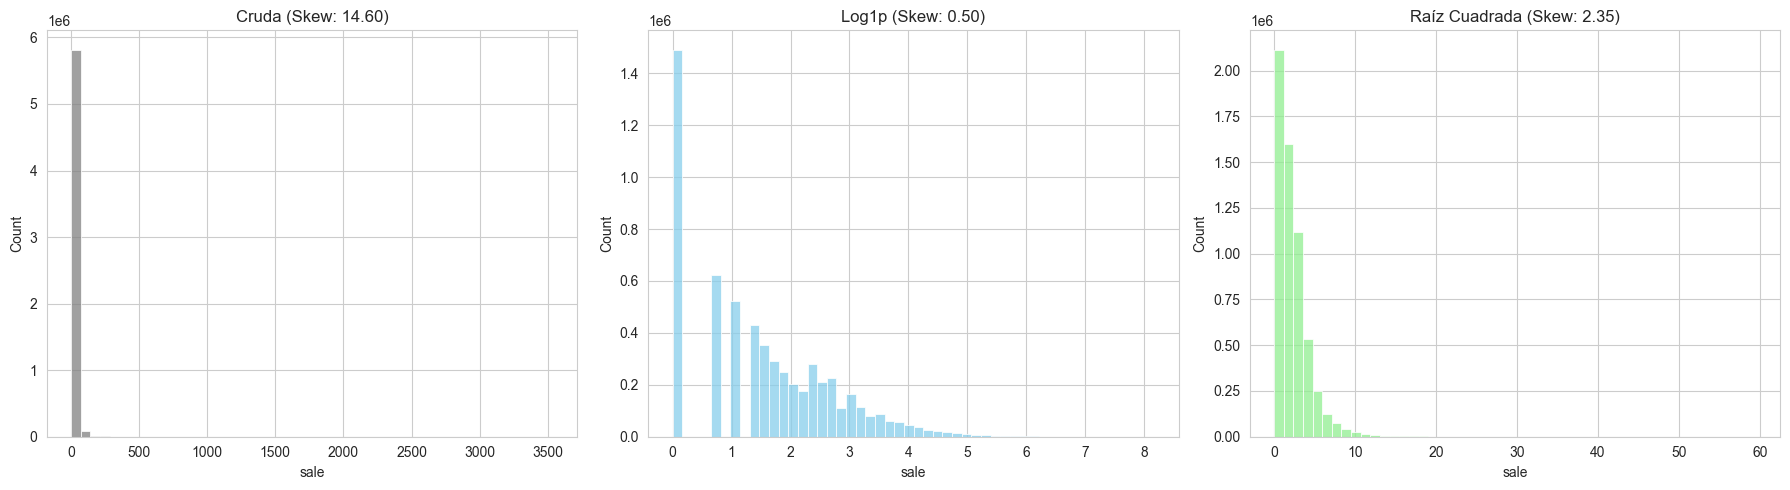

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(18, 5))

# 1. Raw
plt.subplot(1, 3, 1)
sns.histplot(df_weekly['sale'], bins=50, color='gray')
plt.title(f"Raw (Skew: {df_weekly['sale'].skew():.2f})")

# 2. Log1p
plt.subplot(1, 3, 2)
log_y = np.log1p(df_weekly['sale'])
sns.histplot(log_y, bins=50, color='skyblue')
plt.title(f"Log1p (Skew: {log_y.skew():.2f})")

# 3. Square root
plt.subplot(1, 3, 3)
sqrt_y = np.sqrt(df_weekly['sale'])
sns.histplot(sqrt_y, bins=50, color='lightgreen')
plt.title(f"Square root (Skew: {sqrt_y.skew():.2f})")

plt.tight_layout()
plt.show()

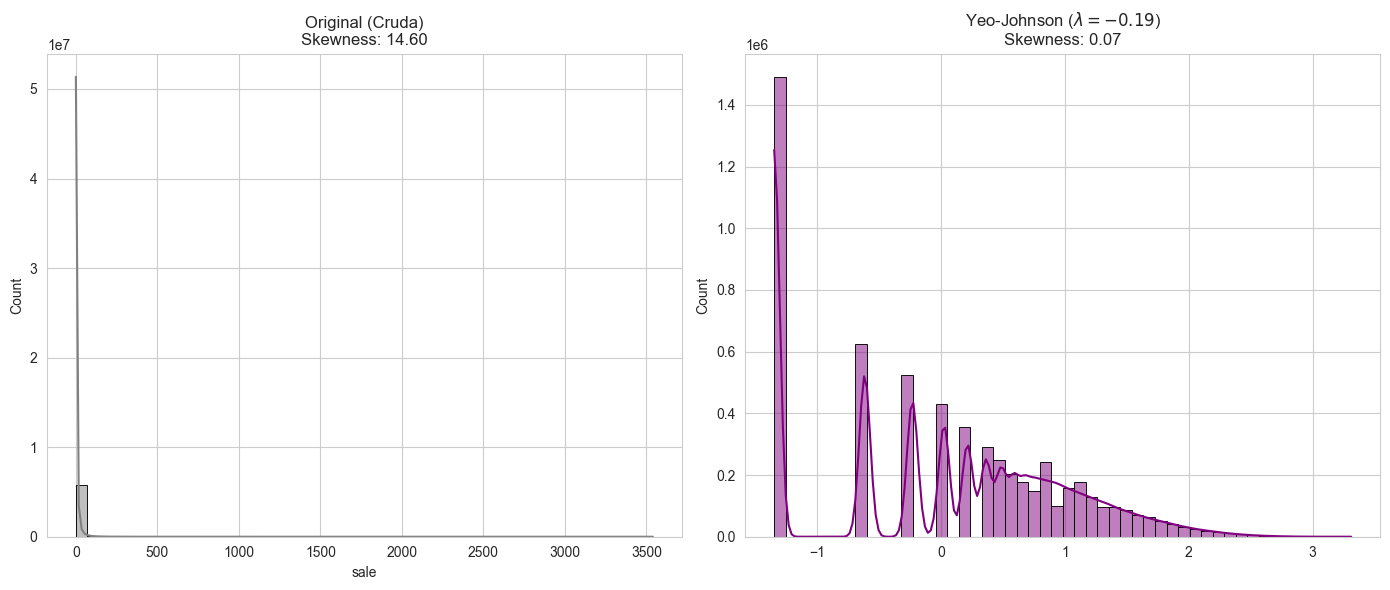

Lambda óptimo: -0.1910


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import PowerTransformer

# Yeo-Johnson transformation
pt = PowerTransformer(method='yeo-johnson', standardize=True)

sales_yeo = pt.fit_transform(df_weekly[['sale']])
sales_yeo_clean = sales_yeo.values.flatten() if hasattr(sales_yeo, 'values') else sales_yeo.flatten()

sales_yeo_series = pd.Series(sales_yeo_clean)
lambda_optimo = pt.lambdas_[0]

# Visualisation
plt.figure(figsize=(14, 6))

# Original
plt.subplot(1, 2, 1)
sns.histplot(df_weekly['sale'], bins=50, kde=True, color='gray', edgecolor='black')
plt.title(f"Original (raw)\nSkewness: {df_weekly['sale'].skew():.2f}", fontsize=12)

# Yeo-Johnson
plt.subplot(1, 2, 2)
sns.histplot(sales_yeo_series, bins=50, kde=True, color='purple', edgecolor='black')
plt.title(f"Yeo-Johnson ($\lambda={lambda_optimo:.2f}$)\nSkewness: {sales_yeo_series.skew():.2f}", fontsize=12)

plt.tight_layout()
plt.show()

print(f"Optimal lambda: {lambda_optimo:.4f}")

In [ ]:
model_lasso_sqrt = lasso_pipeline_evaluation(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform=np.sqrt,
    use_optimization=False
)

--- Usando Alpha por defecto (1.0) ---
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 16.11
Error Relativo Final: 198.91%


In [ ]:
model_lasso_log1p = lasso_pipeline_evaluation(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform=np.log1p,
    use_optimization=False
)

--- Usando Alpha por defecto (1.0) ---
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 20.02
Error Relativo Final: 247.14%


In [ ]:
model_lasso_yeo = lasso_pipeline_evaluation(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform='yeo-johnson',
    use_optimization=False
)

--- Usando Alpha por defecto (1.0) ---
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 20.16
Error Relativo Final: 248.88%


In [ ]:
# With alpha optimisation (LassoCV)
model_lasso_sqrt = lasso_pipeline_evaluation(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform=np.sqrt,
    use_optimization=True
)

--- Iniciando Búsqueda Rápida de Alpha con LassoCV (<ufunc 'sqrt'>) ---


   >>> Mejor Alpha encontrado: 0.290414
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 14.94
Error Relativo Final: 184.38%


In [ ]:
pipeline_interno = model_lasso_sqrt.regressor_

# Access the Lasso model inside the pipeline
modelo_lasso_final = pipeline_interno.named_steps['model']

# Get alpha
best_alpha = modelo_lasso_final.alpha
best_alpha

0.2904136787833035

In [ ]:
preprocessor_step = pipeline_interno.named_steps['preprocessor']
feature_names = preprocessor_step.get_feature_names_out()

# Lasso coefficients
coeficientes = modelo_lasso_final.coef_

# Build a DataFrame
df_importancia = pd.DataFrame({
    'Feature': feature_names,
    'Coeficiente': coeficientes,
    'Abs_Coef': abs(coeficientes) # To sort by absolute impact
})

df_importancia

,Feature,Coeficiente,Abs_Coef
0,cluster_0,0.000000,0.000000
1,cluster_1,0.000000,0.000000
2,cluster_2,-0.000000,0.000000
3,cluster_3,0.000000,0.000000
4,cluster_4,-0.000000,0.000000
5,cluster_5,-0.000000,0.000000
6,cluster_6,-0.000000,0.000000
7,store_code_PHI_2,-0.000000,0.000000
8,cos_year,-0.000000,0.000000
9,tavg,0.000000,0.000000


In [ ]:
# Most important features
print(df_importancia[df_importancia.Abs_Coef>0].sort_values('Abs_Coef', ascending=False).head(10))

                       Feature  Coeficiente  Abs_Coef
42        rolling_mean_4w_sale     0.736975  0.736975
49                  lag_1_sale     0.670354  0.670354
11  department_HOME_&_GARDEN_2    -0.000675  0.000675


In [ ]:
# Features dropped by Lasso (coefficient = 0)
vars_eliminadas = df_importancia[df_importancia['Coeficiente'] == 0]
print(f"\nFeatures dropped: {len(vars_eliminadas)} of {len(df_importancia)}")


Variables eliminadas: 52 de 55


#### Joint transformation of the target and the lag features

In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso, LassoCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor, make_column_selector
from sklearn.preprocessing import PowerTransformer, FunctionTransformer
from sklearn.metrics import root_mean_squared_error

def lasso_pipeline_evaluation_2(x_train_clean, y_train, x_val_clean, y_val, preprocessor, 
                              target_transform=np.log1p, 
                              use_optimization=True):
    """
    Train a Lasso pipeline. If use_optimization=True, LassoCV is used to find
    the best alpha (3-fold KFold CV on the training set).
    """
    
    # 1. Target transformation arguments for TransformedTargetRegressor
    tt_args = {}
    
    # Helper to transform the target manually before LassoCV
    manual_transformer = None 
    
    if target_transform == np.log1p:
        feat_trans_func = np.log1p
    elif target_transform == np.sqrt:
        feat_trans_func = np.sqrt
    elif target_transform == 'yeo-johnson':
        feat_trans_func = np.log1p 
    else:
        feat_trans_func = None
        
    cols_lags = [c for c in x_train_clean.columns if 'lag' in c or 'rolling' in c or 'shift' in c]
    cols_resto = [c for c in x_train_clean.columns if c not in cols_lags and c != 'cluster']
    
    lag_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('transform', FunctionTransformer(
            feat_trans_func, 
            validate=False, 
            feature_names_out='one-to-one'
        )),
        ('scaler', StandardScaler())
    ])
    
    if target_transform is None:
        tt_args['func'] = lambda y: y
        tt_args['inverse_func'] = lambda y: y
        manual_transformer = lambda y: y
        
    elif target_transform == np.log1p:
        tt_args['func'] = np.log1p
        tt_args['inverse_func'] = np.expm1
        manual_transformer = np.log1p
        
    elif target_transform == np.sqrt:
        tt_args['func'] = np.sqrt
        tt_args['inverse_func'] = lambda y: y**2
        manual_transformer = np.sqrt
        
    elif target_transform == 'yeo-johnson':
        # Final pipeline: TransformedTargetRegressor handles the transformer
        tt_args['transformer'] = PowerTransformer(method='yeo-johnson', standardize=True)
        
        # Manual: fit a temporary transformer to prepare the CV target
        pt_manual = PowerTransformer(method='yeo-johnson', standardize=True)
        # Fit on y_train (needs a 2D array)
        pt_manual.fit(y_train.values.reshape(-1, 1))
        
        manual_transformer = lambda y: pt_manual.transform(y.values.reshape(-1, 1)).flatten()
        
    else:
        raise ValueError(f"Unsupported target transformation '{target_transform}'.")

    # Default alpha when not optimising
    best_alpha = 1.0 
    
    # ALPHA OPTIMISATION (LassoCV)
    
    # 4. Preprocessor
    preprocessor_avanzado = ColumnTransformer(
        transformers=[
            # A. Cluster (categorical)
            ('cat_cluster', categorical_transformer, ['cluster']),
            
            # B. Object columns (categorical)
            ('cat_objects', categorical_transformer, make_column_selector(dtype_include=['object'])),
            
            # C. Lags and rolling means (numeric + same log/sqrt transform as the target)
            ('num_lags', lag_transformer, cols_lags),
            
            # D. Other numeric columns (scaler only)
            ('num_resto', numeric_transformer, cols_resto)
        ],
        verbose_feature_names_out=False
    )
    
    if use_optimization:
        print(f"--- Searching alpha with LassoCV ({target_transform}) ---")

        x_train_enc = preprocessor_avanzado.fit_transform(x_train_clean)
        y_train_trans = manual_transformer(y_train)
        
        # Run LassoCV
        lasso_cv = LassoCV(
            alphas=100,        # 100 candidate alphas along the regularisation path
            cv=3,              # 3-fold KFold (not time-ordered); only used to pick alpha
            random_state=42,
            n_jobs=-1,         # Use all cores
            max_iter=5000,     # Room for convergence
            verbose=False
        )
        
        lasso_cv.fit(x_train_enc, y_train_trans)
        
        best_alpha = lasso_cv.alpha_
        print(f"   >>> Best alpha found: {best_alpha:.6f}")
        
    else:
        print(f"--- Using default alpha (1.0) ---")

    # FINAL MODEL
    
    lasso_base = Lasso(
        alpha=best_alpha,
        random_state=42, 
        max_iter=10000 # More iterations for the final fit
    )

    # Full pipeline
    final_pipeline = TransformedTargetRegressor(
        regressor=Pipeline(steps=[
            ('preprocessor', preprocessor_avanzado),
            ('model', lasso_base)
        ]),
        **tt_args
    )

    # Final training
    final_pipeline.fit(x_train_clean, y_train)
    preds_val = final_pipeline.predict(x_val_clean)
    
    rmse_val = root_mean_squared_error(y_val, preds_val)
    mean_sales = y_val.mean()
    rmse_pct = (rmse_val / mean_sales) * 100

    print(f"--- Final pipeline results ---")
    print(f"RMSE Val (units): {rmse_val:.2f}")
    print(f"NRMSE (RMSE / mean sales): {rmse_pct:.2f}%")
    
    return final_pipeline

In [ ]:
# Lasso splits rebuilt from df_weekly after replacing -1000 with NaN (cell above).
# The pipelines impute NaN with the training mean; sqrt(-1000) would otherwise produce NaN in the lag features.
x_train_clean, y_train = get_data_splits(df_weekly, train_dates)
x_val_clean, y_val = get_data_splits(df_weekly, val_dates)
x_test_clean, y_test = get_data_splits(df_weekly, test_dates)

In [ ]:
model_lasso_sqrt_2 = lasso_pipeline_evaluation_2(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform=np.sqrt,
    use_optimization=False
)

--- Usando Alpha por defecto (1.0) ---
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 15.18
Error Relativo Final: 187.41%


In [ ]:
model_lasso_log1p_2 = lasso_pipeline_evaluation_2(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform=np.log1p,
    use_optimization=False
)

--- Usando Alpha por defecto (1.0) ---
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 19.94
Error Relativo Final: 246.11%


In [ ]:
model_lasso_yeo_2 = lasso_pipeline_evaluation_2(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform='yeo-johnson',
    use_optimization=False
)

--- Usando Alpha por defecto (1.0) ---
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 20.16
Error Relativo Final: 248.88%


In [ ]:
# sqrt is again the best target transform, so we now tune alpha with LassoCV
model_lasso_optimized = lasso_pipeline_evaluation_2(
    x_train_clean, y_train,
    x_val_clean, y_val,
    preprocessor,
    target_transform=np.sqrt,
    use_optimization=True
)

--- Iniciando Búsqueda Rápida de Alpha con LassoCV (<ufunc 'sqrt'>) ---


   >>> Mejor Alpha encontrado: 0.001960
--- Resultados Finales Pipeline ---
RMSE Val (Unidades): 8.70
Error Relativo Final: 107.36%


### Lasso vs naive baseline

Naive forecast: this week's sales = last week's sales (`lag_1_sale`). Both forecasts are scored on the same rows (validation rows without `lag_1_sale` are excluded for both):
- **RMSE**, **MAE** (units) and **WMAPE** = Σ|y − ŷ| / Σy.
- **WMAPE_weekly_total**: WMAPE of the weekly company totals (sum over all item–stores per week).
- **volume_ratio** = Σŷ / Σy (1.0 = no aggregate bias).
- **\*_improvement_%** = (1 − model error / naive error) × 100; positive = model better.

The Lasso is scored on validation (weeks 255–268, also used to choose the target transform) and on the test weeks 270–278, which were not used for any modelling choice.

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error


def wmape(y_true, y_pred):
    """Weighted MAPE: sum(|y - pred|) / sum(y)."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return np.abs(y_true - y_pred).sum() / y_true.sum()


def compare_with_naive(y_true, y_model, y_naive, weeks, model_name, set_name):
    """
    Model vs naive forecast (last week's sales = lag_1_sale) on the same rows.
    Rows without lag_1_sale (NaN) are excluded for BOTH, so the comparison is like-for-like.
    WMAPE_weekly_total aggregates actuals and predictions by week first (company level).
    volume_ratio = sum(pred) / sum(actual): below 1 means total volume is under-forecast.
    """
    df_cmp = pd.DataFrame({'week_number': np.asarray(weeks),
                           'y': np.asarray(y_true, dtype=float),
                           'model': np.asarray(y_model, dtype=float),
                           'naive': np.asarray(y_naive, dtype=float)})
    n_rows = len(df_cmp)
    df_cmp = df_cmp.dropna(subset=['naive'])
    weekly = df_cmp.groupby('week_number')[['y', 'model', 'naive']].sum()

    rows = []
    for name, col in [(model_name, 'model'), ('Naive (lag-1)', 'naive')]:
        rows.append({'model': name, 'set': set_name,
                     'RMSE': root_mean_squared_error(df_cmp['y'], df_cmp[col]),
                     'MAE': mean_absolute_error(df_cmp['y'], df_cmp[col]),
                     'WMAPE': wmape(df_cmp['y'], df_cmp[col]),
                     'WMAPE_weekly_total': wmape(weekly['y'], weekly[col]),
                     # Total predicted volume / total actual volume (1.0 = no aggregate bias)
                     'volume_ratio': df_cmp[col].sum() / df_cmp['y'].sum()})
    res = pd.DataFrame(rows)

    # Improvement of the model vs the naive baseline (positive = model is better)
    for metric in ['RMSE', 'WMAPE', 'WMAPE_weekly_total']:
        res[f'{metric}_improvement_%'] = np.nan
        res.loc[0, f'{metric}_improvement_%'] = (1 - res.loc[0, metric] / res.loc[1, metric]) * 100

    print(f"{set_name}: {len(df_cmp):,} of {n_rows:,} rows evaluated "
          f"({n_rows - len(df_cmp):,} without lag_1_sale excluded), {df_cmp['week_number'].nunique()} weeks")
    return res

In [ ]:
# Lasso (sqrt target, alpha from LassoCV) vs the naive baseline on the same rows.
# Predictions are clipped at 0 (no effect here: squaring the sqrt-space prediction is already >= 0).
lasso_val_weeks = df_weekly.loc[df_weekly['week_number'].isin(val_dates), 'week_number'].values
lasso_test_weeks = df_weekly.loc[df_weekly['week_number'].isin(test_dates), 'week_number'].values

lasso_val_pred = np.clip(model_lasso_optimized.predict(x_val_clean), 0, None)
lasso_test_pred = np.clip(model_lasso_optimized.predict(x_test_clean), 0, None)

lasso_vs_naive = pd.concat([
    compare_with_naive(y_val, lasso_val_pred, x_val_clean['lag_1_sale'], lasso_val_weeks,
                       'Lasso (sqrt target)', 'Validation (weeks 255-268)'),
    compare_with_naive(y_test, lasso_test_pred, x_test_clean['lag_1_sale'], lasso_test_weeks,
                       'Lasso (sqrt target)', 'Test (weeks 270-278)'),
], ignore_index=True)
lasso_vs_naive.round(4)

In [ ]:
# Coefficients of the tuned Lasso (model_lasso_optimized)
pipeline_interno = model_lasso_optimized.regressor_
modelo_lasso_final = pipeline_interno.named_steps['model']
preprocessor = pipeline_interno.named_steps['preprocessor']

ohe_cluster = preprocessor.named_transformers_['cat_cluster']['onehot']
names_cluster = ohe_cluster.get_feature_names_out(['cluster'])

# Lags and rolling means (numeric, transformed)
names_lags = [c for c in x_train_clean.columns if 'lag' in c or 'rolling' in c or 'shift' in c]

# Other numeric columns
names_resto = [c for c in x_train_clean.columns if c not in names_lags and c != 'cluster']

# Concatenate in the exact ColumnTransformer order
all_feature_names = list(names_cluster) + list(names_lags) + list(names_resto)

print(f"Total feature names recovered: {len(all_feature_names)}")
print(f"Total Lasso coefficients: {len(modelo_lasso_final.coef_)}")

df_importancia = pd.DataFrame({
    'Feature': all_feature_names,
    'Coeficiente': modelo_lasso_final.coef_,
    'Abs_Coef': abs(modelo_lasso_final.coef_)
})

print(df_importancia.sort_values('Abs_Coef', ascending=False).head(10))

Total features recuperadas: 55
Total coeficientes Lasso: 55
                 Feature  Coeficiente  Abs_Coef
11  rolling_mean_4w_sale     1.073107  1.073107
7             lag_1_sale     0.818887  0.818887
15                 Month    -0.162800  0.162800
22              sin_year    -0.109846  0.109846
10           lag_52_sale     0.097525  0.097525
9            lag_26_sale     0.092201  0.092201
32             xmas_heat     0.064679  0.064679
26                  tmax     0.041516  0.041516
16             Day_month    -0.041278  0.041278
37     is_holiday_closed     0.032398  0.032398


In [ ]:

print(df_importancia[df_importancia.Abs_Coef>0].sort_values('Abs_Coef', ascending=False).tail(20))

                       Feature  Coeficiente  Abs_Coef
50  department_HOME_&_GARDEN_1     0.013305  0.013305
21             market_presence     0.013034  0.013034
33              superbowl_heat    -0.012374  0.012374
54    department_SUPERMARKET_3     0.012059  0.012059
29                        wspd     0.010919  0.010919
30             rain_days_count     0.010247  0.010247
31             valentines_heat     0.008547  0.008547
44            store_code_NYC_3     0.008478  0.008478
38      sale_region_proportion     0.007833  0.007833
19       changed_price_vs_mean    -0.006550  0.006550
45            store_code_NYC_4    -0.003149  0.003149
42            store_code_NYC_1     0.003032  0.003032
39     sale_quarter_proportion     0.002771  0.002771
48            store_code_PHI_3    -0.002406  0.002406
35                  july4_heat    -0.002321  0.002321
46            store_code_PHI_1     0.002282  0.002282
34           thanksgiving_heat    -0.001591  0.001591
0                    cluster

## 7. Log-difference target (XGBoost)

In [ ]:
x_train, y_train = get_data_splits(df_weekly, train_dates)
x_val, y_val = get_data_splits(df_weekly, val_dates)
x_test, y_test = get_data_splits(df_weekly, test_dates)

range(53, 254)
(5134765, 49) (5134765,)
range(255, 269)
(426602, 49) (426602,)
range(270, 279)
(274410, 49) (274410,)


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import random

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# =============================================================================
# 1. DATA PREPARATION AND FEATURE ENGINEERING
# =============================================================================
# Work on a copy
df_weekly_ln_diff = df_weekly.copy()

# A. Log transform (log1p handles zeros)
# Keep the log level to reconstruct predictions later
df_weekly_ln_diff['sale_log_level'] = np.log1p(df_weekly_ln_diff['sale'])

# B. Differenced target
# Week-over-week difference of the log level
df_weekly_ln_diff['target_diff'] = df_weekly_ln_diff.groupby('unique_id')['sale_log_level'].diff(1)

# C. Lags and rolling mean of the differenced target
# NOTE: computed on 'target_diff', not on the original 'sale'.

# Lags
lags = [1, 4, 26, 52]
for lag in lags:
    df_weekly_ln_diff[f'lag_{lag}'] = df_weekly_ln_diff.groupby('unique_id')['target_diff'].shift(lag)

# Rolling mean with shift (no leakage)
# shift(1) moves the data one week forward, so the 4-week mean
# at row T uses T-1, T-2, T-3, T-4.
df_weekly_ln_diff['rolling_mean_4'] = (
    df_weekly_ln_diff.groupby('unique_id')['target_diff']
    .shift(1)
    .rolling(window=4)
    .mean()
)

# D. Cleaning
# Drop rows with NaNs created by the lags (lag 52 creates many at the start of each series)
df_weekly_ln_diff.dropna(subset=['target_diff', 'rolling_mean_4', 'lag_52'], inplace=True)

# =============================================================================
# 2. CHRONOLOGICAL SPLITS
# =============================================================================
# Splits are defined on week_number
week_number_val = 255
week_number_test = 270

# Time masks
train_mask = df_weekly_ln_diff['week_number'] < week_number_val
val_mask = (df_weekly_ln_diff['week_number'] >= week_number_val) & (df_weekly_ln_diff['week_number'] < week_number_test)

# Split X and y
features_cols = [c for c in df_weekly_ln_diff.columns if c not in ['unique_id', 'week_number', 'sale', 'sale_log_level', 'target_diff']]

# Train
x_train = df_weekly_ln_diff.loc[train_mask, features_cols]
y_train_diff = df_weekly_ln_diff.loc[train_mask, 'target_diff']
y_train_prev_level = df_weekly_ln_diff.loc[train_mask].groupby('unique_id')['sale_log_level'].shift(1) # To reconstruct
y_train_real = df_weekly_ln_diff.loc[train_mask, 'sale'] # For the final RMSE

# Val
x_val = df_weekly_ln_diff.loc[val_mask, features_cols]
y_val_diff = df_weekly_ln_diff.loc[val_mask, 'target_diff']
y_val_prev_level = df_weekly_ln_diff.loc[val_mask].groupby('unique_id')['sale_log_level'].shift(1) # To reconstruct
y_val_real = df_weekly_ln_diff.loc[val_mask, 'sale'] # For the final RMSE

# Drop rows where 'prev_level' is NaN (first week of each series)
# This is needed for the one-step-ahead reconstruction
valid_train_idx = y_train_prev_level.notna()
x_train = x_train[valid_train_idx]
y_train_diff = y_train_diff[valid_train_idx]
y_train_prev_level = y_train_prev_level[valid_train_idx]
y_train_real = y_train_real[valid_train_idx]

valid_val_idx = y_val_prev_level.notna()
x_val = x_val[valid_val_idx]
y_val_diff = y_val_diff[valid_val_idx]
y_val_prev_level = y_val_prev_level[valid_val_idx]
y_val_real = y_val_real[valid_val_idx]

# Test mask and previous log level, used for the test-set evaluation below
test_mask = (df_weekly_ln_diff['week_number'] >= week_number_test) & (df_weekly_ln_diff['week_number'] < max_week_test)
df_weekly_ln_diff['prev_log_level'] = df_weekly_ln_diff.groupby('unique_id')['sale_log_level'].shift(1)

In [ ]:

# RECONSTRUCTION FUNCTION (ONE-STEP AHEAD)
def inverse_transform_one_step(y_pred_diff, y_prev_log_level):
    """
    Reconstruct the prediction:
    Log_Pred_t = Log_Real_{t-1} + Predicted_Diff
    Sale_Pred_t = expm1(Log_Pred_t)
    """
    # 1. Add the predicted difference to the previous real log level
    y_pred_log_level = y_prev_log_level + y_pred_diff
    
    # 2. Undo the log
    y_pred_original = np.expm1(y_pred_log_level)
    
    return y_pred_original



In [ ]:
df_weekly_ln_diff.head()

,sale,sell_price,week_number,Year,Quarter,Month,Day_month,price_mean_year,price_proportion_item_department,changed_price_vs_mean,...,department_SUPERMARKET_1,department_SUPERMARKET_2,department_SUPERMARKET_3,sale_log_level,target_diff,lag_1,lag_4,lag_26,lag_52,rolling_mean_4
53,6,10.99,184,2014,3,7,12,11.168508,1.315132,-0.015983,...,0,0,0,1.945910,0.847298,-0.510826,0.000000,0.000000,-0.223144,0.101366
54,4,10.99,185,2014,3,7,19,11.168508,1.315132,-0.015983,...,0,0,0,1.609438,-0.336472,0.847298,1.252763,1.609438,0.000000,0.313191
55,7,10.99,186,2014,3,7,26,11.168508,1.315132,-0.015983,...,0,0,0,2.079442,0.470004,-0.336472,-0.336472,-1.609438,-0.693147,-0.084118
56,1,10.99,187,2014,3,8,2,11.168508,1.315132,-0.015983,...,0,0,0,0.693147,-1.386294,0.470004,-0.510826,0.693147,-0.693147,0.117501
57,0,10.99,188,2014,3,8,9,11.168508,1.315132,-0.015983,...,0,0,0,0.000000,-0.693147,-1.386294,0.847298,-0.693147,0.000000,-0.101366


In [ ]:
# RANDOM FEATURE-SUBSET SEARCH

results = {}
all_features = x_train.columns.tolist()

for i in range(1, 200):
    # Random feature subset
    n_feats = random.randint(10, 25)
    features_selected = random.sample(all_features, n_feats)
    
    x_train_i = x_train[features_selected]
    x_val_i = x_val[features_selected]

    model = xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=100,
        learning_rate=0.1,
        max_depth=8,
        random_state=42
    )

    # Train on the differenced target
    model.fit(x_train_i, y_train_diff)

    # Predict and reconstruct (TRAIN)
    # Predicted difference
    y_train_pred_diff = model.predict(x_train_i)
    # Reconstruction to units
    y_train_pred_real = inverse_transform_one_step(y_train_pred_diff, y_train_prev_level)
    # RMSE
    rmse_train = root_mean_squared_error(y_train_real, y_train_pred_real)

    # Predict and reconstruct (VAL)
    y_val_pred_diff = model.predict(x_val_i)
    y_val_pred_real = inverse_transform_one_step(y_val_pred_diff, y_val_prev_level)
    rmse_val = root_mean_squared_error(y_val_real, y_val_pred_real)

    # 6. Store and show
    print(f"Iter {i:02d} | Feats: {len(features_selected):02d} | RMSE Train: {rmse_train:.2f} | RMSE Val: {rmse_val:.2f}")
    
    # Store features and metrics
    results[i] = {
        'features': features_selected,
        'rmse_train': rmse_train,
        'rmse_val': rmse_val
    }

# Track the best iteration
best_iter = min(results, key=lambda x: results[x]['rmse_val'])
print(f"\nBest iteration: {best_iter}")
print(f"Best RMSE Val: {results[best_iter]['rmse_val']:.4f}")
print(f"Features: {results[best_iter]['features']}")

Iter 01 | Feats: 23 | RMSE Train: 10.48 | RMSE Val: 9.09
Iter 02 | Feats: 18 | RMSE Train: 10.32 | RMSE Val: 12.14
Iter 03 | Feats: 11 | RMSE Train: 10.76 | RMSE Val: 12.74
Iter 04 | Feats: 16 | RMSE Train: 9.86 | RMSE Val: 9.70
Iter 05 | Feats: 22 | RMSE Train: 9.75 | RMSE Val: 9.10
Iter 06 | Feats: 16 | RMSE Train: 9.52 | RMSE Val: 8.66
Iter 07 | Feats: 17 | RMSE Train: 10.80 | RMSE Val: 10.67
Iter 08 | Feats: 22 | RMSE Train: 9.85 | RMSE Val: 9.45
Iter 09 | Feats: 21 | RMSE Train: 10.11 | RMSE Val: 9.52
Iter 10 | Feats: 12 | RMSE Train: 10.31 | RMSE Val: 10.24
Iter 11 | Feats: 25 | RMSE Train: 9.78 | RMSE Val: 9.91
Iter 12 | Feats: 19 | RMSE Train: 9.71 | RMSE Val: 9.73
Iter 13 | Feats: 23 | RMSE Train: 9.72 | RMSE Val: 9.40
Iter 14 | Feats: 21 | RMSE Train: 10.08 | RMSE Val: 9.35
Iter 15 | Feats: 25 | RMSE Train: 9.64 | RMSE Val: 9.33
Iter 16 | Feats: 21 | RMSE Train: 9.95 | RMSE Val: 9.77
Iter 17 | Feats: 15 | RMSE Train: 10.63 | RMSE Val: 12.53
Iter 18 | Feats: 14 | RMSE Train: 1

Rango de RMSE en el Top 20: 8.4423 - 8.9252


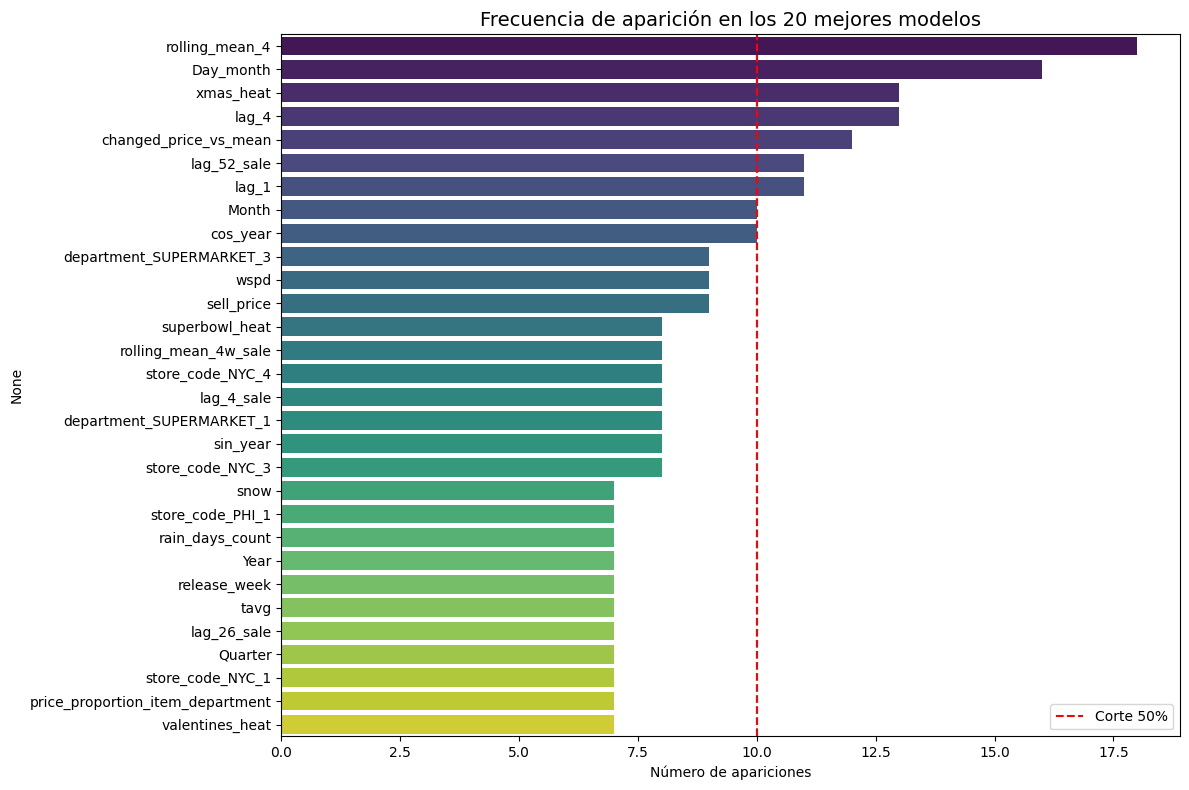

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 1. Results dictionary to DataFrame
df_results = pd.DataFrame.from_dict(results, orient='index')

# 2. Keep the top models
top_n = 20  
top_models = df_results.sort_values('rmse_val', ascending=True).head(top_n)

print(f"RMSE range in the top {top_n}: {top_models['rmse_val'].min():.4f} - {top_models['rmse_val'].max():.4f}")

# 3. Count how often each feature appears
all_top_features = [feat for feature_list in top_models['features'] for feat in feature_list]

feature_counts = Counter(all_top_features)
df_counts = pd.DataFrame.from_dict(feature_counts, orient='index', columns=['count'])
df_counts = df_counts.sort_values('count', ascending=False)

# Relative frequency (%)
df_counts['frequency_pct'] = (df_counts['count'] / top_n) * 100

# 4. Plot feature frequency
plt.figure(figsize=(12, 8))
sns.barplot(x=df_counts['count'].head(30), y=df_counts.index[:30], hue=df_counts.index[:30], palette='viridis', legend=False)
plt.title(f'Feature frequency in the top {top_n} models', fontsize=14)
plt.xlabel('Number of appearances')
plt.axvline(x=top_n * 0.5, color='red', linestyle='--', label='50% cut-off') # Suggested cut-off
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
# Final selection (consensus criterion)

umbral_corte = 0.5 # 50%
features_robustas = df_counts[df_counts['frequency_pct'] >= (umbral_corte * 100)].index.tolist()

print(f"\n--- ROBUST SELECTION ---")
print(f"Total features found in the top models: {len(df_counts)}")
print(f"Selected features (present in >{umbral_corte*100}% of models): {len(features_robustas)}")
print(f"Final list: {features_robustas}")


--- SELECCIÓN ROBUSTA ---
Total features encontradas en el top: 54
Features seleccionadas (aparecen en >50.0% de modelos): 9
Lista Definitiva: ['rolling_mean_4', 'Day_month', 'xmas_heat', 'lag_4', 'changed_price_vs_mean', 'lag_52_sale', 'lag_1', 'Month', 'cos_year']


In [ ]:
import optuna
import xgboost as xgb

# Keep ONLY the selected features
x_train_opt = x_train[features_robustas]
x_val_opt = x_val[features_robustas]

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Model with the selected features only
model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=8,
    random_state=42
)

model.fit(
x_train_opt, 
y_train_diff,
eval_set=[(x_train_opt, y_train_diff), (x_val_opt, y_val_diff)],
verbose=False
)
    
# Predict the log difference
preds_diff_log = model.predict(x_val_opt)
    
# Reconstruct to units (one-step ahead)
preds_real = inverse_transform_one_step(preds_diff_log, y_val_prev_level)
    
# RMSE in units
rmse = root_mean_squared_error(y_val_real, preds_real)
rmse
    

8.568940339348627

In [ ]:
select_features = ['sale_quarter_proportion',
 'store_code_BOS_3',
 'snow',
 'store_code_BOS_2',
 'market_presence',
 'sin_year',
 'july4_heat',
 'price_mean_year',
 'department_SUPERMARKET_2',
 'Day_month',
 'lag_52_sale',
 'department_HOME_&_GARDEN_1',
 'department_SUPERMARKET_1',
 'tavg',
 'rolling_mean_4w_sale',
 'lag_1_sale',
 'xmas_heat',
 'valentines_heat',
 'Year']

x_train_final = x_train[select_features]
x_val_final = x_val[select_features]
x_test_final = x_test[select_features]

model_final = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=10,
    random_state=42,
    early_stopping_rounds=10
)

model_final.fit(
    x_train_final, 
    y_train_diff,
    eval_set=[(x_train_final, y_train_diff), (x_val_final, y_val_diff)],
    verbose=False
)

# Predict the log difference
preds_diff_log_final = model_final.predict(x_val_final)
# Reconstruct to units (one-step ahead)
preds_real_final = inverse_transform_one_step(preds_diff_log_final, y_val_prev_level)
# RMSE in units
rmse_final = root_mean_squared_error(y_val_real, preds_real_final)
rmse_final

8.984900151441408

In [ ]:
# =============================================================================
# TEST SET EVALUATION (aligned with the model's features)
# =============================================================================

# 1. Exact feature list used by the model
# This attribute stores the column names used in .fit()
required_features = model_final.feature_names_in_

print(f"The model expects {len(required_features)} columns.")
# print(required_features) # Uncomment to see the list

# 2. Build df_test_clean with all the required columns
# (taken from df_weekly_ln_diff, which has every column)

# Columns to extract: model features + metadata
cols_necesarias_test = list(required_features) + ['prev_log_level', 'sale', 'unique_id']

# Filter the test weeks from df_weekly_ln_diff
df_test_raw = df_weekly_ln_diff.loc[test_mask, cols_necesarias_test].copy()

# 3. Cleaning and alignment
df_test_clean = df_test_raw.dropna()
df_test_clean = df_test_clean.set_index('unique_id')

# 4. Final aligned test set
# Use [required_features] to keep the same column order as in training
x_test_aligned = df_test_clean[required_features]
y_test_prev_aligned = df_test_clean['prev_log_level']
y_test_real_aligned = df_test_clean['sale']

print(f"--- Test set aligned ---")
print(f"x_test shape: {x_test_aligned.shape}")
print(f"Columns match: {list(x_test_aligned.columns) == list(required_features)}")

# =============================================================================
# PREDICTION
# =============================================================================

# Predict the log difference
y_test_pred_diff = model_final.predict(x_test_aligned)

# Reconstruction
y_test_pred_real = inverse_transform_one_step(y_test_pred_diff, y_test_prev_aligned)

# RMSE
rmse_test = root_mean_squared_error(y_test_real_aligned, y_test_pred_real)
print(f"\nRMSE Test Final: {rmse_test:.4f}")

El modelo espera 19 columnas.
--- Alineación Corregida ---
x_test shape: (269541, 19)
Columnas coinciden: True

RMSE Test Final: 8.6232


The log + difference transformations did not beat simply modelling the log of the target.

### XGBoost vs naive baseline (test set)

Same rows as `RMSE Test Final` above: 269,541 test rows with all model features available.

In [ ]:
# XGBoost (log-diff target) vs the naive baseline on the same test rows as "RMSE Test Final" above.
# lag_1_sale is one of the model features, so no test row is missing the naive forecast.
df_test_eval = df_weekly_ln_diff.loc[test_mask, cols_necesarias_test + ['week_number']].dropna()

xgb_test_pred = inverse_transform_one_step(model_final.predict(df_test_eval[required_features]),
                                           df_test_eval['prev_log_level'])

xgb_vs_naive = compare_with_naive(df_test_eval['sale'], xgb_test_pred, df_test_eval['lag_1_sale'],
                                  df_test_eval['week_number'], 'XGBoost (log-diff target)', 'Test (weeks 270-278)')
xgb_vs_naive.round(4)

### Summary: models vs naive baseline

In [ ]:
# Summary: model vs naive baseline (lag-1) on the same rows
metrics_summary = pd.concat([lasso_vs_naive, xgb_vs_naive], ignore_index=True)

metrics_summary_display = metrics_summary[['model', 'set', 'RMSE', 'MAE', 'WMAPE', 'WMAPE_weekly_total', 'volume_ratio',
                                           'RMSE_improvement_%', 'WMAPE_improvement_%',
                                           'WMAPE_weekly_total_improvement_%']].copy()
for col in ['WMAPE', 'WMAPE_weekly_total']:
    metrics_summary_display[col] = metrics_summary_display[col] * 100   # as %
metrics_summary_display.rename(columns={'WMAPE': 'WMAPE_%', 'WMAPE_weekly_total': 'WMAPE_weekly_total_%'}).round(2)

**Reading the table**
- **Item level:** Lasso beats the naive forecast on both validation and test (RMSE −10 to −11%, WMAPE −13 to −14%). XGBoost improves MAE / WMAPE but not RMSE.
- **Company level (weekly totals):** the naive forecast is better. Both models are trained on a transformed target (sqrt for Lasso, log for XGBoost). Back-transforming a prediction made in that space gives something closer to the median than to the mean, so total volume is under-forecast (`volume_ratio` ≈ 0.89–0.91 for Lasso, 0.84 for XGBoost, ≈ 1.0 for the naive forecast).
- **Next steps:** correct the back-transformation bias (e.g. a smearing factor estimated on the training set) or train on the raw target with a Poisson / Tweedie objective.

In [ ]:
final_model = model_final

# 1. PREDICTIONS (keeping the original index for plotting)

# Required columns (week_number included for plotting)
# required_features comes from final_model.feature_names_in_
cols_necesarias = list(required_features) + ['prev_log_level', 'sale', 'unique_id', 'week_number']

# --- A. TEST (no set_index, so the index stays aligned) ---
# Copy from the source DataFrame using the mask
df_test_viz_ready = df_weekly_ln_diff.loc[test_mask, cols_necesarias].copy()
df_test_viz_ready = df_test_viz_ready.dropna() # Drop nulls

# Without set_index('unique_id') we keep the original numeric index (0, 1, 2...)
# so predictions can be assigned back to df_viz.

# Split X and y (aligned on the numeric index)
x_test_viz = df_test_viz_ready[required_features]
y_test_prev_viz = df_test_viz_ready['prev_log_level']

# Predict
y_test_pred_diff_viz = final_model.predict(x_test_viz)

# Reconstruct (aligned on the numeric index)
y_test_pred_real_viz = inverse_transform_one_step(y_test_pred_diff_viz, y_test_prev_viz)


# --- B. VALIDATION (same process) ---
df_val_viz_ready = df_weekly_ln_diff.loc[val_mask, cols_necesarias].copy()
df_val_viz_ready = df_val_viz_ready.dropna()

x_val_viz = df_val_viz_ready[required_features]
y_val_prev_viz = df_val_viz_ready['prev_log_level']

y_val_pred_diff_viz = final_model.predict(x_val_viz)
y_val_pred_real_viz = inverse_transform_one_step(y_val_pred_diff_viz, y_val_prev_viz)

print("Predictions regenerated with the original index.")

In [ ]:

# Base DataFrame for plotting
cols_to_keep = ['unique_id', 'week_number', 'sale', 'cluster']
df_viz = df_weekly_ln_diff[cols_to_keep].copy()

# Empty prediction columns
df_viz['Prediction_Val'] = np.nan
df_viz['Prediction_Test'] = np.nan

# --- INDEX-ALIGNED ASSIGNMENT ---
# The index was not modified in step 1, so it matches.
# pandas uses the index to place each value.
df_viz.loc[y_val_pred_real_viz.index, 'Prediction_Val'] = y_val_pred_real_viz
df_viz.loc[y_test_pred_real_viz.index, 'Prediction_Test'] = y_test_pred_real_viz

# Check
print("Sample of test rows in df_viz:")
print(df_viz.dropna(subset=['Prediction_Test']).head())

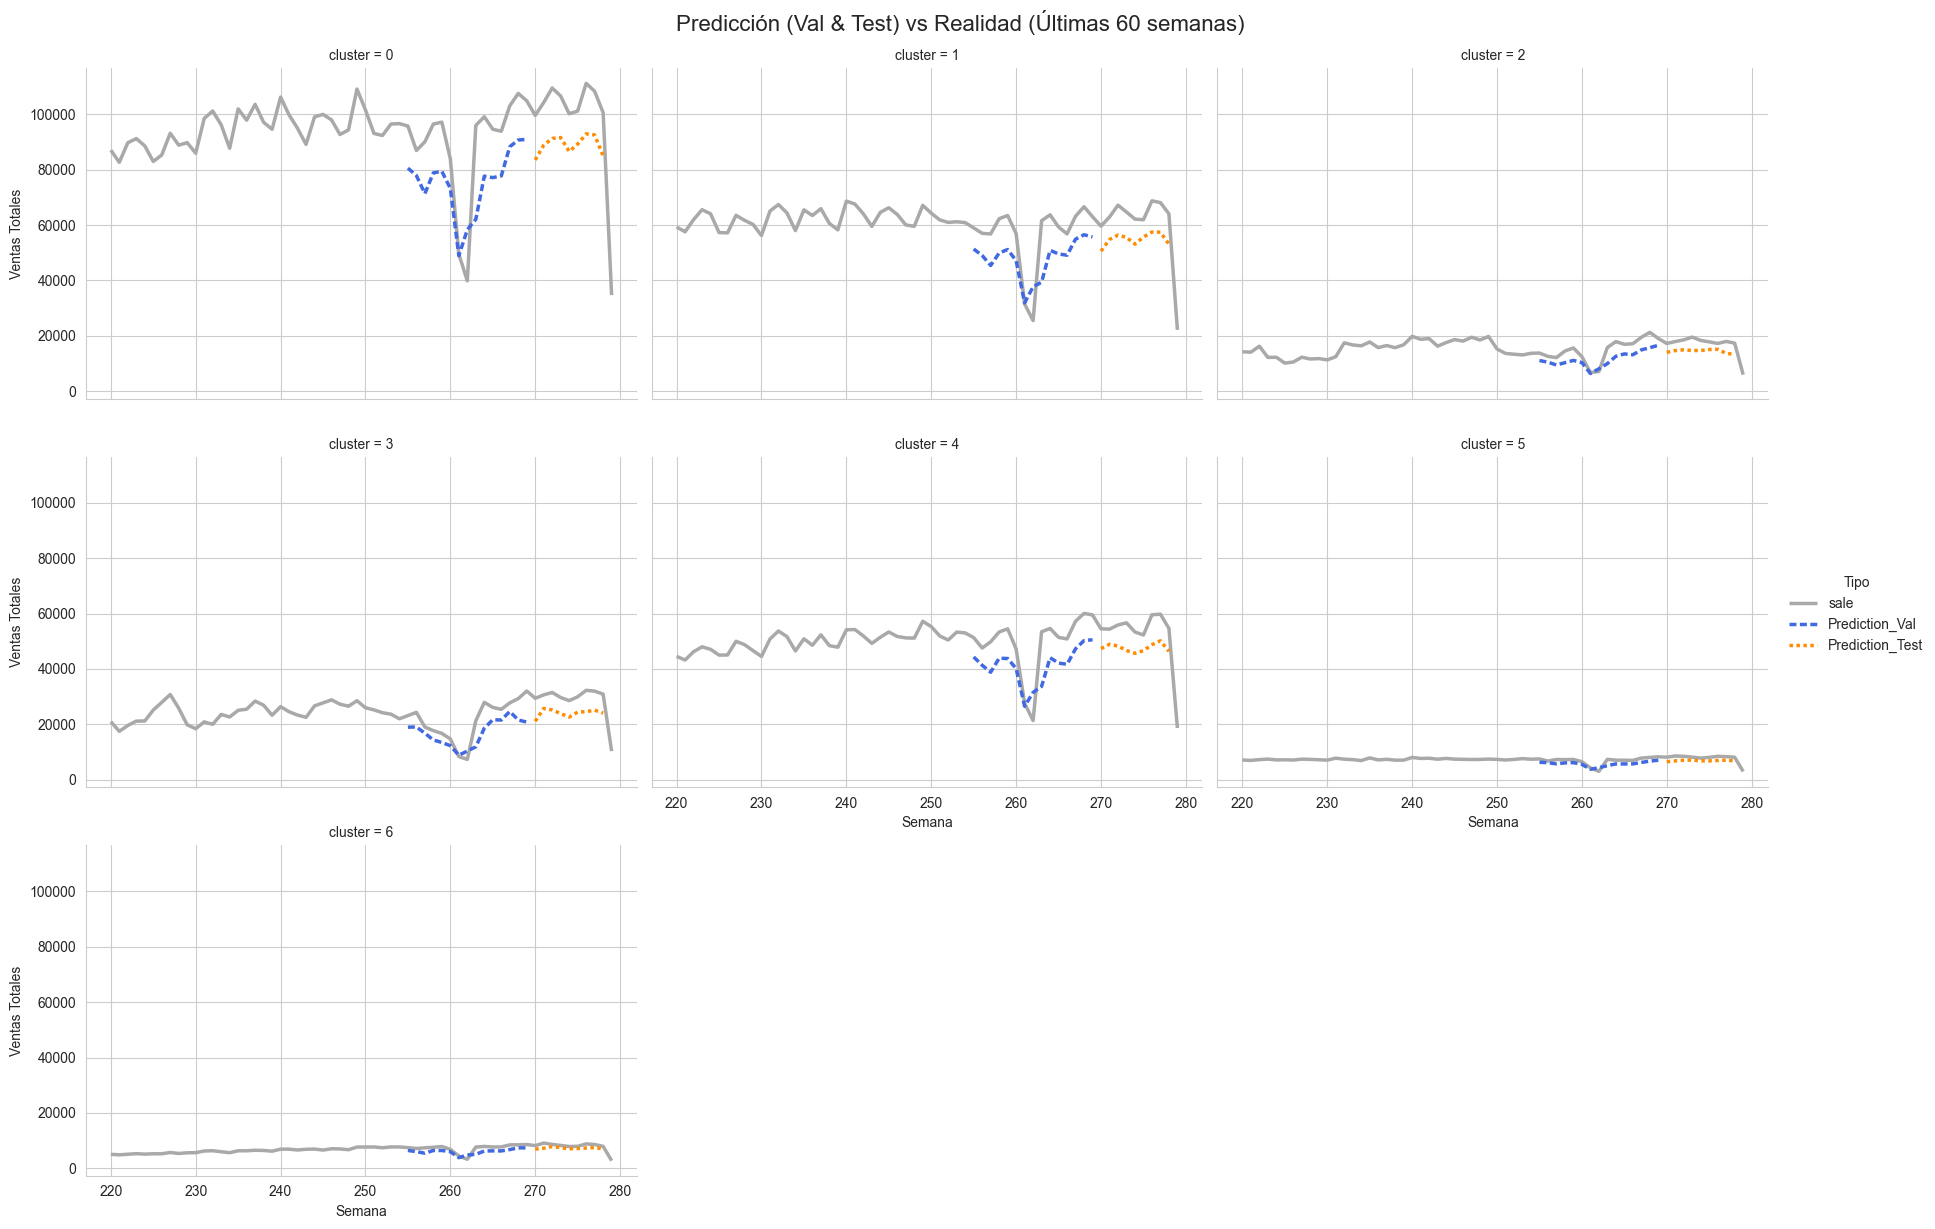

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_full_forecast_by_category(df, 
                                   col_category, 
                                   col_actual='sale', 
                                   pred_cols=['Prediction_Val', 'Prediction_Test'],
                                   col_time='week_number', 
                                   last_n_weeks=52):
    """
    Plot actuals vs validation vs test predictions, grouped by category.
    NaN gaps are kept so no line is drawn where there is no prediction.
    """
    
    # 1. Time filter (last N weeks)
    max_time = df[col_time].max()
    min_time = max_time - last_n_weeks
    df_filtered = df[df[col_time] > min_time].copy()
    
    # 2. Aggregate (sum sales by category and week)
    # Sum both actuals and prediction columns
    # min_count=1 keeps all-NaN sums as NaN (instead of plotting 0)
    cols_to_sum = [col_actual] + pred_cols
    df_grouped = df_filtered.groupby([col_time, col_category])[cols_to_sum].sum(min_count=1).reset_index()
    
    # 3. Melt (long format for seaborn)
    df_melted = df_grouped.melt(
        id_vars=[col_time, col_category],
        value_vars=cols_to_sum,
        var_name='Type',
        value_name='Sales'
    )
    
    # 4. Colours
    # Actuals grey, validation blue, test orange
    custom_palette = {
        col_actual: 'darkgrey',       # Actuals
        pred_cols[0]: 'royalblue',    # Validation
        pred_cols[1]: 'darkorange'    # Test
    }
    
    # Line styles (actuals solid, predictions dashed)
    custom_styles = {
        col_actual: (1, 0),       # Solid
        pred_cols[0]: (2, 1),     # Dashed
        pred_cols[1]: (1, 1)      # Dotted
    }

    # 5. Plot
    sns.set_style("whitegrid")
    
    g = sns.relplot(
        data=df_melted,
        x=col_time, 
        y='Sales',
        col=col_category,
        hue='Type',
        style='Type',
        dashes=custom_styles,
        kind='line',
        palette=custom_palette,
        col_wrap=3, 
        height=4, 
        aspect=1.5,
        linewidth=2.5
    )
    
    # Final touches
    g.fig.suptitle(f'Predictions (Val & Test) vs actuals (last {last_n_weeks} weeks)', y=1.02, fontsize=16)
    g.set_axis_labels("Week", "Total sales")
    
    plt.show()

# -------------------------------------------------------
# RUN
# -------------------------------------------------------

plot_full_forecast_by_category(
    df=df_viz, 
    col_category='cluster', # Any categorical column
    col_actual='sale',
    pred_cols=['Prediction_Val', 'Prediction_Test'],
    last_n_weeks=60 # A bit more than a year for context
)

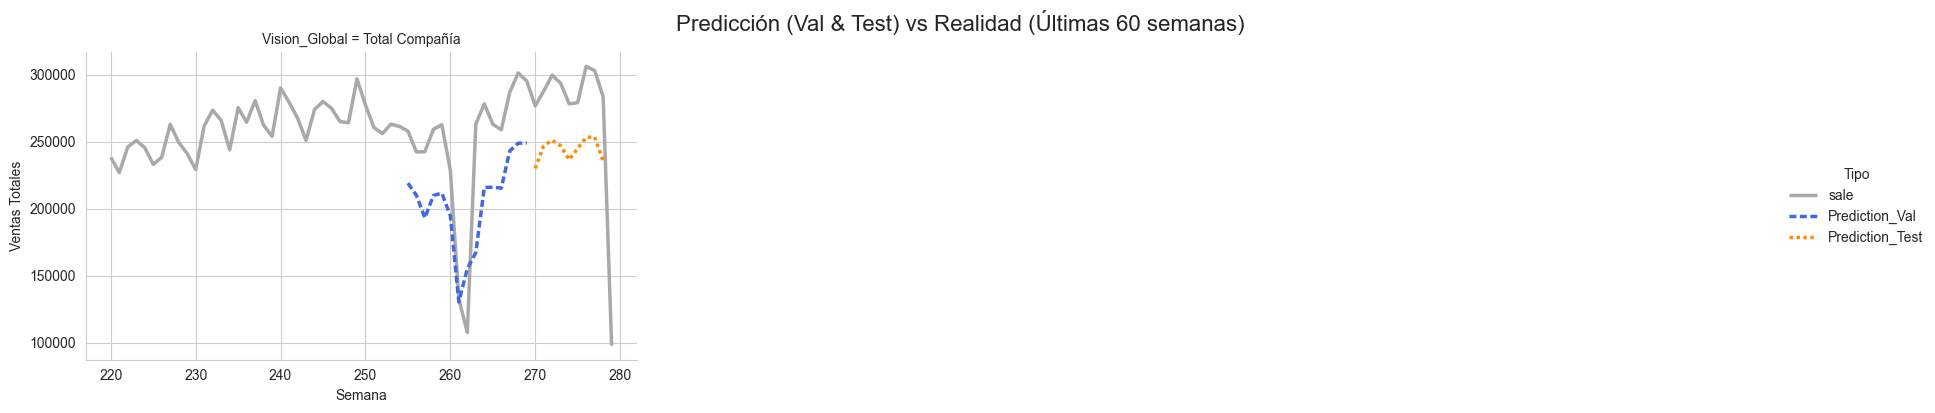

In [ ]:
df_viz['Vision_Global'] = 'Company total'

# 2. Call the function with that column
plot_full_forecast_by_category(
    df=df_viz, 
    col_category='Vision_Global',
    col_actual='sale',
    pred_cols=['Prediction_Val', 'Prediction_Test'],
    col_time='week_number',
    last_n_weeks=60
)

In [ ]:
# Prefixes to recover
prefixes = ['store_code_', 'department_']

# All OHE columns in df_weekly_ln_diff
cols_ohe = [c for c in df_weekly_ln_diff.columns if any(c.startswith(p) for p in prefixes)]

# Join them to df_viz on the index
df_viz = df_viz.join(df_weekly_ln_diff[cols_ohe])

In [ ]:
def reverse_ohe(df, prefix, base_category):
    """
    Take a DataFrame and a prefix (e.g. 'store_code_').
    Find all columns starting with that prefix.
    Return a Series with the original category.
    base_category: category dropped by get_dummies(drop_first=True) (rows with all zeros).
    """
    # 1. Columns of the group
    cols = [c for c in df.columns if c.startswith(prefix)]
    
    if not cols:
        print(f"Warning: no columns found with prefix '{prefix}'")
        return None

    # 2. Column holding the 1 (idxmax)
    # e.g. "store_code_BOS_1"
    raw_category = df[cols].idxmax(axis=1)
    
    # 3. Remove the prefix
    # "store_code_BOS_1" -> "BOS_1"
    clean_category = raw_category.str.replace(prefix, '')

    # 4. Rows with all zeros belong to the base category (idxmax would return the first column)
    clean_category = clean_category.where(df[cols].sum(axis=1) > 0, base_category)
    
    return clean_category

# --- APPLY ---

# Recover store_code
df_viz['store_code_recuperado'] = reverse_ohe(df_viz, 'store_code_', base_category='BOS_1')

# Recover department
df_viz['department_recuperado'] = reverse_ohe(df_viz, 'department_', base_category='ACCESORIES_1')

# Check
print(df_viz[['store_code_recuperado', 'department_recuperado']].head())

In [ ]:
plot_full_forecast_by_category(
    df=df_viz, 
    col_category='store_code_recuperado',
    col_actual='sale',
    pred_cols=['Prediction_Val', 'Prediction_Test'],
    col_time='week_number',
    last_n_weeks=60
)

In [ ]:
plot_full_forecast_by_category(
    df=df_viz, 
    col_category='department_recuperado',
    col_actual='sale',
    pred_cols=['Prediction_Val', 'Prediction_Test'],
    col_time='week_number',
    last_n_weeks=30
)

### Aggregated RMSE by department (test period)

Sales and predictions of the log-difference XGBoost are summed by week and department before computing the error. Aggregating cancels much of the item-level noise, so the NRMSE here is far lower than at item–store level.

In [ ]:
def calcular_rmse_por_categoria(df, 
                                col_category, 
                                col_actual='sale', 
                                col_pred='Prediction_Test',
                                col_time='week_number'):
    """
    RMSE after aggregating sales by week and category.
    """
    
    # Cleaning
    df_clean = df.dropna(subset=[col_pred]).copy()
    
    # Aggregation
    df_agg = df_clean.groupby([col_time, col_category])[[col_actual, col_pred]].sum().reset_index()
    
    # Metrics for one group
    def get_metrics(group):
        y_true = group[col_actual]
        y_pred = group[col_pred]
        
        # RMSE
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        
        # Mean weekly sales of the group
        mean_sales = y_true.mean()
        
        # NRMSE = RMSE / mean weekly sales (not a MAPE)
        # Small epsilon to avoid division by zero
        nrmse = (rmse / (mean_sales + 1e-6)) * 100
        
        return pd.Series({'RMSE_aggregated': rmse, 'Mean_weekly_sales': mean_sales, 'NRMSE_%': nrmse})

    # Metrics per category
    results = df_agg.groupby(col_category).apply(get_metrics)
    
    # Sort
    results = results.sort_values('NRMSE_%', ascending=True) # Best first
    
    return results

In [ ]:
df_errores_cat = calcular_rmse_por_categoria(
    df=df_viz,
    col_category='department_recuperado',
    col_actual='sale',
    col_pred='Prediction_Test' # Test period only
)

df_errores_cat

## 8. Forecasting future weeks

#### Full dataset including the weeks to forecast

In [1]:
import pandas as pd
import numpy as np

path = './Data_for_Power_BI/weekly_data_for_power_bi.csv'
path_cluster = './df_cluster.csv'
path_events = './Data_for_Power_BI/daily_calendar_with_expanded_events.csv'
path_prediction = 'data_dsmarket/df_for_prediction.csv'

df_weekly_init = pd.read_csv(path)
df_weekly_for_prediction = pd.read_csv(path_prediction)
df_cluster = pd.read_csv(path_cluster)
df_events = pd.read_csv(path_events)


In [2]:
df_weekly_init.head()

,item,store_code,category_x,department,region,store,yearweek,sale,daily_revenue,sell_price,lag_1,lag_4,sales_diff,sales_growth_pct,rolling_mean_4w
0,ACCESORIES_1_001,BOS_1,ACCESORIES,ACCESORIES_1,Boston,South_End,201332.0,0,0.0000,10.9858,1.0,4.0,-1.0,-1.000000,1.75
1,ACCESORIES_1_001,NYC_1,ACCESORIES,ACCESORIES_1,New York,Greenwich_Village,201332.0,6,65.9148,10.9858,2.0,1.0,4.0,2.000000,2.50
2,ACCESORIES_1_001,NYC_4,ACCESORIES,ACCESORIES_1,New York,Brooklyn,201332.0,1,10.9858,10.9858,2.0,2.0,-1.0,-0.500000,1.25
3,ACCESORIES_1_001,NYC_1,ACCESORIES,ACCESORIES_1,New York,Greenwich_Village,201333.0,1,10.9858,10.9858,6.0,0.0,-5.0,-0.833333,2.75
4,ACCESORIES_1_001,NYC_3,ACCESORIES,ACCESORIES_1,New York,Tribeca,201333.0,5,54.9290,10.9858,7.0,2.0,-2.0,-0.285714,5.25


In [3]:
df_weekly_for_prediction.head()

,item,category,store_code,yearweek,sell_price
0,ACCESORIES_1_001,ACCESORIES,BOS_1,201618.0,10.9858
1,ACCESORIES_1_001,ACCESORIES,BOS_1,201619.0,10.9858
2,ACCESORIES_1_001,ACCESORIES,BOS_1,201620.0,10.9858
3,ACCESORIES_1_001,ACCESORIES,BOS_1,201621.0,10.9858
4,ACCESORIES_1_001,ACCESORIES,BOS_1,201622.0,10.9858


In [4]:
df_weekly_for_prediction.store_code.value_counts()

store_code
BOS_1    24392
BOS_2    24392
BOS_3    24392
NYC_1    24392
NYC_2    24392
NYC_3    24392
NYC_4    24392
PHI_1    24392
PHI_2    24392
PHI_3    24392
Name: count, dtype: int64

In [5]:
# Infer the department from the item code (everything before the last underscore)
df_weekly_for_prediction['department'] = df_weekly_for_prediction['item'].apply(lambda x: '_'.join(x.split('_')[:-1]))

In [6]:
df_weekly_for_prediction.department.value_counts(dropna=False)

department
SUPERMARKET_3      65840
HOME_&_GARDEN_1    42560
HOME_&_GARDEN_2    41200
ACCESORIES_1       33280
SUPERMARKET_2      31840
SUPERMARKET_1      17280
ACCESORIES_2       11920
Name: count, dtype: int64

In [7]:
# Infer the region from store_code (prefix before the underscore):
# BOS -> Boston, NYC -> New York, PHI -> Philadelphia

def infer_region(store_code):
    if 'BOS' in store_code:
        return 'Boston'
    elif 'NYC' in store_code:
        return 'New York'
    elif 'PHI' in store_code:
        return 'Philadelphia'
    else:
        return 'Unknown'
df_weekly_for_prediction['region'] = df_weekly_for_prediction['store_code'].apply(infer_region)
df_weekly_for_prediction.region.value_counts(dropna=False)


region
New York        97568
Boston          73176
Philadelphia    73176
Name: count, dtype: int64

In [8]:
# Empty target column for the weeks to forecast
df_weekly_for_prediction['sale'] = np.nan

In [9]:
df_weekly_init['category'] = df_weekly_init.category_x

In [10]:
df_weekly_init = df_weekly_init[df_weekly_for_prediction.columns]

In [11]:
# Append the future rows after the history
df_weekly_combined = pd.concat([df_weekly_init, df_weekly_for_prediction], ignore_index=False)

In [12]:
path_events_expanded = './Data_for_Power_BI/daily_calendar_with_expanded_events_expanded.csv'

In [13]:
# Calendar features, as before (history + expanded calendar):
df_calendar_original = pd.read_csv(path_events)
pd_calendar_expanded = pd.read_csv(path_events_expanded)

df_calendar_original.sort_values('date', inplace=True)
df_calendar_original.reset_index()
pd_calendar_expanded.sort_values('date', inplace=True)
pd_calendar_expanded.reset_index()
df_calendar_original = df_calendar_original[pd_calendar_expanded.columns]
df_calendar_full = pd.concat([df_calendar_original,pd_calendar_expanded], axis=0)

df_calendar = df_calendar_full.groupby('yearweek').agg({'date': 'min', 'Weekly_Event' : 'first'}).reset_index()
df_calendar['Year'] = pd.to_datetime(df_calendar['date']).dt.year
df_calendar['Quarter'] = pd.to_datetime(df_calendar['date']).dt.quarter
df_calendar['Month'] = pd.to_datetime(df_calendar['date']).dt.month
df_calendar['Day_month'] = pd.to_datetime(df_calendar['date']).dt.day

clima_redundante = ["Blizzard", "Hurricane"]

def limpiar_eventos_climaticos(texto_evento):
    for termino in clima_redundante:
        if termino in texto_evento:
            return "No Event"

    return texto_evento

# Clean the calendar
df_calendar['Weekly_Event_Clean'] = df_calendar['Weekly_Event'].apply(limpiar_eventos_climaticos)

In [14]:
df_calendar_full.tail()

,date,yearweek,d,Event_Name,Weekly_Event
87,2016-07-21,201629.0,d_2001,No Event,No Event
88,2016-07-22,201629.0,d_2002,No Event,No Event
89,2016-07-23,201630.0,d_2003,No Event,DNC in Philly
90,2016-07-24,201630.0,d_2004,No Event,DNC in Philly
91,2016-07-25,201630.0,d_2005,DNC in Philly,DNC in Philly


In [15]:
df_calendar.Weekly_Event_Clean.value_counts()

Weekly_Event_Clean
No Event                                                                    206
Superbowl                                                                     6
Memorial Day, Fleet Week NYC                                                  6
Labor Day                                                                     5
MLK Day                                                                       5
New Year's Day                                                                5
Christmas                                                                     5
Cyber Monday                                                                  5
NYC Marathon                                                                  5
Thanksgiving, Black Friday                                                    5
Independence Day                                                              5
Fleet Week NYC                                                                5
Easter Sunday        

In [16]:
print(df_calendar.date.min(), df_calendar.date.max())

2011-01-29 2016-07-23


In [17]:
def crear_variable_anticipacion(df, event_column, string_event, max_weeks=8):
    """
    Creates a 'heat' feature (0 to max_weeks) indicating proximity to an event.
    df: DataFrame of the calendar (ordered)
    event_column: Name of the column with event texts (e.g., 'Weekly_Event_Clean')
    string_event: Text to search for (e.g., "Valentine's")
    max_weeks: How many weeks before to start counting (e.g., 4 or 8)
    """

    # identification of event occurrences (Boolean)
    is_event = df[event_column].str.contains(string_event, na=False, regex=False)

    # index series where event occurs
    event_indices = pd.Series(np.where(is_event, df.index, np.nan), index=df.index)

    # fill NaNs backwards with next valid event index
    next_event_index = event_indices.bfill()

    # Transform distance into "heat" (invert)
    distance = next_event_index - df.index
    heat_feature = distance.apply(lambda x: max(0, max_weeks - x) if not np.isnan(x) else 0)

    return heat_feature

def classify_event(event_string, keys):
    """Returns 1 if any key is found in the event string description."""
    if event_string == "No Event":
        return 0
    # Check if any key substring is present in the weekly event string
    for key in keys:
        if key in event_string:
            return 1
    return 0

In [18]:
df_calendar = df_calendar.sort_values('yearweek').reset_index(drop=True)

df_calendar['valentines_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Valentine's Day", max_weeks=4)
df_calendar['xmas_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Christmas", max_weeks=8)
df_calendar['superbowl_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Superbowl", max_weeks=3)
df_calendar['thanksgiving_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Thanksgiving", max_weeks=3)
df_calendar['july4_heat'] = crear_variable_anticipacion(df_calendar, 'Weekly_Event_Clean', "Independence Day", max_weeks=3)

shopping_keys = ["Black Friday", "Cyber Monday", "Christmas", "Valentine's Day"]
closed_keys = ["New Year's Day", "Thanksgiving", "Christmas", "Independence Day"]

df_calendar['is_shopping_event'] = df_calendar['Weekly_Event_Clean'].apply(lambda x: classify_event(x, shopping_keys))
df_calendar['is_holiday_closed'] = df_calendar['Weekly_Event_Clean'].apply(lambda x: classify_event(x, closed_keys))

In [19]:
cols_to_add = ['Year', 'Quarter', 'Month', 'Day_month', 'valentines_heat', 
               'xmas_heat', 'superbowl_heat', 'thanksgiving_heat', 'july4_heat', 
               'is_shopping_event', 'is_holiday_closed']

# Drop those columns from df_weekly_combined if they already exist
cols_to_drop = [c for c in cols_to_add if c in df_weekly_combined.columns]
df_weekly_clean = df_weekly_combined.drop(columns=cols_to_drop)

# Merge
df_weekly_final = df_weekly_clean.merge(
    df_calendar[['yearweek'] + cols_to_add],
    on='yearweek',
    how='left'
)

In [20]:
df_weekly_final.tail()

,item,category,store_code,yearweek,sell_price,department,region,sale,Year,Quarter,Month,Day_month,valentines_heat,xmas_heat,superbowl_heat,thanksgiving_heat,july4_heat,is_shopping_event,is_holiday_closed
5700591,SUPERMARKET_3_827,SUPERMARKET,PHI_3,201621.0,1.2,SUPERMARKET_3,Philadelphia,NaN,2016,2,5,21,0.0,0.0,0.0,0.0,0.0,0,0
5700592,SUPERMARKET_3_827,SUPERMARKET,PHI_3,201622.0,1.2,SUPERMARKET_3,Philadelphia,NaN,2016,2,5,28,0.0,0.0,0.0,0.0,0.0,0,0
5700593,SUPERMARKET_3_827,SUPERMARKET,PHI_3,201623.0,1.2,SUPERMARKET_3,Philadelphia,NaN,2016,2,6,4,0.0,0.0,0.0,0.0,0.0,0,0
5700594,SUPERMARKET_3_827,SUPERMARKET,PHI_3,201624.0,1.2,SUPERMARKET_3,Philadelphia,NaN,2016,2,6,11,0.0,0.0,0.0,0.0,0.0,0,0
5700595,SUPERMARKET_3_827,SUPERMARKET,PHI_3,201625.0,1.2,SUPERMARKET_3,Philadelphia,NaN,2016,2,6,18,0.0,0.0,0.0,0.0,1.0,0,0


In [21]:
df_weekly_final.head()

,item,category,store_code,yearweek,sell_price,department,region,sale,Year,Quarter,Month,Day_month,valentines_heat,xmas_heat,superbowl_heat,thanksgiving_heat,july4_heat,is_shopping_event,is_holiday_closed
0,ACCESORIES_1_001,ACCESORIES,BOS_1,201332.0,10.9858,ACCESORIES_1,Boston,0.0,2013,3,8,10,0.0,0.0,0.0,0.0,0.0,0,0
1,ACCESORIES_1_001,ACCESORIES,NYC_1,201332.0,10.9858,ACCESORIES_1,New York,6.0,2013,3,8,10,0.0,0.0,0.0,0.0,0.0,0,0
2,ACCESORIES_1_001,ACCESORIES,NYC_4,201332.0,10.9858,ACCESORIES_1,New York,1.0,2013,3,8,10,0.0,0.0,0.0,0.0,0.0,0,0
3,ACCESORIES_1_001,ACCESORIES,NYC_1,201333.0,10.9858,ACCESORIES_1,New York,1.0,2013,3,8,17,0.0,0.0,0.0,0.0,0.0,0,0
4,ACCESORIES_1_001,ACCESORIES,NYC_3,201333.0,10.9858,ACCESORIES_1,New York,5.0,2013,3,8,17,0.0,0.0,0.0,0.0,0.0,0,0


In [22]:
if 'cluster' not in df_weekly_final.columns:
    df_weekly_final = df_weekly_final.merge(df_cluster[['item', 'cluster', 'release_week']], on='item', how='left')

In [25]:
df_weekly_final['week_number'] = df_weekly_final.yearweek.rank(method='dense').astype(int)

In [26]:
df_weekly_final['unique_id'] = df_weekly_final['item'] + '_' + df_weekly_final['store_code']

#### Forecasting new weeks

In [27]:
#Recovering the code
def get_data_splits(df, split_dates):
    X_ = (
        df[df["week_number"].isin(split_dates)]
        .drop(
            ["sale", "week_number"]
        , axis = 1
        ).set_index("unique_id")
    )
    y_ = df[df["week_number"].isin(split_dates)].set_index("unique_id")["sale"]
    
    print(split_dates)
    print(X_.shape, y_.shape)
    
    return X_, y_

In [28]:
import numpy as np
import pandas as pd

week_number_val = 255
week_number_test = 270
max_week_test = 279

max_week = df_weekly_final.week_number.max()
min_week = df_weekly_final.week_number.min()

cutoff_week = max_week_test 

# History (train + val + test)
df_historico_completo = df_weekly_final[df_weekly_final['week_number'] <= cutoff_week].copy()

# Future weeks to forecast
df_futuro_prediccion = df_weekly_final[
    (df_weekly_final['week_number'] > cutoff_week) & 
    (df_weekly_final['week_number'] <= max_week)
].copy()

cols_features_temporales = [c for c in df_futuro_prediccion.columns if 'lag' in c or 'rolling' in c]
df_futuro_prediccion = df_futuro_prediccion.drop(columns=cols_features_temporales, errors='ignore')
df_futuro_prediccion['sale'] = np.nan


In [29]:
# Check
print(f"History ends at week: {df_historico_completo.week_number.max()}")
print(f"Forecast starts at week: {df_futuro_prediccion.week_number.min()}")
print(f"Rows to forecast: {len(df_futuro_prediccion)}")

Histórico termina en semana: 279
Futuro empieza en semana: 280
Filas a predecir: 121960


In [33]:
max_week = df_weekly_final.week_number.max()
min_week = df_weekly_final.week_number.min()

week_start_prod = df_weekly_final[df_weekly_final.sale.isna()].week_number.min()
week_end_prod = df_weekly_final[df_weekly_final.sale.isna()].week_number.max()

week_number_val = 255
week_number_test = 270
max_week_test = 279


In [35]:
df_weekly_final.head()

,item,category,store_code,yearweek,sell_price,department,region,sale,Year,Quarter,...,xmas_heat,superbowl_heat,thanksgiving_heat,july4_heat,is_shopping_event,is_holiday_closed,cluster,release_week,week_number,unique_id
0,ACCESORIES_1_001,ACCESORIES,BOS_1,201332.0,10.9858,ACCESORIES_1,Boston,0.0,2013,3,...,0.0,0.0,0.0,0.0,0,0,5,131,131,ACCESORIES_1_001_BOS_1
1,ACCESORIES_1_001,ACCESORIES,NYC_1,201332.0,10.9858,ACCESORIES_1,New York,6.0,2013,3,...,0.0,0.0,0.0,0.0,0,0,5,131,131,ACCESORIES_1_001_NYC_1
2,ACCESORIES_1_001,ACCESORIES,NYC_4,201332.0,10.9858,ACCESORIES_1,New York,1.0,2013,3,...,0.0,0.0,0.0,0.0,0,0,5,131,131,ACCESORIES_1_001_NYC_4
3,ACCESORIES_1_001,ACCESORIES,NYC_1,201333.0,10.9858,ACCESORIES_1,New York,1.0,2013,3,...,0.0,0.0,0.0,0.0,0,0,5,131,132,ACCESORIES_1_001_NYC_1
4,ACCESORIES_1_001,ACCESORIES,NYC_3,201333.0,10.9858,ACCESORIES_1,New York,5.0,2013,3,...,0.0,0.0,0.0,0.0,0,0,5,131,132,ACCESORIES_1_001_NYC_3


In [82]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn import set_config
import gc # Free memory between steps

# Make scikit-learn return pandas DataFrames
set_config(transform_output="pandas")

# =============================================================================
# 0. MEMORY UTILITIES
# =============================================================================
def downcast_dtypes(df):
    """
    Reduce memory usage by downcasting float64 to float32
    y optimizando enteros.
    """
    fcols = df.select_dtypes('float').columns
    icols = df.select_dtypes('integer').columns
    
    df[fcols] = df[fcols].apply(pd.to_numeric, downcast='float')
    df[icols] = df[icols].apply(pd.to_numeric, downcast='integer')
    
    return df

# =============================================================================
# 1. FEATURE ENGINEERING (square-root version)
# =============================================================================
def engineering_features(df_input):
    """
    Time-series transformations.
    Uses SQUARE ROOT instead of log.
    groupby(sort=False) for speed.
    """
    # Avoid unnecessary copies
    # or copy only what is needed
    df = df_input.copy()
    
    # 1. Level transformation: square root
    df['sale_sqrt'] = np.sqrt(df['sale'])
    
    # 2. Target: difference of the square root
    # sort=False makes the groupby much faster
    df['target_diff'] = df.groupby('unique_id', sort=False)['sale_sqrt'].diff(1)
    
    # 3. Lags of the difference
    lags = [1, 4, 26, 52]
    for lag in lags:
        df[f'lag_{lag}'] = df.groupby('unique_id', sort=False)['target_diff'].shift(lag)
        
    # 4. Rolling mean with shift
    df['rolling_mean_4'] = (
        df.groupby('unique_id', sort=False)['target_diff']
        .shift(1)
        .rolling(window=4)
        .mean()
    )
    
    return df

# =============================================================================
# 2. DATA PREPARATION
# =============================================================================
# df_weekly_final must already be in memory

# OPTIMIZATION 1: Reduce initial memory
print("Optimizing initial memory usage...")
df_weekly_final = downcast_dtypes(df_weekly_final)

# First forecast week
first_pred_week = 275  
last_pred_week = 283   
val_start_week = 268   

# Working copy
df_work = df_weekly_final.copy()

# A. CLEAR THE TARGET
future_mask = df_work['week_number'] >= first_pred_week
df_work.loc[future_mask, 'sale'] = np.nan 

print("Forward-filling future features...")

cols_to_fill = [c for c in df_work.columns if c not in ['sale', 'sale_sqrt', 'target_diff', 'week_number', 'date', 'unique_id']]

# 2. Forward fill per series
# If week 274 had price 5.99 and cluster 'A',
# the empty week 275 inherits 5.99 and 'A'.
# ffill() inside groupby so products are not mixed.
df_work[cols_to_fill] = df_work.groupby('unique_id')[cols_to_fill].ffill()

# Safety check
if df_work.loc[future_mask, cols_to_fill].isna().any().any():
    print("⚠️ WARNING: there are still NaNs in future features after ffill.")
    print("   The model could predict artificial drops.")
else:
    print("✅ Future features filled.")


# Initial features (on the full history, for training)
print("Generating initial features...")
df_features_history = engineering_features(df_work)
df_features_history = downcast_dtypes(df_features_history) # Downcast again after adding columns

# Define X and y
# Exclude metadata columns from the model
cols_exclude = ['sale', 'sale_sqrt', 'target_diff', 'date', 'unique_id', 'item', 'item_id']
features_cols = [c for c in df_features_history.columns if c not in cols_exclude]

# Drop NaNs created by the lags
df_clean_history = df_features_history.dropna(subset=['target_diff', 'lag_52'])

# Splits
mask_train = df_clean_history['week_number'] < val_start_week
mask_val = (df_clean_history['week_number'] >= val_start_week) & (df_clean_history['week_number'] < first_pred_week)

X_train_raw = df_clean_history.loc[mask_train, features_cols]
y_train = df_clean_history.loc[mask_train, 'target_diff']

X_val_raw = df_clean_history.loc[mask_val, features_cols]
y_val = df_clean_history.loc[mask_val, 'target_diff']



Optimizing initial memory usage...
Rellenando features futuras (Forward Fill)...
✅ Features futuras rellenadas correctamente.
Generando features iniciales...


In [83]:
# =============================================================================
# 3. PREPROCESSING AND MODEL
# =============================================================================

# Avoid exploding OHE and drop high-cardinality text columns
def get_column_types(df, threshold=100):
    """
    Classify columns into:
    - cat_low: categorical columns for OHE
    - num: numeric columns, passed through
    - drop: high-cardinality categorical columns (IDs), dropped
    """
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    num_cols = df.select_dtypes(include=['number']).columns.tolist()
    
    cat_low = [c for c in cat_cols if df[c].nunique() <= threshold]
    cat_high = [c for c in cat_cols if df[c].nunique() > threshold]
    
    if cat_high:
        print(f"⚠️ Ignored columns (high cardinality / text): {cat_high}")
        
    return cat_low, num_cols

cols_to_ohe, cols_numeric = get_column_types(X_train_raw)

# PREPROCESSOR
preprocessor = ColumnTransformer(
    transformers=[
        # 1. Categorical -> OHE
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32), 
         cols_to_ohe),
        ('num', 'passthrough', cols_numeric)
    ],
    verbose_feature_names_out=False,
    remainder='drop'
)

print("Preprocessing (OHE)...")
X_train_processed = preprocessor.fit_transform(X_train_raw)
X_val_processed = preprocessor.transform(X_val_raw)

print("Training XGBoost with the best parameters...")
model = xgb.XGBRegressor(**xgb_best_params, early_stopping_rounds=20)

model.fit(
    X_train_processed, y_train,
    eval_set=[(X_train_processed, y_train), (X_val_processed, y_val)],
    verbose=False
)

print(f"Model ready. RMSE Val (sqrt difference): {model.evals_result()['validation_1']['rmse'][-1]:.4f}")

Preprocesando datos (OHE)...
Entrenando XGBoost Best Params...
Modelo listo. RMSE Val (Diff Sqrt): 0.9107


In [84]:
# =============================================================================
# RMSE IN UNITS
# =============================================================================
print("Calculating real metrics...")

# 1. Predict transformed differences
pred_diff_val = model.predict(X_val_processed)

# 2. Previous real sqrt level, to reconstruct
# Shift over the full history so the boundary week is not lost
df_features_history['prev_sale_sqrt'] = df_features_history.groupby('unique_id', sort=False)['sale_sqrt'].shift(1)

# Keep only the validation rows
prev_sqrt_val = df_features_history.loc[X_val_raw.index, 'prev_sale_sqrt']
real_sale_val = df_features_history.loc[X_val_raw.index, 'sale']

# 3. Reconstruct predicted sales: (Prev_Sqrt + Diff_Pred)^2
pred_sale_val = np.power(prev_sqrt_val + pred_diff_val, 2).clip(lower=0)

# 4. RMSE and NRMSE (RMSE / mean sales)
rmse_real = np.sqrt(((real_sale_val - pred_sale_val) ** 2).mean())
mean_sales_val = real_sale_val.mean()
rmse_pct = (rmse_real / mean_sales_val) * 100

print(f"RMSE Val (Real Units): {rmse_real:.4f}")
print(f"NRMSE (Val, RMSE / mean sales):  {rmse_pct:.2f}%")

# Clear memory before loop
del X_train_processed, X_val_processed, df_features_history, df_clean_history
gc.collect()

Calculating real metrics...
RMSE Val (Real Units): 8.4738
Relative Error (Val):  76.91%


67202

In [87]:
weeks_to_predict = range(first_pred_week, last_pred_week + 1)
print(f"\nStarting recursive forecast...")
safe_history_window = 60 


for week in weeks_to_predict:
        # 1. Slice columns and rows
    # ROBUST SOLUTION: Explicit column verification
    cols_base = ['unique_id', 'week_number', 'sale']
    all_candidates = cols_base + features_cols
    cols_a_copiar = [c for c in all_candidates if c in df_work.columns]
    cols_a_copiar = list(dict.fromkeys(cols_a_copiar))
    
    min_week_needed = week - safe_history_window
    
    # Filter rows AND available columns
    df_slice = df_work.loc[df_work['week_number'] >= min_week_needed, cols_a_copiar].copy()
    
    # CRITICAL FIX: Ensure order for correct shifting/lags
    # Without sorting, shift(1) would take values from the wrong week
    df_slice.sort_values(by=['unique_id', 'week_number'], inplace=True)
    
    # 1. FEATURES
    df_dynamic = engineering_features(df_slice)
    df_dynamic = downcast_dtypes(df_dynamic)
    
    # 2. CURRENT WEEK
    current_mask = df_dynamic['week_number'] == week
    
    # Keep available feature columns
    feats_disponibles = [f for f in features_cols if f in df_dynamic.columns]
    X_current_raw = df_dynamic.loc[current_mask, feats_disponibles]
    
    if X_current_raw.empty: continue

    # --- FEATURE HEALTH CHECK ---
    # Check that the most important feature (lag_1) has valid data
    if 'lag_1' in X_current_raw.columns:
        lag1_nans = X_current_raw['lag_1'].isna().sum()
        lag1_zeros = (X_current_raw['lag_1'] == 0).sum()
        total_rows = len(X_current_raw)
        
        # If more than 50% are NaN, the history is broken
        if lag1_nans > total_rows * 0.5:
            print(f"⚠️ WEEK {week}: 50%+ of the items have lag_1 = NaN.")
            print("   No history was found for the previous week.")

    # 3. PREDICT
    X_current_processed = preprocessor.transform(X_current_raw)
    pred_diff_sqrt = model.predict(X_current_processed)
    
    # 4. RECONSTRUCTION (SQRT)
    # Previous week's level (t-1)
    # sort=False for speed; rows are already sorted
    df_dynamic['prev_sale_sqrt'] = df_dynamic.groupby('unique_id', sort=False)['sale_sqrt'].shift(1)
    current_prev_levels = df_dynamic.loc[X_current_raw.index, 'prev_sale_sqrt']
    
    # --- RECONSTRUCTION DIAGNOSTICS ---
    prev_mean = current_prev_levels.mean()
    diff_mean = pred_diff_sqrt.mean()
    
    # Fill gaps when the previous week is missing
    if current_prev_levels.isna().any():
        n_missing = current_prev_levels.isna().sum()
        print(f"  > Note: {n_missing} items have no previous history. Assuming 0 sales.")
        current_prev_levels = current_prev_levels.fillna(0)
    
    # Formula: Prev_Level + Predicted_Diff
    pred_sqrt_level = current_prev_levels + pred_diff_sqrt
    pred_sales_real = np.power(pred_sqrt_level, 2).clip(lower=0)
    
    final_mean = pred_sales_real.mean()
    
    print(f"S{week} | Prev Level: {prev_mean:.2f} | Pred Diff: {diff_mean:.4f} | Final Sales: {final_mean:.2f}")
    

    # 5. UPDATE
    df_work.loc[X_current_raw.index, 'sale'] = pred_sales_real
    
    del df_slice, df_dynamic, X_current_processed




Iniciando predicción recursiva rápida...
S275 | Prev Level: 2.66 | Pred Diff: -0.1046 | Final Sales: 9.95
  > Aviso: 23 items no tienen historia previa. Se asume venta 0.
S276 | Prev Level: 2.23 | Pred Diff: 0.1268 | Final Sales: 9.06
S277 | Prev Level: 2.36 | Pred Diff: -0.1782 | Final Sales: 8.51
S278 | Prev Level: 2.18 | Pred Diff: -0.2080 | Final Sales: 7.61
S279 | Prev Level: 1.99 | Pred Diff: -0.2132 | Final Sales: 6.92
S280 | Prev Level: 1.81 | Pred Diff: -0.0149 | Final Sales: 7.06
S281 | Prev Level: 1.82 | Pred Diff: 0.0190 | Final Sales: 7.37
S282 | Prev Level: 1.86 | Pred Diff: -0.1601 | Final Sales: 6.87
S283 | Prev Level: 1.75 | Pred Diff: -0.2544 | Final Sales: 6.09


In [86]:

# FULL VISUALISATION (HISTORY + VAL + FORECAST)

import matplotlib.pyplot as plt
import seaborn as sns

print("\nBuilding visualisation data...")

# A. REBUILD VALIDATION DATA (deleted earlier to save RAM)
# Features on the original history so the lags are correct
df_viz_source = engineering_features(df_weekly_final)
df_viz_source = downcast_dtypes(df_viz_source)

# Validation mask
mask_val_viz = (df_viz_source['week_number'] >= val_start_week) & (df_viz_source['week_number'] < first_pred_week)

# Raw X
X_val_viz_raw = df_viz_source.loc[mask_val_viz, features_cols]

# Transform (OHE) with the already fitted preprocessor
X_val_viz_processed = preprocessor.transform(X_val_viz_raw)

# B. RECONSTRUCT VALIDATION PREDICTIONS
pred_diff_val = model.predict(X_val_viz_processed)

# Previous sqrt level (t-1) for the validation set
prev_sqrt_val = df_viz_source.loc[X_val_viz_raw.index].groupby('unique_id')['sale_sqrt'].shift(1)

# Reconstruction: (Prev + Diff)^2
pred_sale_val = np.power(prev_sqrt_val + pred_diff_val, 2).clip(lower=0)

# C. VISUALISATION DATAFRAME
cols_viz = ['unique_id', 'week_number', 'sale', 'cluster', 'store_code', 'department'] 
cols_viz = [c for c in cols_viz if c in df_weekly_final.columns]
df_viz = df_weekly_final[cols_viz].copy()

# Prediction columns
df_viz['Prediction_Val'] = np.nan
df_viz['Prediction_Future'] = np.nan

# Validation predictions
df_viz.loc[X_val_viz_raw.index, 'Prediction_Val'] = pred_sale_val

# Forecast (generated in df_work)
future_indices = df_work[df_work['week_number'] >= first_pred_week].index
df_viz.loc[future_indices, 'Prediction_Future'] = df_work.loc[future_indices, 'sale']

# D. PLOT FUNCTION
def plot_full_forecast(df, col_category, col_actual='sale', last_n_weeks=52):
    """
    Plot actuals (grey), validation (blue) and forecast (orange) by category.
    """
    max_week = df['week_number'].max()
    min_week = max_week - last_n_weeks
    df_filtered = df[df['week_number'] > min_week].copy()
    
    # Aggregate by week and category
    cols_pred = ['Prediction_Val', 'Prediction_Future']
    df_grouped = df_filtered.groupby(['week_number', col_category])[[col_actual] + cols_pred].sum(min_count=1).reset_index()
    
    # Melt for seaborn
    df_melted = df_grouped.melt(
        id_vars=['week_number', col_category],
        value_vars=[col_actual] + cols_pred,
        var_name='Type',
        value_name='Sales'
    )
    
    custom_palette = {col_actual: 'darkgrey', 'Prediction_Val': 'royalblue', 'Prediction_Future': 'darkorange'}
    custom_styles = {col_actual: (1,0), 'Prediction_Val': (2,1), 'Prediction_Future': (1,1)}
    
    sns.set_style("whitegrid")
    g = sns.relplot(
        data=df_melted,
        x='week_number', y='Sales',
        col=col_category, 
        hue='Type', style='Type',
        palette=custom_palette, dashes=custom_styles,
        kind='line', linewidth=2,
        col_wrap=3, height=4, aspect=1.5
    )
    
    g.fig.suptitle(f'Forecast: actuals vs validation vs future (by {col_category})', y=1.02)
    plt.show()




Generando datos para visualización...


In [88]:
df_viz['Global_View'] = 'Total sales'

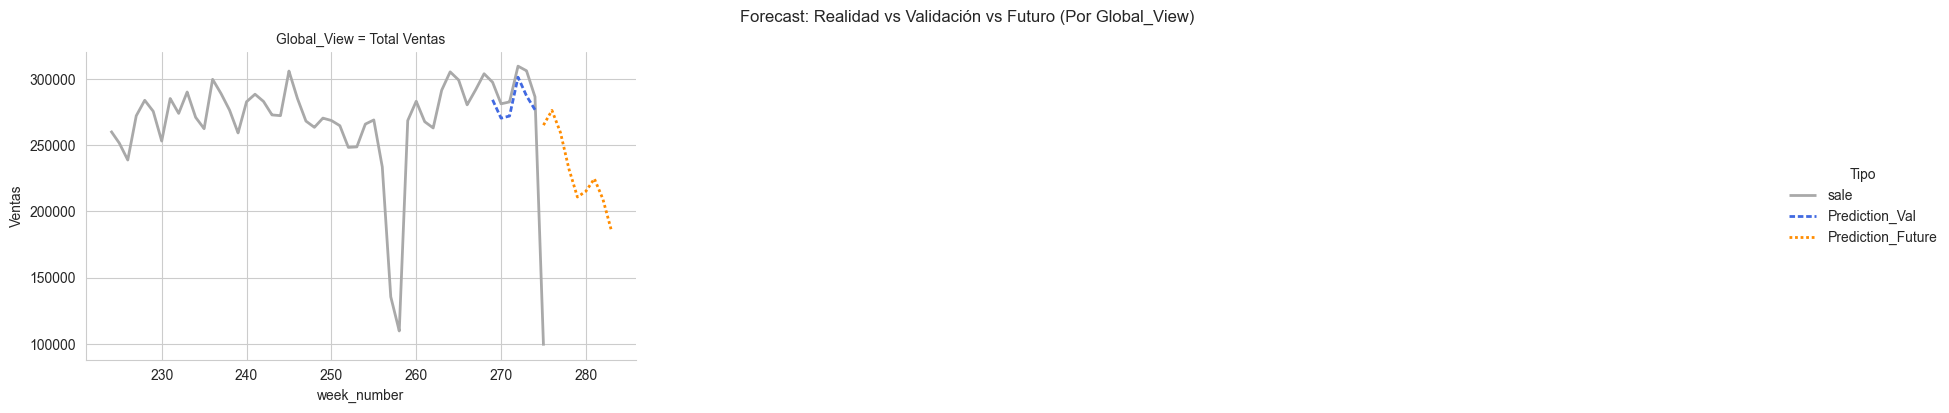

In [89]:
plot_full_forecast(
    df=df_viz, 
    col_category='Global_View', # Single group: whole company
    last_n_weeks=60
)

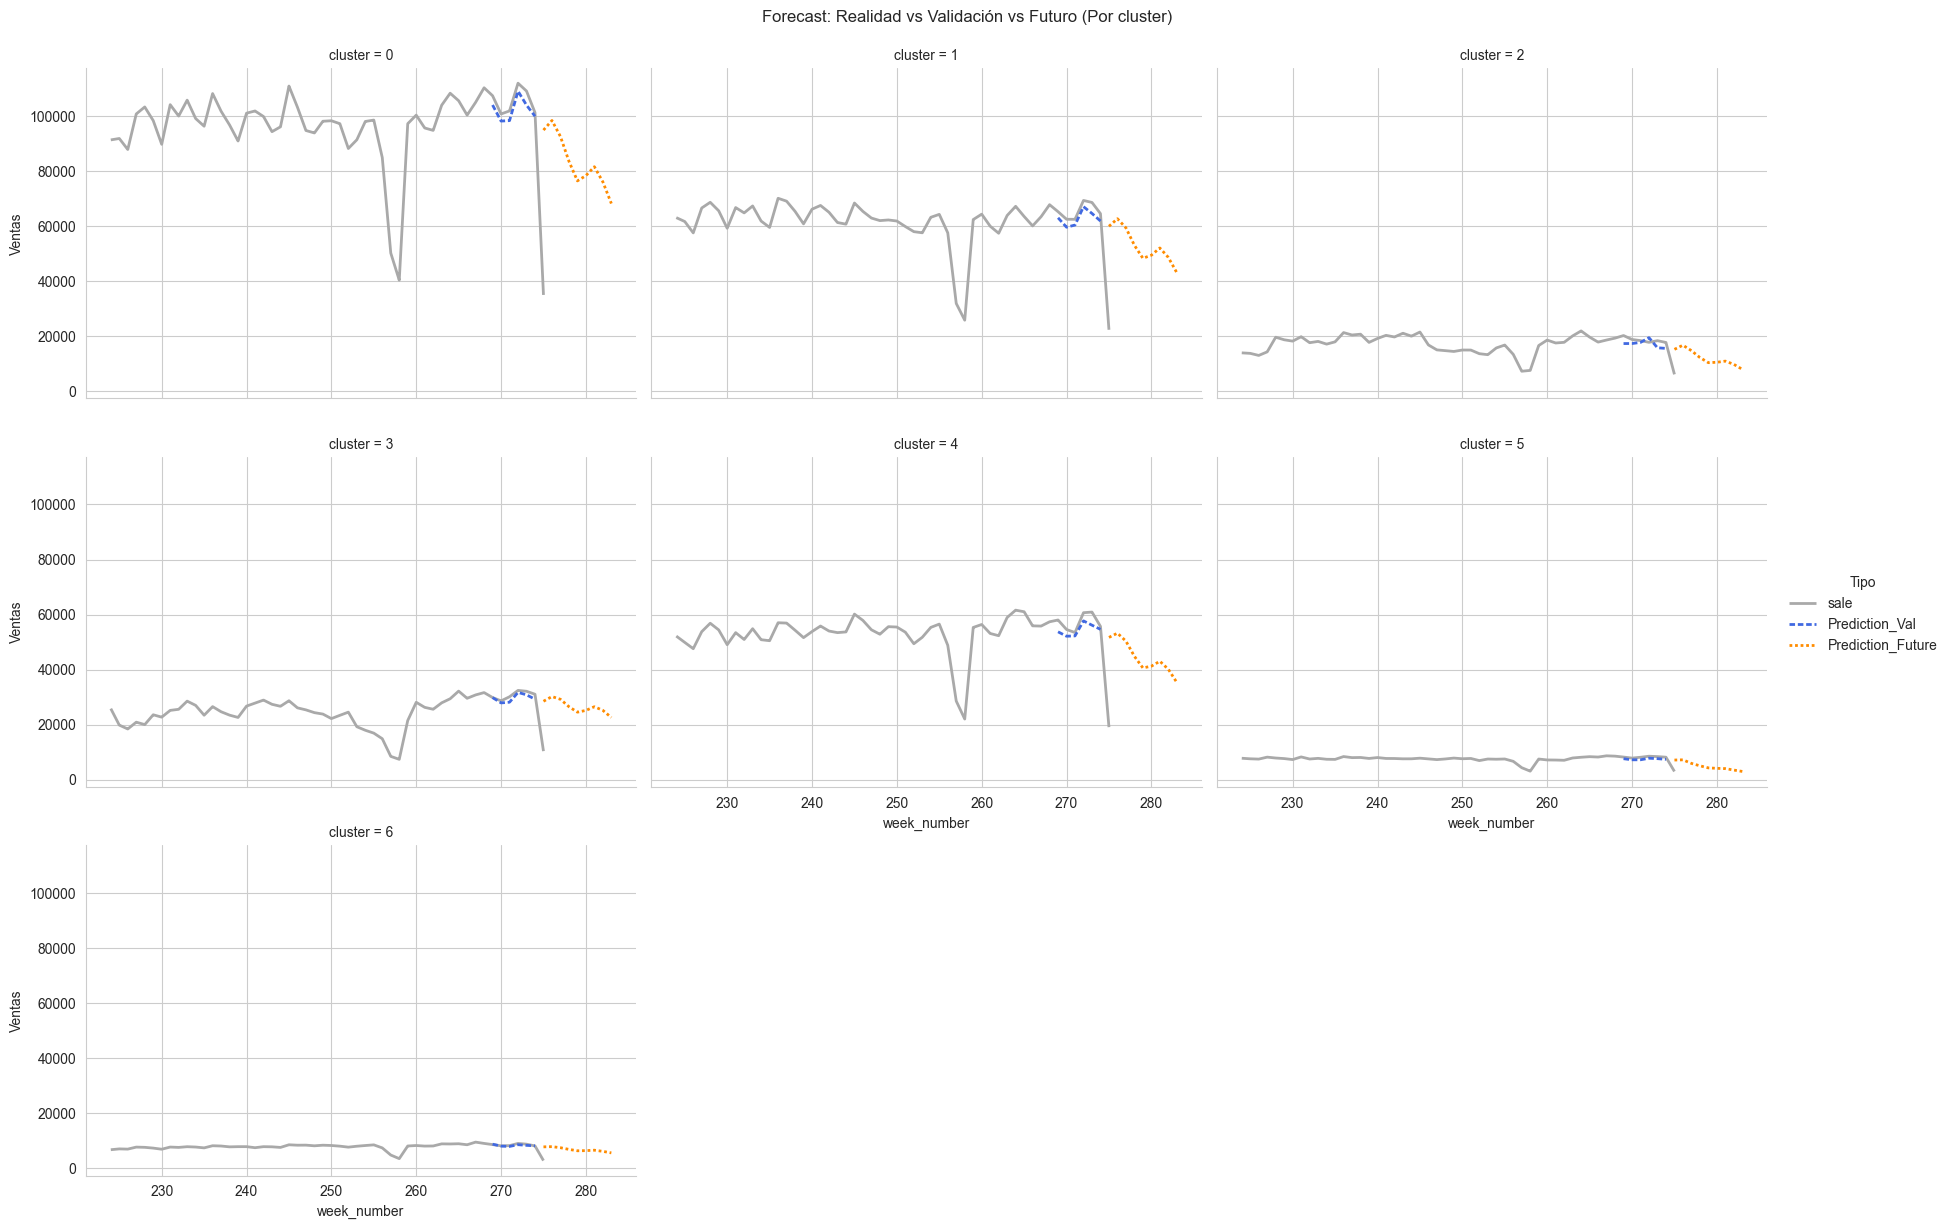

In [81]:

plot_full_forecast(df_viz, col_category='cluster', last_n_weeks=60)

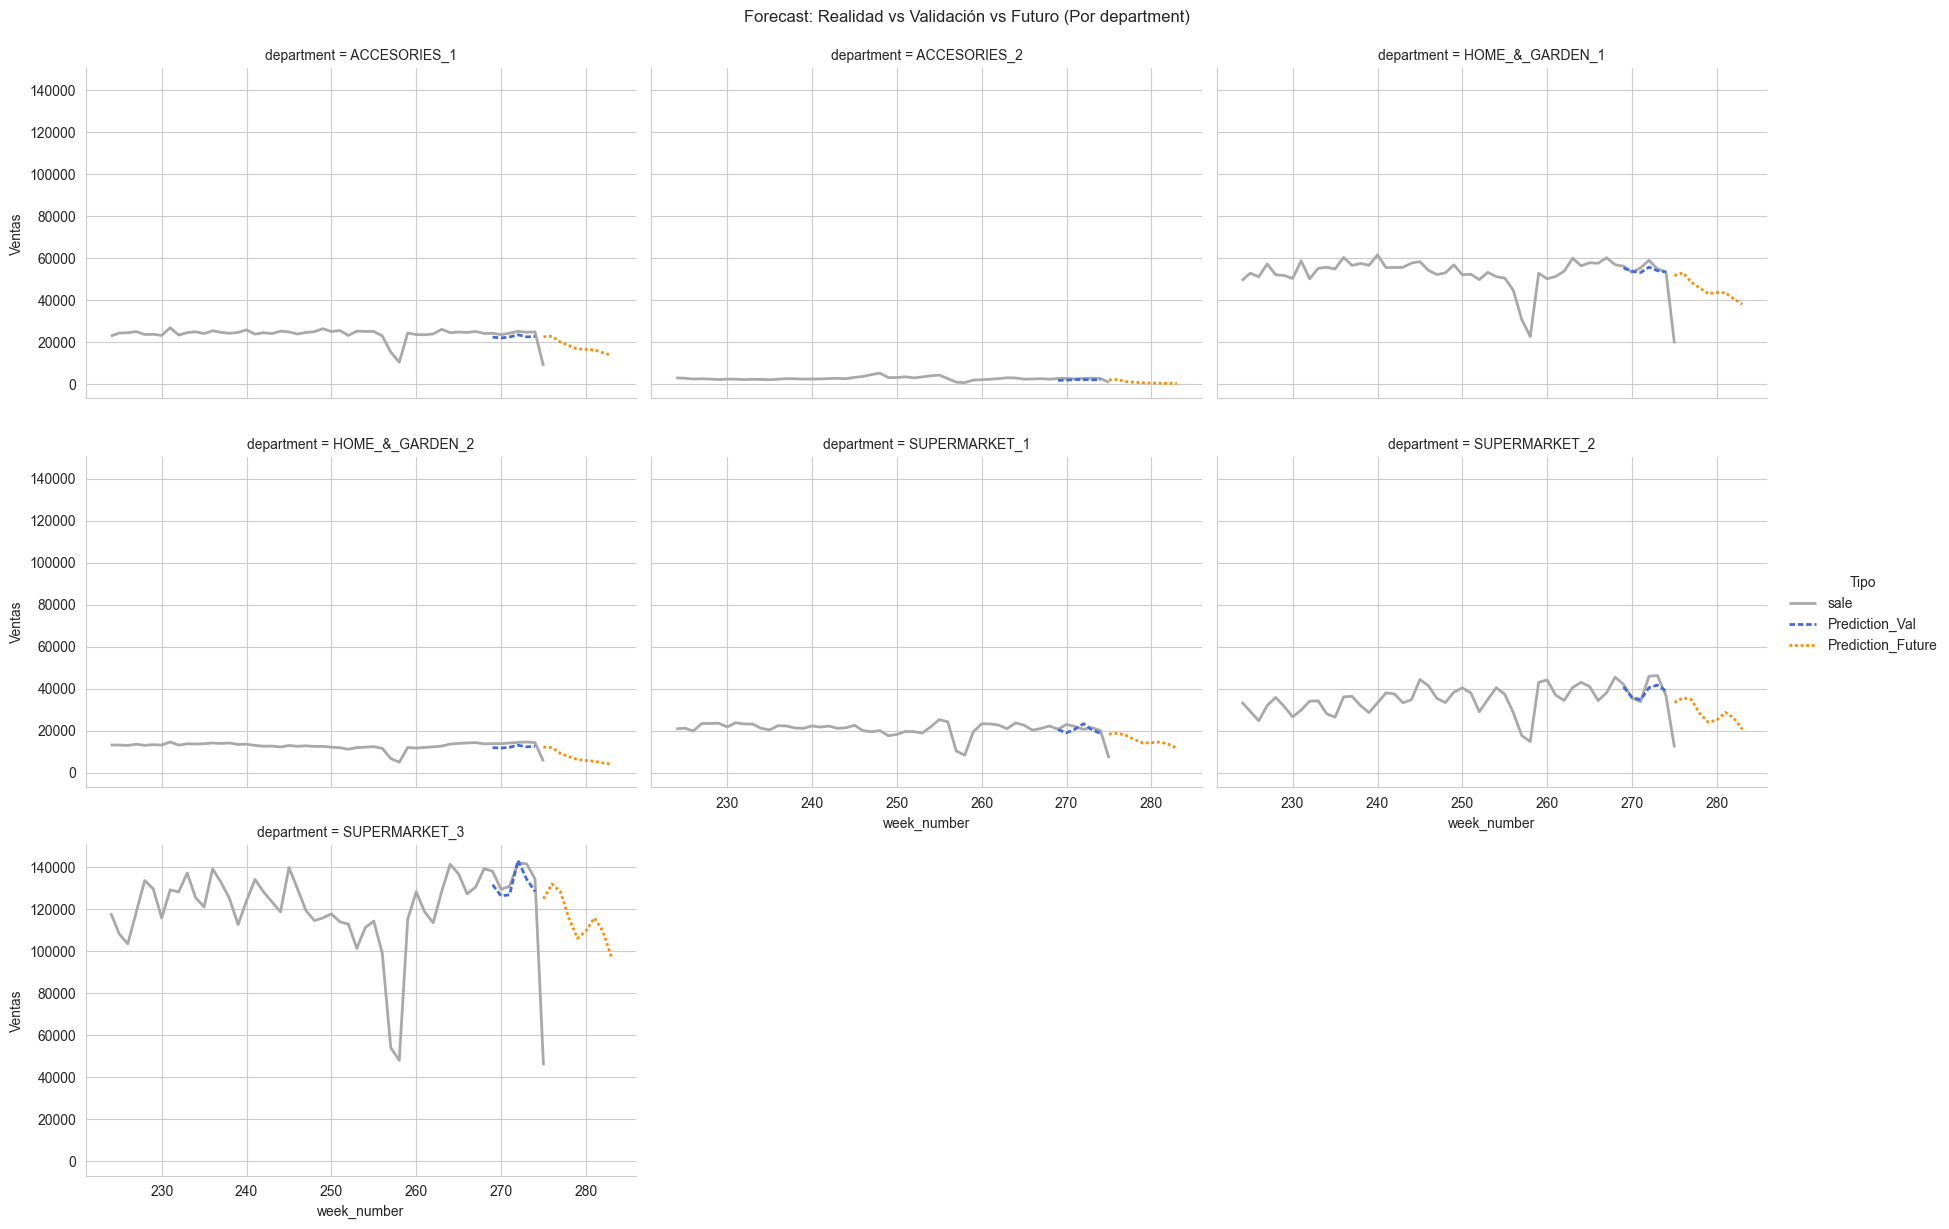

In [79]:
plot_full_forecast(df_viz, col_category='department', last_n_weeks=60)

#### Model tuning with Optuna (level target)

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error
from sklearn import set_config
import gc

# Configuration
set_config(transform_output="pandas")

# =============================================================================
# 1. FEATURE ENGINEERING (LEVEL TARGET, NO DIFFERENCING)
# =============================================================================
def engineering_features(df_input):
    """
    Lags and rolling means on the (transformed) level, NOT on differences.
    This is much more stable for recursive forecasting.
    """
    df = df_input.copy()
    
    # 1. Level transformation: square root
    # sqrt as the target
    df['target_level'] = np.sqrt(df['sale'])
    
    # 2. Lags of the LEVEL
    # The model learns: "if the level one week ago was 5, today it will be..."
    lags = [1, 4, 26, 52]
    for lag in lags:
        df[f'lag_{lag}'] = df.groupby('unique_id', sort=False)['target_level'].shift(lag)
        
    # 3. Rolling mean with shift
    df['rolling_mean_4'] = (
        df.groupby('unique_id', sort=False)['target_level']
        .shift(1)
        .rolling(window=4)
        .mean()
    )
    
    return df

# =============================================================================
# 2. DATA PREPARATION
# =============================================================================
# df_weekly_final must already be in memory

# Forward-fill static future features (price, cluster...)
print("Forward-filling future features...")
cols_to_fill = [c for c in df_weekly_final.columns if c not in ['sale', 'week_number', 'date', 'unique_id']]
df_weekly_final[cols_to_fill] = df_weekly_final.groupby('unique_id')[cols_to_fill].ffill()

# Week configuration
first_pred_week = 275
val_start_week = 268 

# Features
print("Generating features (level strategy)...")
df_features = engineering_features(df_weekly_final)

# Define X and y
# Note: the target is now 'target_level'; 'target_diff' no longer exists
cols_exclude = ['sale', 'target_level', 'date', 'unique_id', 'item', 'item_id']
features_cols = [c for c in df_features.columns if c not in cols_exclude]

# Cleaning
df_clean = df_features.dropna(subset=['target_level', 'lag_52'])

# Splits
mask_train = df_clean['week_number'] < val_start_week
mask_val = (df_clean['week_number'] >= val_start_week) & (df_clean['week_number'] < first_pred_week)

X_train_raw = df_clean.loc[mask_train, features_cols]
y_train = df_clean.loc[mask_train, 'target_level']

X_val_raw = df_clean.loc[mask_val, features_cols]
y_val = df_clean.loc[mask_val, 'target_level']

# Preprocessor (OHE)
# Defined outside Optuna so it runs once
def check_cardinality(df, threshold=50):
    cat_cols = df.select_dtypes(include=['object', 'category']).columns
    return [c for c in cat_cols if df[c].nunique() <= threshold]

cols_to_ohe = check_cardinality(X_train_raw)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32), 
         cols_to_ohe)
    ],
    verbose_feature_names_out=False,
    remainder='passthrough'
)

print("Preprocessing (fit OHE)...")
X_train_enc = preprocessor.fit_transform(X_train_raw)
X_val_enc = preprocessor.transform(X_val_raw)

# =============================================================================
# 3. OPTUNA TUNING (validation holdout)
# =============================================================================

def objective(trial):
    # Search space limited to avoid drift (over-regularisation)
    params = {
        'objective': 'reg:squarederror',
        'n_jobs': -1,
        'random_state': 42,
        'tree_method': 'hist', # Speed
        'n_estimators': 2000,  # Controlled by early stopping
        
        # Tree structure
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        
        # Learning rate and robustness
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.95),
        
        # Regularisation (very high values make predictions drift to zero)
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-5, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-5, 1.0, log=True),
    }
    
    model = xgb.XGBRegressor(**params, early_stopping_rounds=50)
    
    # Train
    model.fit(
        X_train_enc, y_train,
        eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)],
        verbose=False
    )
    
    # Evaluate (RMSE in units)
    # Predictions are in sqrt space -> square them
    preds_sqrt = model.predict(X_val_enc)
    preds_real = np.power(preds_sqrt, 2).clip(min=0)
    y_val_real = np.power(y_val, 2) # Target original real
    
    rmse = np.sqrt(mean_squared_error(y_val_real, preds_real))
    
    return rmse

print("Starting Optuna...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)

print(f"Best RMSE Val: {study.best_value:.4f}")
print("Best params:", study.best_params)



/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Rellenando features futuras (Forward Fill)...
Generando features (Estrategia Nivel)...
Preprocesando (Fit OHE)...
Iniciando Optuna...
Mejor RMSE Val: 8.3512
Mejores Params: {'max_depth': 10, 'min_child_weight': 20, 'learning_rate': 0.010101082033827813, 'subsample': 0.6049845298440193, 'colsample_bytree': 0.750449687882706, 'reg_alpha': 1.6584096422956563e-05, 'reg_lambda': 0.00043070949209727974}


In [ ]:

# =============================================================================
# 4. FINAL TRAINING AND RECURSIVE FORECAST (LEVEL MODEL)
# =============================================================================

# Best parameters
best_params = study.best_params
best_params['n_estimators'] = 2000
best_params['objective'] = 'reg:squarederror'
best_params['n_jobs'] = -1
best_params['tree_method'] = 'hist'

final_model_opt = xgb.XGBRegressor(**best_params, early_stopping_rounds=50)
final_model_opt.fit(
    X_train_enc, y_train,
    eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)],
    verbose=False
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.750449687882706
,device,None
,early_stopping_rounds,50
,enable_categorical,False
,eval_metric,None


In [96]:
future_mask = df_work['week_number'] >= first_pred_week
df_work.loc[future_mask, 'sale'] = np.nan

weeks_to_predict = range(first_pred_week, 283 + 1)
safe_window = 60

print(f"\nStarting recursive forecast (level model)...")

for week in weeks_to_predict:
    # 1. Slice & Feature Engineering
    min_week = week - safe_window
    cols_base = ['unique_id', 'week_number', 'sale']
    cols_needed = list(set(cols_base + features_cols).intersection(df_work.columns))
    
    df_slice = df_work.loc[df_work['week_number'] >= min_week, cols_needed].copy()
    
    # Sort so that the lags are correct
    df_slice.sort_values(['unique_id', 'week_number'], inplace=True)
    
    # Features (lags of the current/filled 'sale' level)
    df_dyn = engineering_features(df_slice)
    
    # 2. Select & Transform
    curr_mask = df_dyn['week_number'] == week
    X_curr_raw = df_dyn.loc[curr_mask, features_cols]
    
    if X_curr_raw.empty: continue
        
    X_curr_enc = preprocessor.transform(X_curr_raw)
    
    # 3. Predict (sqrt level, direct)
    pred_sqrt = final_model_opt.predict(X_curr_enc)
    
    # 4. Invert (square) - direct level, no cumulative sum
    pred_real = np.power(pred_sqrt, 2).clip(min=0)
    
    # Diagnostics
    # print(f"S{week} Mean Sales: {pred_real.mean():.2f}")
    
    # 5. Update
    df_work.loc[X_curr_raw.index, 'sale'] = pred_real

print("Done.")
print(df_work[df_work['week_number'] >= first_pred_week][['unique_id', 'week_number', 'sale']].head())


Iniciando predicción recursiva (Modelo Nivel)...
Proceso finalizado.
                   unique_id  week_number      sale
1303  ACCESORIES_1_001_BOS_1          275  1.156922
1304  ACCESORIES_1_001_BOS_2          275  1.708489
1305  ACCESORIES_1_001_BOS_3          275  2.660340
1306  ACCESORIES_1_001_NYC_1          275  4.546512
1307  ACCESORIES_1_001_NYC_2          275  5.337120



Generando visualización...


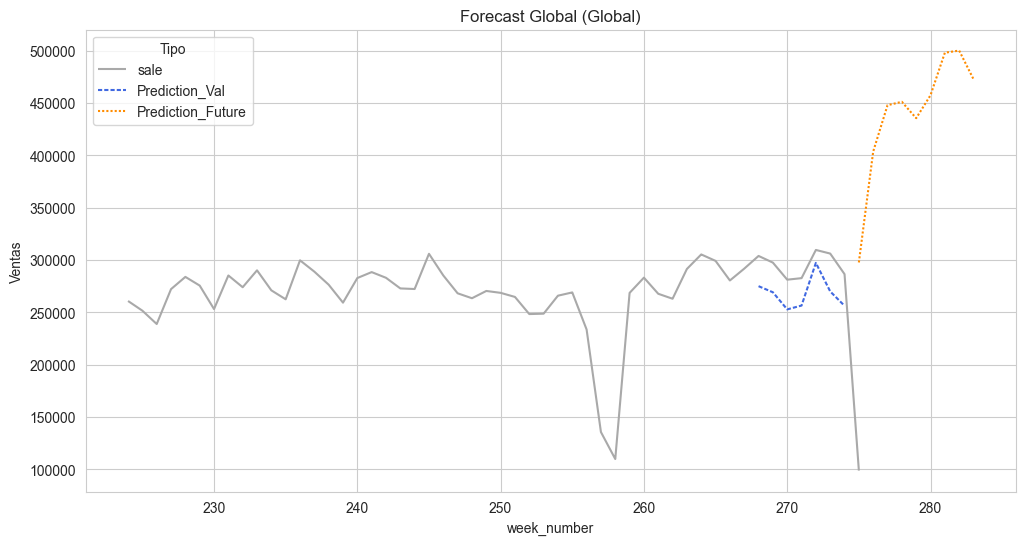

<Figure size 1200x600 with 0 Axes>

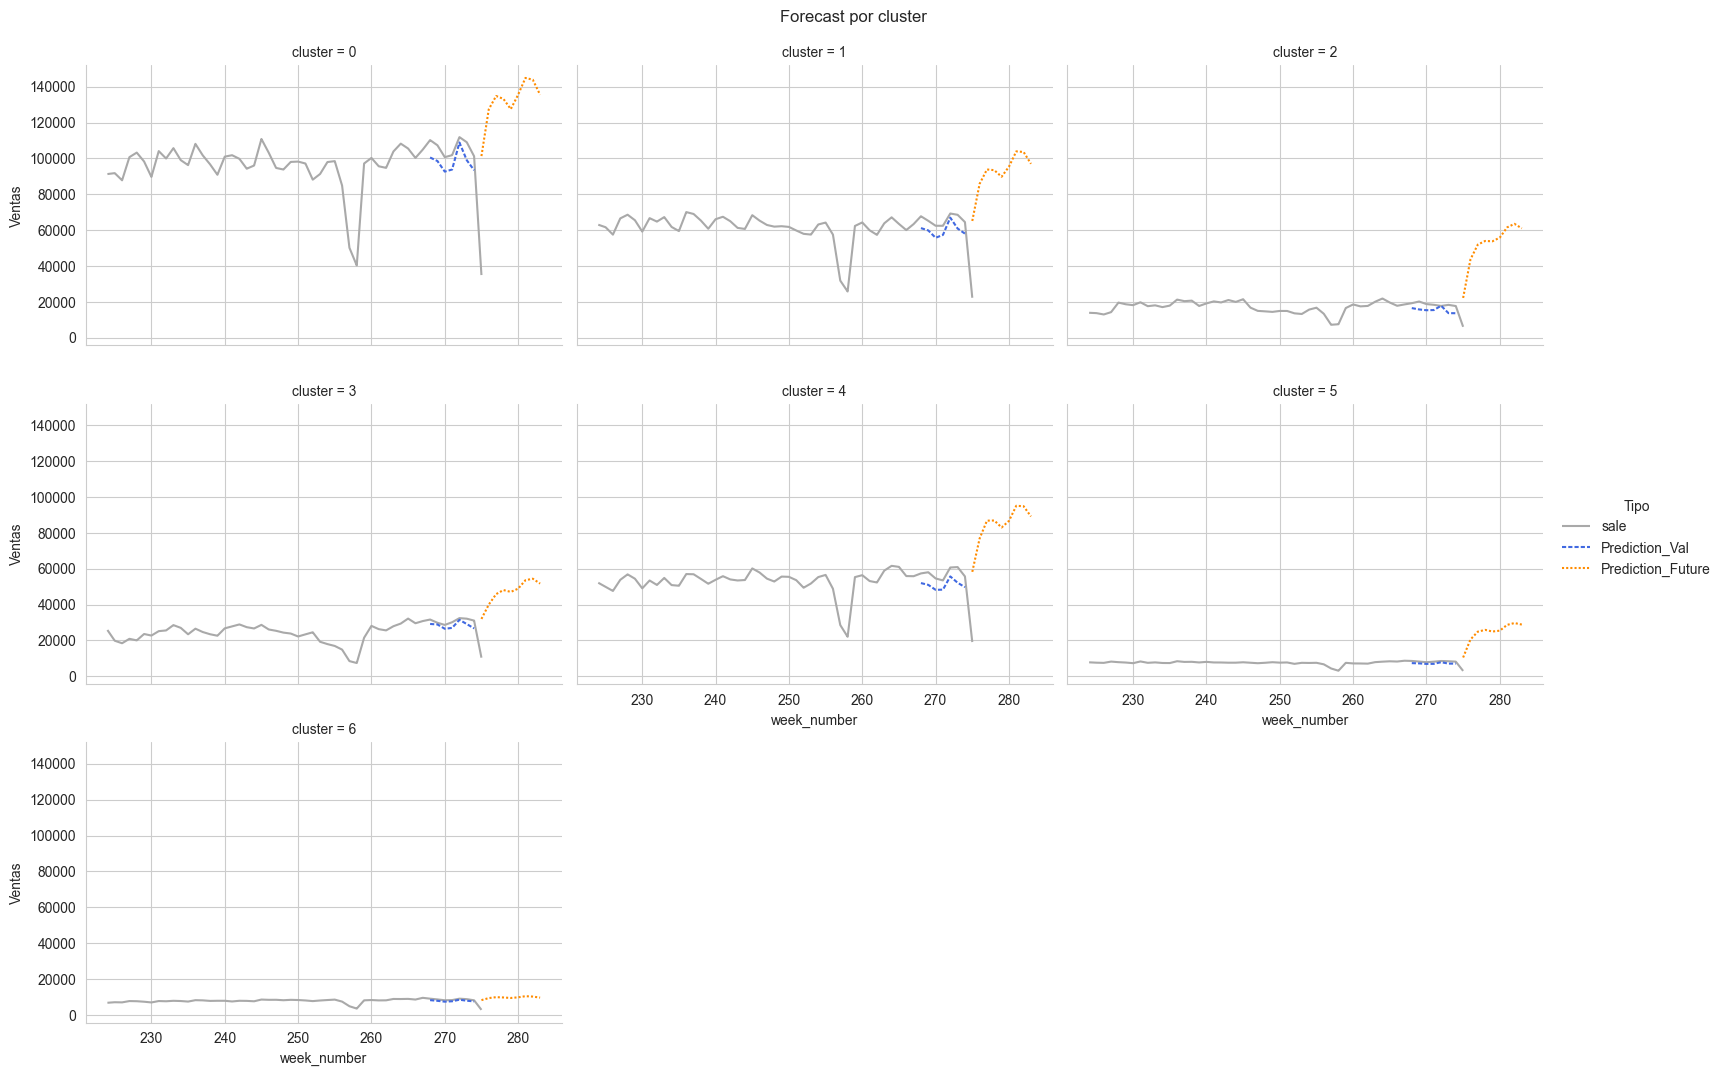

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

print("\nBuilding plots...")

# 1. Validation predictions (for comparison)
# The model predicts sqrt; square to get units
val_preds_sqrt = final_model_opt.predict(X_val_enc)
val_preds_real = np.power(val_preds_sqrt, 2).clip(min=0)

# 2. Visualisation DataFrame
# Base columns
cols_viz = ['unique_id', 'week_number', 'sale', 'cluster', 'store_code', 'department']
cols_viz = [c for c in cols_viz if c in df_weekly_final.columns]
df_viz = df_weekly_final[cols_viz].copy()

# Prediction columns
df_viz['Prediction_Val'] = np.nan
df_viz['Prediction_Future'] = np.nan

# Validation predictions (X_val_raw index)
df_viz.loc[X_val_raw.index, 'Prediction_Val'] = val_preds_real

# Forecast (future index in df_work)
# df_work holds the forecast in 'sale'; copy it to 'Prediction_Future'
future_indices = df_work[df_work['week_number'] >= first_pred_week].index
df_viz.loc[future_indices, 'Prediction_Future'] = df_work.loc[future_indices, 'sale']

# 3. Plot function
def plot_full_forecast(df, col_category, col_actual='sale', last_n_weeks=52):
    """
    Plot history (grey), validation (blue) and forecast (orange).
    """
    # Time window
    max_week = df['week_number'].max()
    min_week = max_week - last_n_weeks
    df_filtered = df[df['week_number'] > min_week].copy()
    
    # Aggregate (sum of sales by week and category)
    cols_pred = ['Prediction_Val', 'Prediction_Future']
    df_grouped = df_filtered.groupby(['week_number', col_category])[[col_actual] + cols_pred].sum(min_count=1).reset_index()
    
    # Melt for seaborn
    df_melted = df_grouped.melt(
        id_vars=['week_number', col_category],
        value_vars=[col_actual] + cols_pred,
        var_name='Type', value_name='Sales'
    )
    
    # Styles
    palette = {col_actual: 'darkgrey', 'Prediction_Val': 'royalblue', 'Prediction_Future': 'darkorange'}
    styles = {col_actual: (1,0), 'Prediction_Val': (2,1), 'Prediction_Future': (1,1)}
    
    plt.figure(figsize=(12, 6))
    sns.set_style("whitegrid")
    
    # Several categories: FacetGrid (relplot)
    if df_grouped[col_category].nunique() > 1:
        g = sns.relplot(
            data=df_melted, x='week_number', y='Sales',
            col=col_category, hue='Type', style='Type',
            palette=palette, dashes=styles, kind='line',
            col_wrap=3, height=3.5, aspect=1.5
        )
        g.fig.suptitle(f'Forecast by {col_category}', y=1.02)
    
    # Single category (global): plain lineplot
    else:
        sns.lineplot(
            data=df_melted, x='week_number', y='Sales',
            hue='Type', style='Type', palette=palette, dashes=styles
        )
        plt.title(f'Forecast Global ({col_category})')
        
    plt.show()

# 4. Plots

# A. Global (company total)
df_viz['Global'] = 'Total sales'
plot_full_forecast(df_viz, 'Global', last_n_weeks=60)

# B. By category (if 'cluster' or 'store_code' exists)
if 'cluster' in df_viz.columns:
    plot_full_forecast(df_viz, 'cluster', last_n_weeks=60)
elif 'store_code' in df_viz.columns:
    plot_full_forecast(df_viz, 'store_code', last_n_weeks=60)

### Lasso – linear regression
Finally, we use the Lasso linear regression. After tuning it gave (section 6):

Best alpha: 0.001960

RMSE Val (units): 8.70

NRMSE (RMSE / mean sales): 107.36%

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn import set_config

# Configuration
set_config(transform_output="pandas")

# =============================================================================
# 0. UTILITIES
# =============================================================================
def downcast_dtypes(df):
    fcols = df.select_dtypes('float').columns
    icols = df.select_dtypes('integer').columns
    df[fcols] = df[fcols].apply(pd.to_numeric, downcast='float')
    df[icols] = df[icols].apply(pd.to_numeric, downcast='integer')
    return df

# =============================================================================
# 1. FEATURE ENGINEERING (RAW VERSION FOR LASSO)
# =============================================================================
def engineering_features_raw(df_input):
    """
    Lags and rolling means of RAW (untransformed) sales.
    The Lasso pipeline applies the sqrt transform internally.
    """
    df = df_input.copy()
    
    # Note: 'sale' is not transformed here.
    
    # 1. Lags of real sales
    lags = [1, 4, 26, 52]
    for lag in lags:
        df[f'lag_{lag}'] = df.groupby('unique_id')['sale'].shift(lag)
        
    # 2. Rolling mean of real sales (shifted to avoid leakage)
    df['rolling_mean_4'] = (
        df.groupby('unique_id')['sale']
        .shift(1)
        .rolling(window=4)
        .mean()
    )
    
    return df

# =============================================================================
# 2. DATA PREPARATION AND TRAINING
# =============================================================================
# df_weekly_final must already be in memory

print("Preparing data for the Lasso model...")
df_weekly_final = downcast_dtypes(df_weekly_final)

# Week configuration
first_pred_week = 275
last_pred_week = 283
safe_history_window = 60 # Weeks of history needed to compute the lags

# Working copy
df_work = df_weekly_final.copy()

# A. Clear the future target
future_mask = df_work['week_number'] >= first_pred_week
df_work.loc[future_mask, 'sale'] = np.nan

# B. Forward-fill future features (prices, stores, etc.)
# Carry the last known value forward
print("Forward-filling static future features...")
cols_static = [c for c in df_work.columns if c not in ['sale', 'week_number', 'date', 'unique_id']]
df_work[cols_static] = df_work.groupby('unique_id')[cols_static].ffill()

# C. Historical features for training
print("Generating historical features...")
df_features_history = engineering_features_raw(df_work)

# D. X and y for training
# All history up to the first forecast week (weeks < 275)
train_mask = df_features_history['week_number'] < first_pred_week

# Drop the initial rows without lag_52
df_train_clean = df_features_history[train_mask].dropna(subset=['lag_52'])

# Columns
cols_exclude = ['sale', 'week_number', 'date', 'unique_id', 'item', 'item_id']
features_cols = [c for c in df_features_history.columns if c not in cols_exclude]

X_train = df_train_clean[features_cols]
y_train = df_train_clean['sale'] # Raw target (the pipeline applies sqrt)

print(f"Training on {len(X_train)} rows and {len(features_cols)} features.")



Preparando datos para entrenamiento Lasso...
Rellenando features estáticas futuras...
Generando features históricas...
Entrenando con 3859948 filas y 24 features.


In [103]:
# =============================================================================
# 3. PIPELINE (same structure as the validated Lasso)
# =============================================================================

# NUMERIC and CATEGORICAL columns by dtype
numeric_features = X_train.select_dtypes(include=['number']).columns
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns

# Numeric columns that get the sqrt treatment
cols_lags = [c for c in numeric_features if 'lag' in c or 'rolling' in c or 'shift' in c]
# Other numeric columns (excluding lags)
cols_resto = [c for c in numeric_features if c not in cols_lags]

# A. Lag pipeline (imputer -> sqrt -> scaler)
# Keeps the lags linearly related to the sqrt target
lag_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('transform', FunctionTransformer(np.sqrt, validate=False, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

# B. Generic numeric pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# C. Categorical pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32))
])

# D. ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, make_column_selector(dtype_include=['object', 'category'])),
        ('num_lags', lag_transformer, cols_lags),
        ('num_resto', numeric_transformer, cols_resto)
    ],
    verbose_feature_names_out=False,
    remainder='drop'
)

# E. Final model with the tuned alpha
alpha_optimo = 0.001960

lasso_base = Lasso(
    alpha=alpha_optimo,
    random_state=42, 
    max_iter=10000 
)

# F. TransformedTargetRegressor (target -> sqrt)
model_lasso_optimized = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', lasso_base)
    ]),
    func=np.sqrt, 
    inverse_func=lambda y: np.power(y, 2),
    check_inverse=False
)

# G. Train
print(f"Training Lasso (alpha={alpha_optimo})...")
model_lasso_optimized.fit(X_train, y_train)
print("Model trained.")

# =============================================================================
# 4. RECURSIVE FORECAST (LASSO)
# =============================================================================
weeks_to_predict = range(first_pred_week, last_pred_week + 1)

print(f"\nStarting recursive forecast...")

# Predictions are float64: cast the target first (avoids a pandas incompatible-dtype warning)
df_work['sale'] = df_work['sale'].astype('float64')

for week in weeks_to_predict:
    # 1. Slice the recent history
    min_week = week - safe_history_window
    # All columns are kept because the Lasso pipeline selects them internally
    # (they could be filtered to save memory).
    df_slice = df_work[df_work['week_number'] >= min_week].copy()
    
    # Sort so the lags are computed correctly
    df_slice.sort_values(['unique_id', 'week_number'], inplace=True)
    
    # 2. Features (raw)
    # lag_1, lag_4... in units (e.g. 100, 200...)
    df_dyn = engineering_features_raw(df_slice)
    
    # 3. Current week
    current_mask = df_dyn['week_number'] == week
    
    # Feature columns
    # The pipeline selects columns by name, so X must keep its column names
    X_current = df_dyn.loc[current_mask, features_cols]
    
    if X_current.empty: continue
    
    # 4. PREDICT
    # 'model_lasso_optimized' is a TransformedTargetRegressor.
    # When calling .predict():
    #   a) the inner pipeline transforms the features (imputer -> sqrt -> scaler -> OHE)
    #   b) Lasso predicts in sqrt space
    #   c) TransformedTargetRegressor inverts the prediction (squares it)
    #   d) result: sales in units
    
    # Only X_current is passed; the pipeline selects the columns it needs.
    preds_real = model_lasso_optimized.predict(X_current)
    
    # Clip at 0 (sales cannot be negative)
    preds_real = np.clip(preds_real, a_min=0, a_max=None)
    
    # 5. UPDATE
    df_work.loc[X_current.index, 'sale'] = preds_real
    
    # Quick diagnostics
    # print(f"S{week} | Mean prediction: {preds_real.mean():.2f}")

print("Forecast finished.")


Entrenando Lasso (Alpha=0.00196)...


Modelo entrenado.

Iniciando predicción recursiva...


Predicción finalizada.


In [ ]:
# DataFrame for plotting
df_viz_lasso = df_weekly_final.copy()
df_viz_lasso['Prediction_Future'] = np.nan
df_viz_lasso['Prediction_Val'] = np.nan # In-sample fit (weeks 245-274, model trained on weeks < 275)

# 1. Forecast
future_idx = df_work[df_work['week_number'] >= first_pred_week].index
df_viz_lasso.loc[future_idx, 'Prediction_Future'] = df_work.loc[future_idx, 'sale']

# 2. Fitted values for the last 30 known weeks (IN-SAMPLE: these weeks are in the training set)
print("Generating in-sample fitted values for plotting...")
val_start_week = first_pred_week - 30
mask_val_viz = (df_features_history['week_number'] >= val_start_week) & (df_features_history['week_number'] < first_pred_week)

if mask_val_viz.any():
    X_val_viz = df_features_history.loc[mask_val_viz, features_cols]
    # Predict with the pipeline (applies sqrt/scaler/etc.)
    preds_val_viz = model_lasso_optimized.predict(X_val_viz)
    preds_val_viz = np.clip(preds_val_viz, a_min=0, a_max=None)
    
    # Assign to the plotting DataFrame
    df_viz_lasso.loc[X_val_viz.index, 'Prediction_Val'] = preds_val_viz




Generando predicciones de validación para visualizar...


#### Out-of-sample check of the final Lasso

The final model is trained on all weeks < 275, so its fitted values for weeks 245–274 (`Prediction_Val`) are **in-sample**: the R² of 0.83 originally shown in the evaluation chart was an in-sample fit. Below, the same pipeline (same alpha and preprocessing) is trained only on weeks < 255 and evaluated on weeks 255–274. The evaluation charts in section 9 use these out-of-sample predictions.

In [ ]:
# Out-of-sample evaluation of the final Lasso.
# model_lasso_optimized was trained on ALL weeks < 275, so 'Prediction_Val' (weeks 245-274) is an in-sample fit.
# Here an identical pipeline (same alpha and preprocessing) is trained only on weeks < 255
# and evaluated on weeks 255-274, which it has never seen.
# One-step-ahead: lag features use actual past sales, as in the validation of the other models.
from sklearn.base import clone

oos_start_week = 255

df_train_oos = df_features_history[df_features_history['week_number'] < oos_start_week].dropna(subset=['lag_52'])
model_lasso_oos = clone(model_lasso_optimized)
model_lasso_oos.fit(df_train_oos[features_cols], df_train_oos['sale'])

mask_oos = (df_features_history['week_number'] >= oos_start_week) & (df_features_history['week_number'] < first_pred_week)
X_oos = df_features_history.loc[mask_oos, features_cols]

df_viz_lasso['Prediction_Val_OOS'] = np.nan
df_viz_lasso.loc[X_oos.index, 'Prediction_Val_OOS'] = np.clip(model_lasso_oos.predict(X_oos), a_min=0, a_max=None)

print(f"Trained on weeks < {oos_start_week} ({len(df_train_oos):,} rows); "
      f"evaluated on weeks {oos_start_week}-{first_pred_week - 1} ({len(X_oos):,} rows)")

In [142]:
def plot_lasso_forecast(df, col_category):
    # Columns to plot
    cols_plot = ['sale', 'Prediction_Future', 'Prediction_Val']
    
    # Aggregate by summing
    df_grouped = df.groupby(['week_number', col_category])[cols_plot].sum(min_count=1).reset_index()
    
    # Melt to long format
    df_melt = df_grouped.melt(id_vars=['week_number', col_category], var_name='Type', value_name='Sales')
    
    # Last 60 weeks
    last_weeks = 60
    max_wk = df['week_number'].max()
    df_melt = df_melt[df_melt['week_number'] > (max_wk - last_weeks)]
    
    # Styles
    custom_palette = {'sale': 'grey', 'Prediction_Future': 'red', 'Prediction_Val': 'blue'}
    custom_styles = {'sale': (1,0), 'Prediction_Future': (1,0), 'Prediction_Val': (2,2)}
    
    sns.relplot(
        data=df_melt, x='week_number', y='Sales', 
        col=col_category, 
        hue='Type', style='Type', # style drives the dashes
        dashes=custom_styles, palette=custom_palette,
        kind='line', linewidth=3,
        col_wrap=3, height=9, aspect=1.5,
        
    )
    plt.show()

In [259]:
df_viz_lasso_wo_last_week = df_viz_lasso[~((df_viz_lasso['week_number'] == 275) & (df_viz_lasso['Prediction_Val'] != 0))].copy()

Note: in the plots below, the dashed blue line (`Prediction_Val`, weeks 245–274) is the **in-sample fit** of the final Lasso, which was trained on all weeks < 275. The out-of-sample evaluation is in section 9.

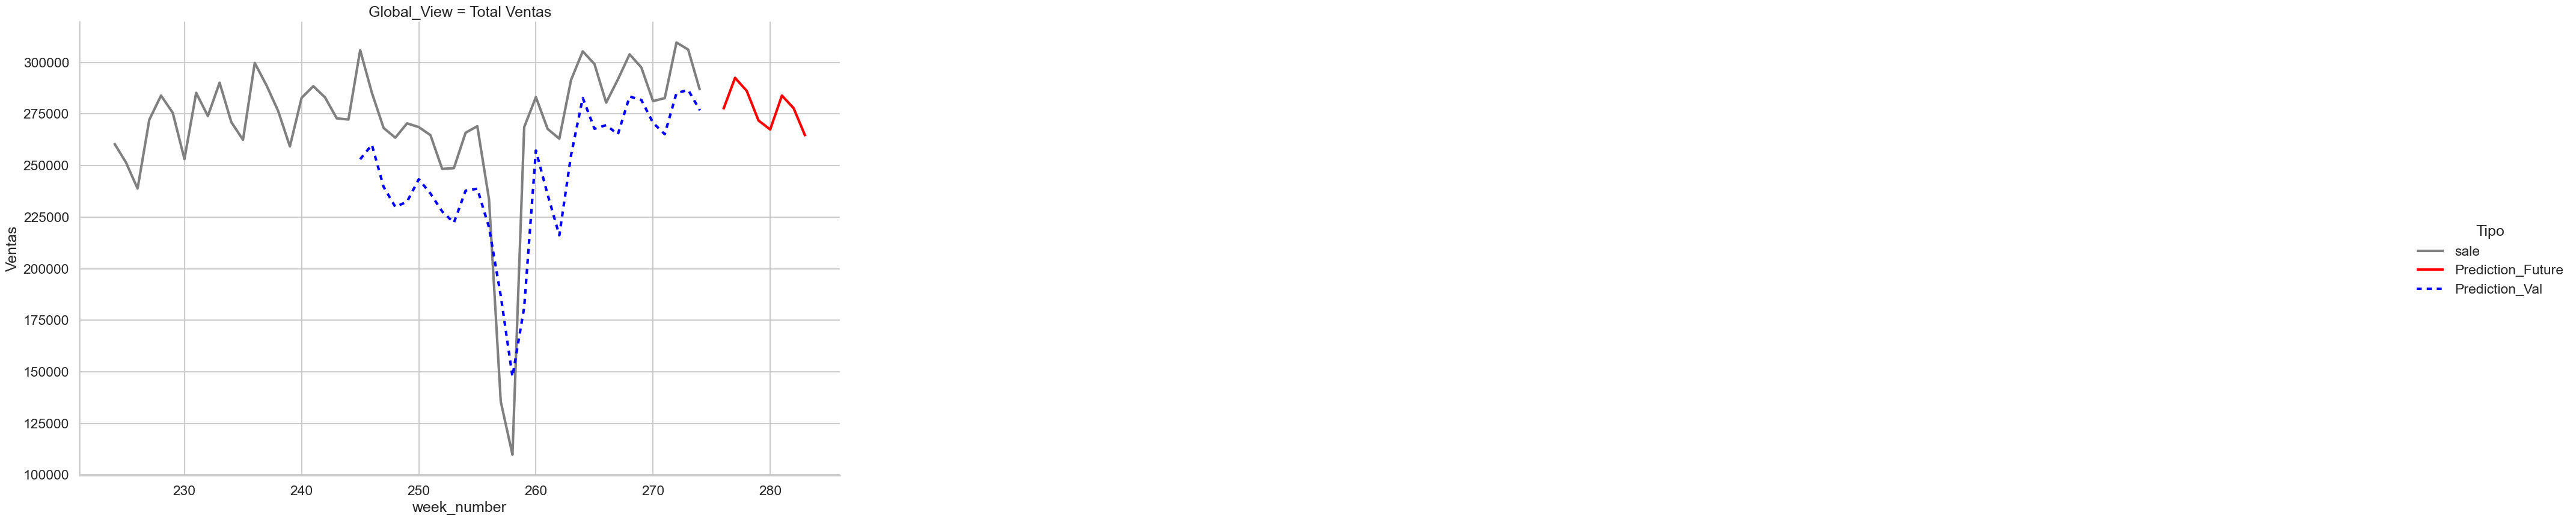

In [261]:
# Constant column to aggregate everything into one series
df_viz_lasso_wo_last_week['Global_View'] = 'Total sales'

plot_lasso_forecast(
    df=df_viz_lasso_wo_last_week, 
    col_category='Global_View' # Single group: whole company
)


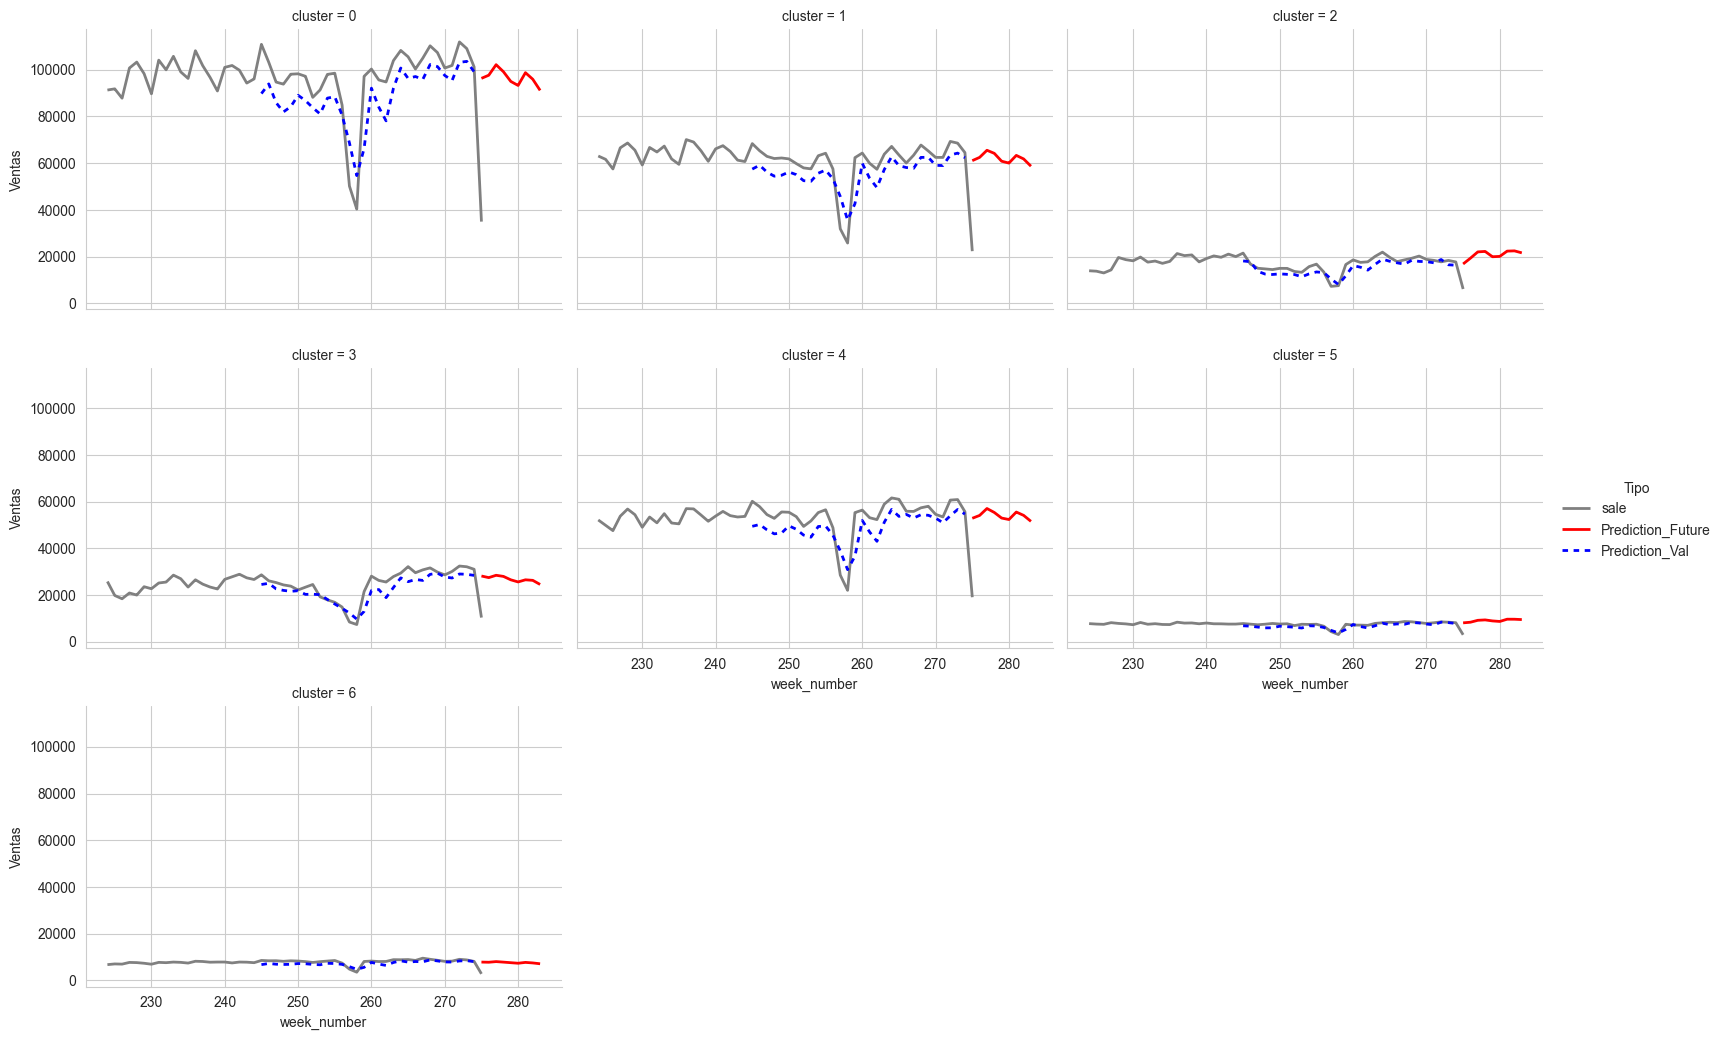

In [120]:
plot_lasso_forecast(df_viz_lasso, 'cluster')

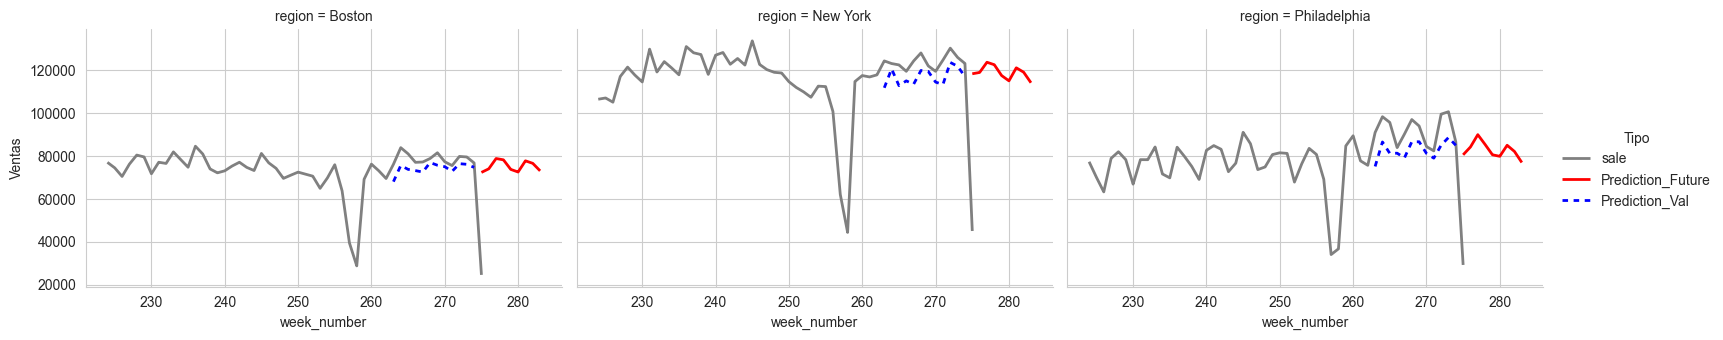

In [115]:
plot_lasso_forecast(df_viz_lasso, 'region')


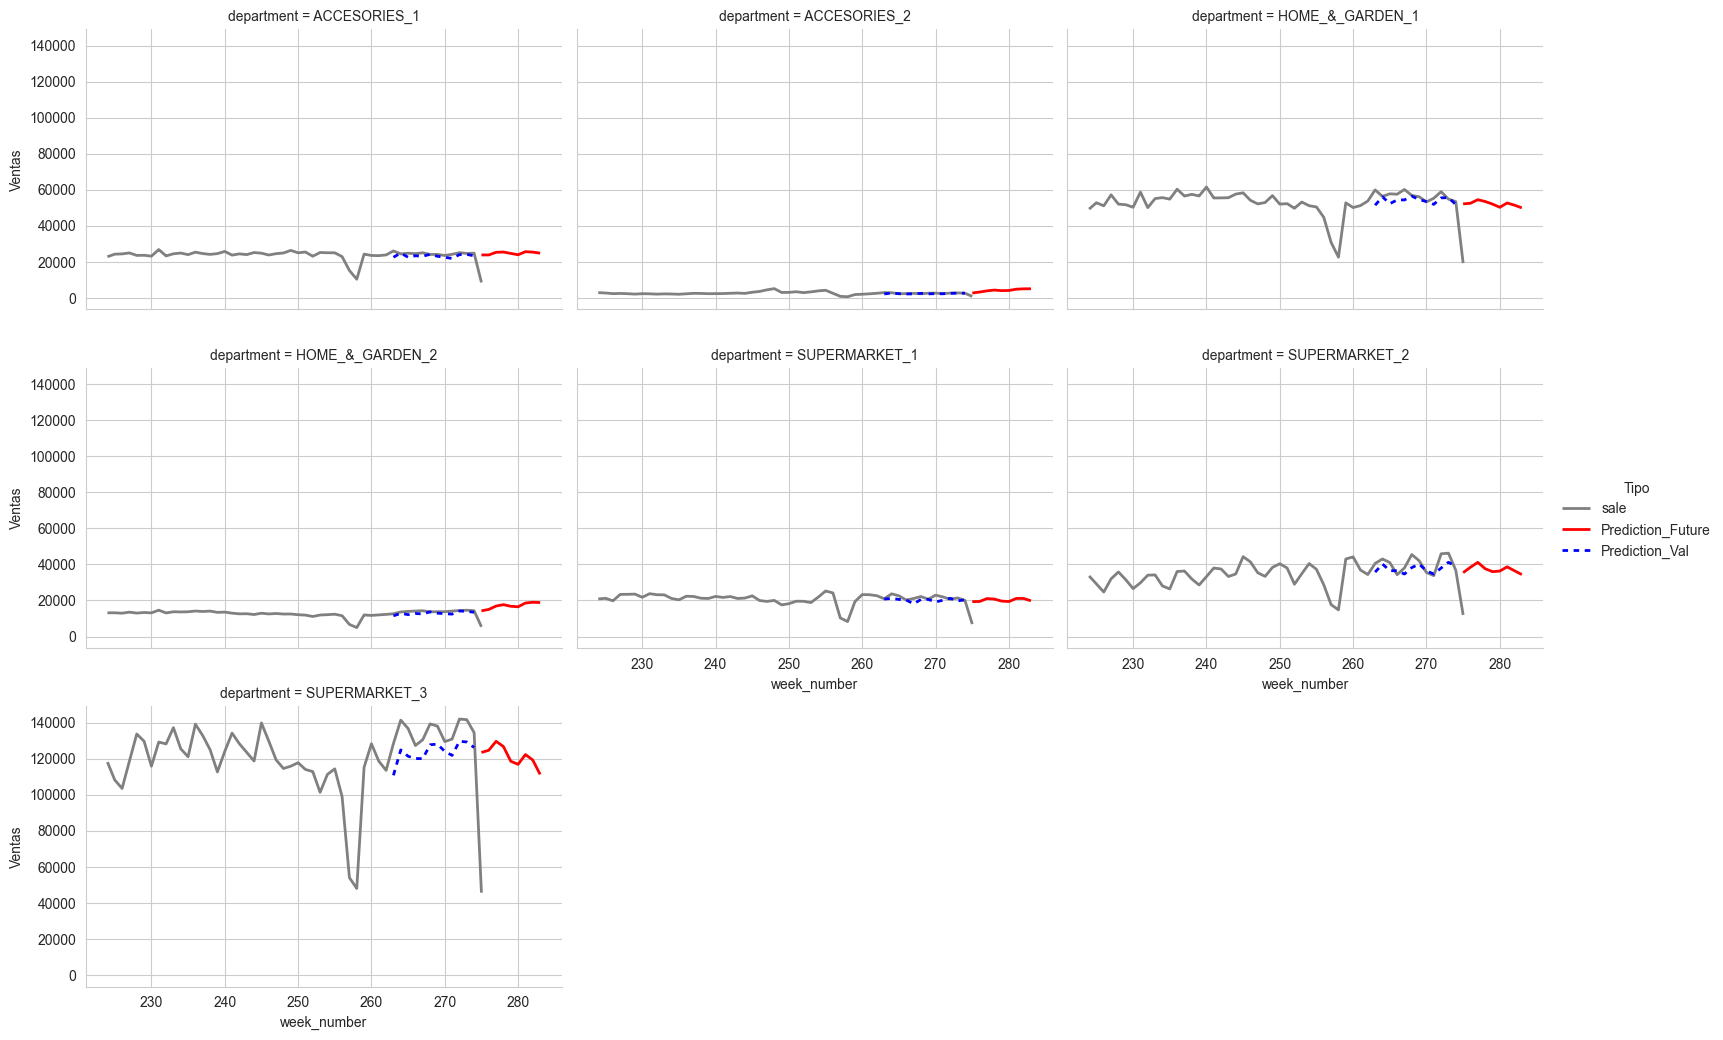

In [116]:
plot_lasso_forecast(df_viz_lasso, 'department')


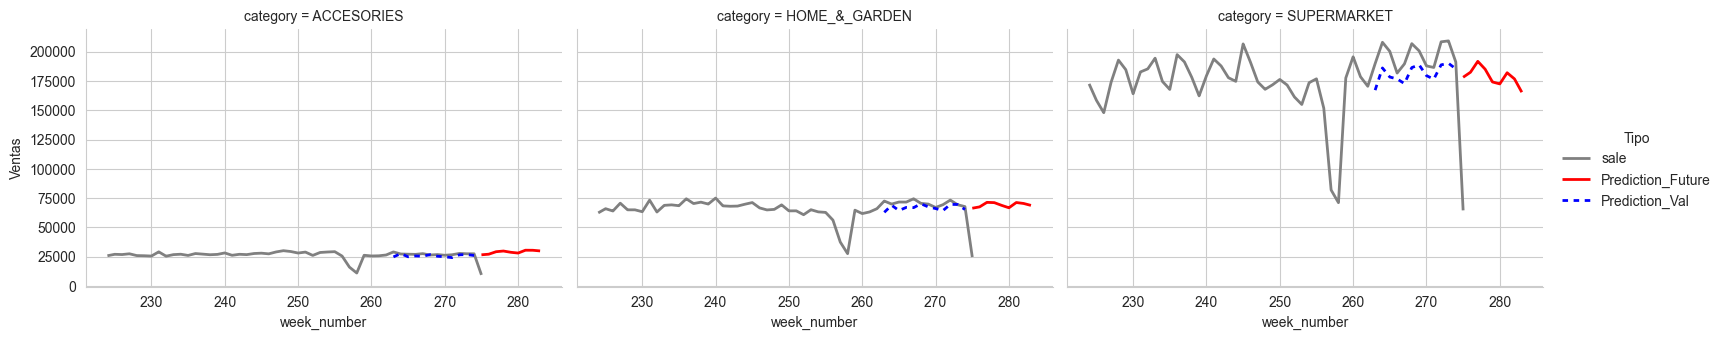

In [117]:
plot_lasso_forecast(df_viz_lasso, 'category')


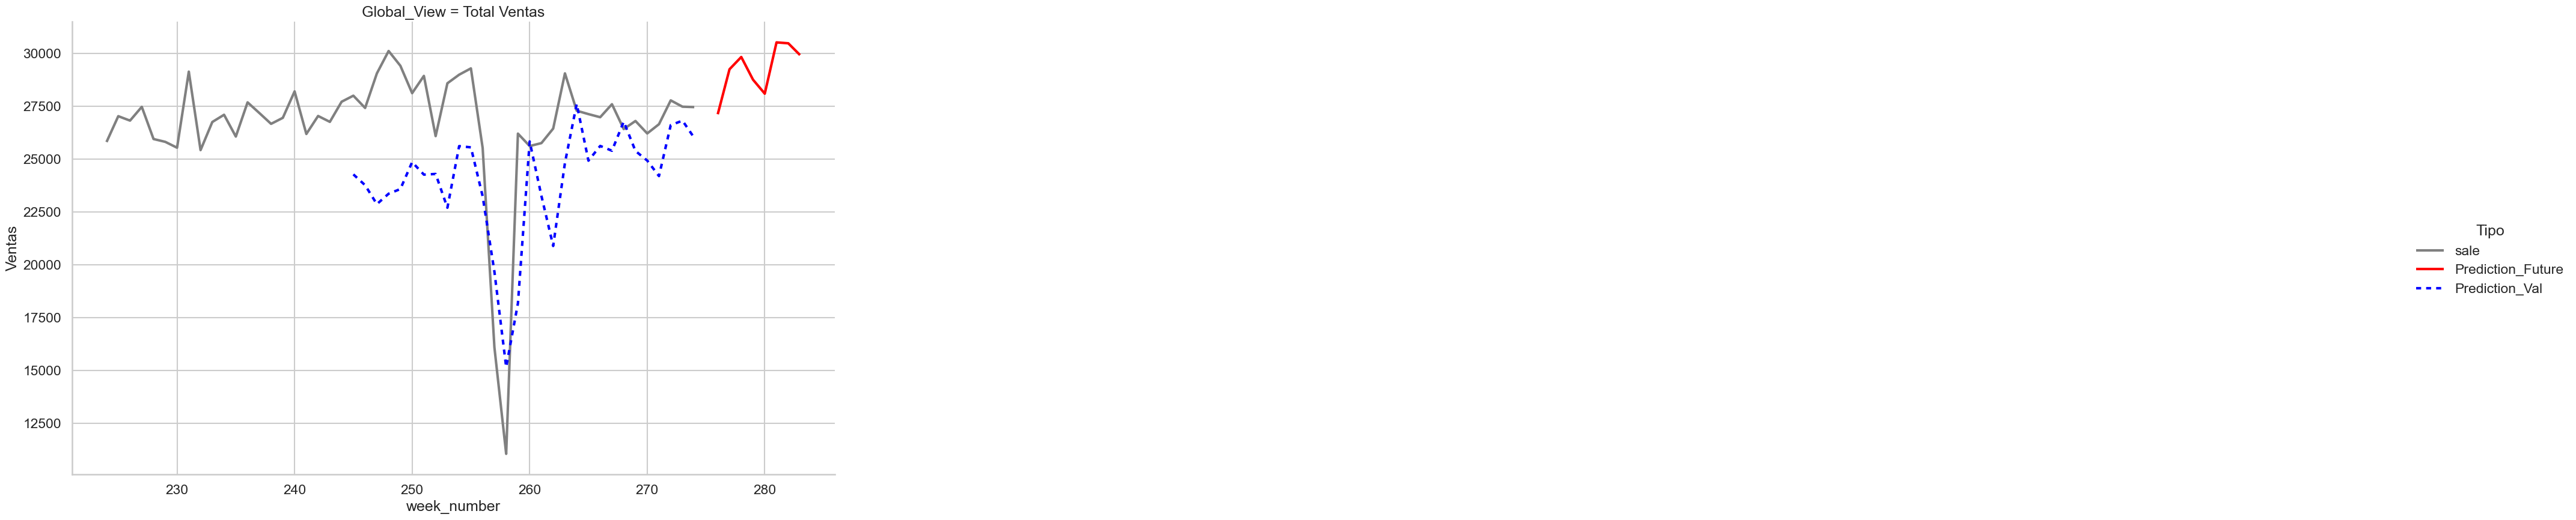

In [262]:
plot_lasso_forecast(df_viz_lasso_wo_last_week[df_viz_lasso_wo_last_week.category == 'ACCESORIES'], 'Global_View')


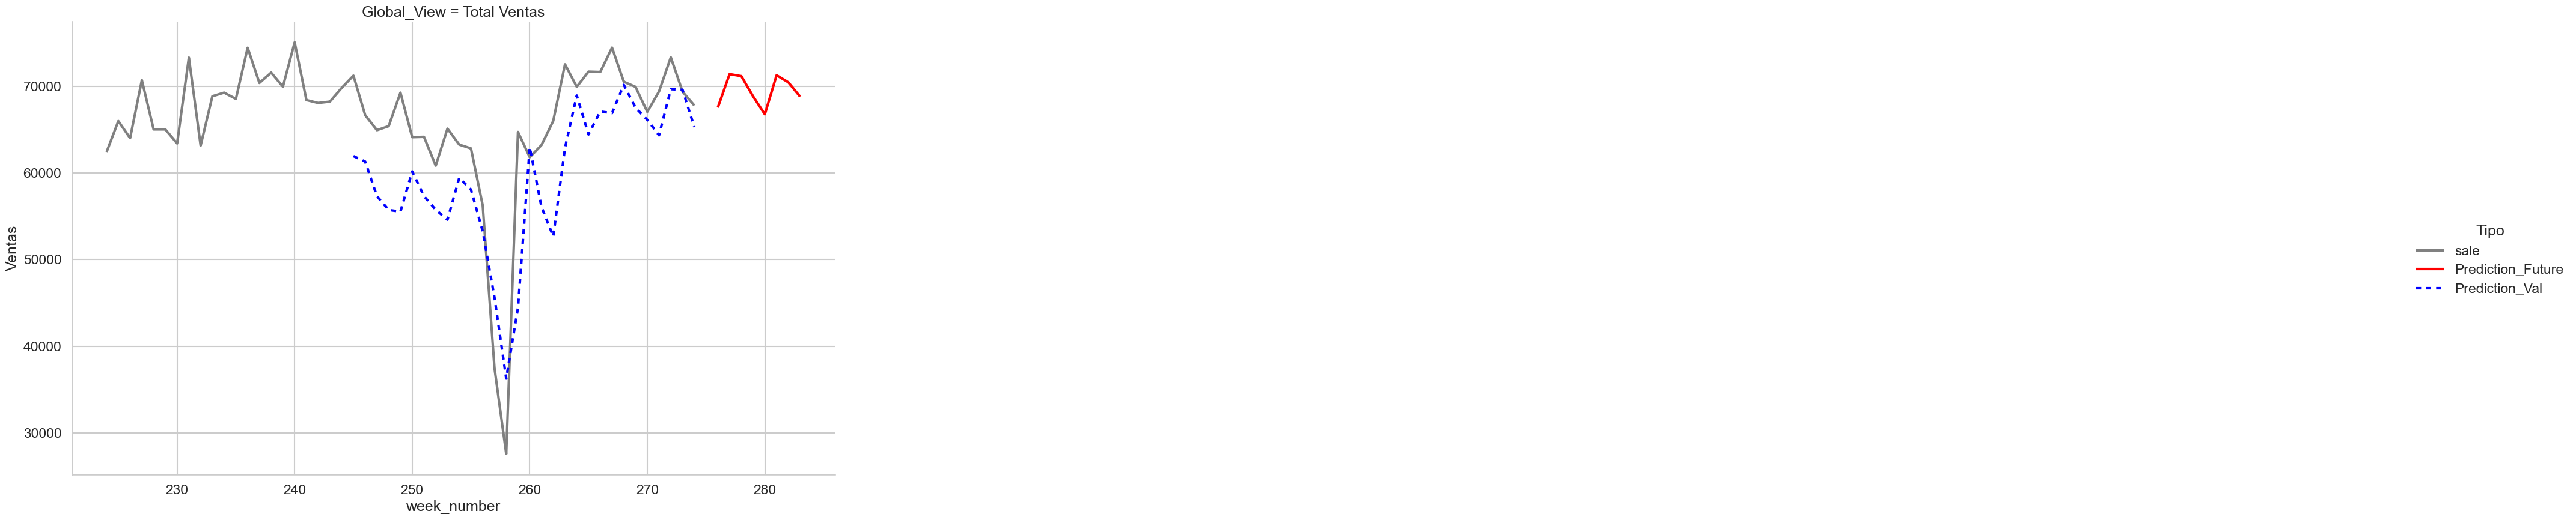

In [263]:
plot_lasso_forecast(df_viz_lasso_wo_last_week[df_viz_lasso_wo_last_week.category == 'HOME_&_GARDEN'], 'Global_View')


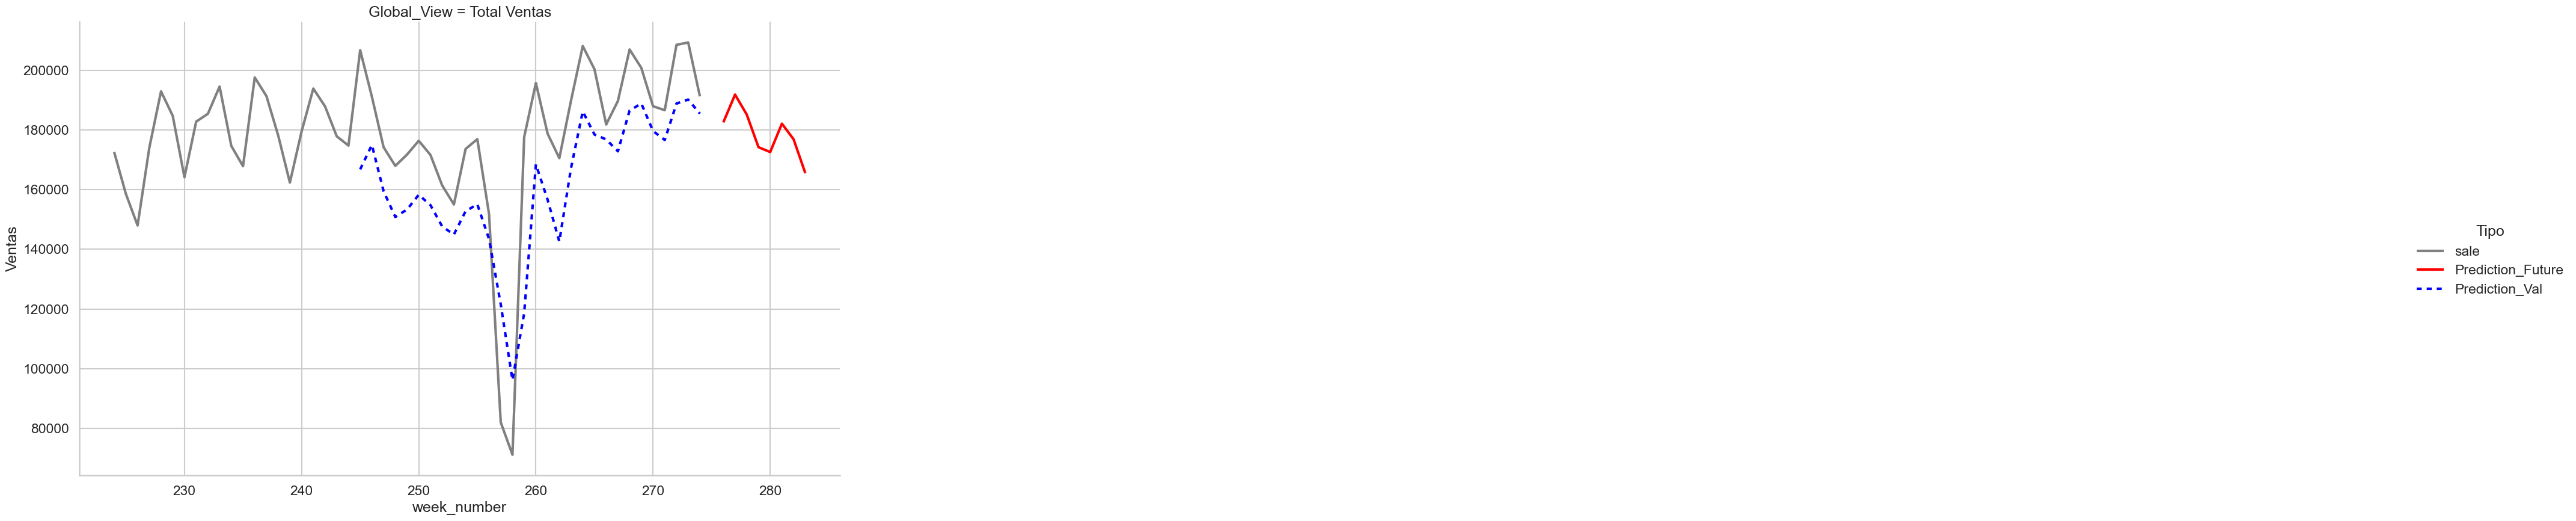

In [264]:
plot_lasso_forecast(df_viz_lasso_wo_last_week[df_viz_lasso_wo_last_week.category == 'SUPERMARKET'], 'Global_View')


In [121]:
df_viz_lasso.head()

,item,category,store_code,yearweek,sell_price,department,region,sale,Year,Quarter,...,july4_heat,is_shopping_event,is_holiday_closed,cluster,release_week,week_number,unique_id,Prediction_Future,Prediction_Val,Global_View
0,ACCESORIES_1_001,ACCESORIES,BOS_1,201332.0,10.9858,ACCESORIES_1,Boston,0.0,2013,3,...,0.0,0,0,5,131,131,ACCESORIES_1_001_BOS_1,NaN,NaN,Total Ventas
1,ACCESORIES_1_001,ACCESORIES,NYC_1,201332.0,10.9858,ACCESORIES_1,New York,6.0,2013,3,...,0.0,0,0,5,131,131,ACCESORIES_1_001_NYC_1,NaN,NaN,Total Ventas
2,ACCESORIES_1_001,ACCESORIES,NYC_4,201332.0,10.9858,ACCESORIES_1,New York,1.0,2013,3,...,0.0,0,0,5,131,131,ACCESORIES_1_001_NYC_4,NaN,NaN,Total Ventas
3,ACCESORIES_1_001,ACCESORIES,NYC_1,201333.0,10.9858,ACCESORIES_1,New York,1.0,2013,3,...,0.0,0,0,5,131,132,ACCESORIES_1_001_NYC_1,NaN,NaN,Total Ventas
4,ACCESORIES_1_001,ACCESORIES,NYC_3,201333.0,10.9858,ACCESORIES_1,New York,5.0,2013,3,...,0.0,0,0,5,131,132,ACCESORIES_1_001_NYC_3,NaN,NaN,Total Ventas


## 9. Results

The Lasso linear regression is the most reliable and the cheapest model to run. With the current features, the XGBoost models tend to pick up trends that make recursive forecasts explode or collapse within a few weeks, while the Lasso forecasts stay stable.

#### Forecast visualisations

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score

# Plot style
sns.set_context("talk")
sns.set_style("whitegrid")

def plot_business_visualizations(df_viz, model_pipeline, feature_names=None,
                                 pred_col='Prediction_Val', eval_label='Validation'):
    """
    Evaluation charts of the model for a business audience.
    pred_col: prediction column compared against 'sale'.
    eval_label: shown in the titles, so it is explicit whether the evaluation is in-sample or out-of-sample.
    """
    # Rows with both actuals and predictions
    df_eval = df_viz.dropna(subset=['sale', pred_col]).copy()

    if df_eval.empty:
        print("Error: no rows with both actuals and predictions to evaluate.")
        return

    df_eval['Error'] = df_eval[pred_col] - df_eval['sale']

    fig = plt.figure(figsize=(20, 15))
    gs = fig.add_gridspec(3, 2)
    fig.suptitle(eval_label, fontsize=22)

    # 1. SCATTER PLOT
    ax1 = fig.add_subplot(gs[0, 0])
    if len(df_eval) > 5000:
        plot_data = df_eval.sample(5000, random_state=42)
    else:
        plot_data = df_eval
    sns.scatterplot(x='sale', y=pred_col, data=plot_data, alpha=0.3, ax=ax1, color='royalblue')
    max_val = max(plot_data['sale'].max(), plot_data[pred_col].max())
    ax1.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Perfect prediction')
    r2 = r2_score(df_eval['sale'], df_eval[pred_col])
    ax1.set_title(f'Actual vs predicted (R² = {r2:.2f})')

    # 2. HISTOGRAM
    ax2 = fig.add_subplot(gs[0, 1])
    sns.histplot(df_eval['Error'], bins=50, kde=True, color='teal', ax=ax2)
    ax2.axvline(0, color='red', linestyle='--')
    ax2.set_title('Error distribution (residuals)')

    # 3. WEEKLY TOTAL
    ax3 = fig.add_subplot(gs[1, :])
    weekly_sum = df_eval.groupby('week_number')[['sale', pred_col]].sum().reset_index()
    sns.lineplot(data=weekly_sum, x='week_number', y='sale', label='Actual sales', color='grey', lw=3, ax=ax3)
    sns.lineplot(data=weekly_sum, x='week_number', y=pred_col, label='Model', color='blue', linestyle='--', lw=3, ax=ax3)
    ax3.fill_between(weekly_sum['week_number'], weekly_sum['sale'], weekly_sum[pred_col], alpha=0.1, color='blue')
    ax3.set_title('Total weekly volume')

    # 4. TOP FEATURES
    ax4 = fig.add_subplot(gs[2, 0])
    try:
        pipeline_inner = model_pipeline.regressor_
        lasso_model = pipeline_inner.named_steps['model']
        preprocessor = pipeline_inner.named_steps['preprocessor']
        try:
            feat_names = preprocessor.get_feature_names_out()
        except:
            feat_names = [f'Feat_{i}' for i in range(len(lasso_model.coef_))]
        coefs = pd.DataFrame({'Feature': feat_names, 'Coef': lasso_model.coef_, 'Abs_Coef': np.abs(lasso_model.coef_)})
        top_coefs = coefs.sort_values('Abs_Coef', ascending=False).head(10)
        sns.barplot(data=top_coefs, x='Coef', y='Feature', hue='Feature', palette='viridis', legend=False, ax=ax4)
        ax4.set_title('Top 10 Lasso coefficients')
    except Exception as e:
        ax4.text(0.5, 0.5, "No coefs available", ha='center')

    # 5. ERROR BY CATEGORY
    ax5 = fig.add_subplot(gs[2, 1])
    cat_col = 'cluster' if 'cluster' in df_eval.columns else 'store_code'
    if cat_col in df_eval.columns:
        # |error| / (sale + 1): MAPE variant that stays finite on zero-sales weeks
        df_eval['Abs_Pct_Error'] = np.abs(df_eval['Error'] / (df_eval['sale'] + 1))
        err_by_cat = df_eval.groupby(cat_col)['Abs_Pct_Error'].mean().sort_values() * 100
        top_bot = pd.concat([err_by_cat.head(5), err_by_cat.tail(5)])
        top_bot = top_bot[~top_bot.index.duplicated()]  # fewer than 10 categories: no repeated bars
        df_err = pd.DataFrame({cat_col: top_bot.index.astype(str), 'MAPE_%': top_bot.values})
        # Category on the X axis, error on the Y axis
        sns.barplot(data=df_err, x=cat_col, y='MAPE_%', hue=cat_col, palette='RdYlGn_r', legend=False, ax=ax5)
        ax5.set_xlabel(cat_col)
        ax5.set_ylabel('MAPE (%) = mean |error| / (sale + 1)')
        ax5.set_title(f'Mean absolute % error by {cat_col}')

    plt.tight_layout()
    plt.show()

    rmse = np.sqrt(np.mean(df_eval['Error'] ** 2))
    wmape_eval = df_eval['Error'].abs().sum() / df_eval['sale'].sum()
    print(f"{eval_label} | rows: {len(df_eval):,} | R²: {r2:.3f} | RMSE: {rmse:.3f} | WMAPE: {wmape_eval:.2%}")


In [195]:
def _prep_revenue_data(df_viz, price_col='sell_price', window_weeks=4):
    """
    Compare the first N forecast weeks with the previous N weeks.
    Computes both units ('Units_Calc') and revenue ('Revenue_Calc').
    """
    df = df_viz.copy()
    
    # 1. Price (only needed for revenue)
    # Neutral dummy price if missing (does not affect 'units')
    if price_col not in df.columns:
        df[price_col] = 1.0 # Neutral dummy
    
    df[price_col] = df.groupby('unique_id')[price_col].ffill().fillna(1.0)
    
    # 2. Unified metric (past actuals + future forecast)
    # UNITS (sale vs prediction)
    df['Units_Calc'] = np.where(
        df['Prediction_Future'].notna(),
        df['Prediction_Future'], # Future
        df['sale']               # Past (actuals)
    )
    
    # REVENUE (Units * Price)
    df['Revenue_Calc'] = df['Units_Calc'] * df[price_col]
    
    # 3. Time windows (momentum)
    if 'Prediction_Future' not in df.columns or df['Prediction_Future'].notna().sum() == 0:
        print("Error: there are no future predictions in the DataFrame.")
        return None

    first_pred_week = df[df['Prediction_Future'].notna()]['week_number'].min()
    
    # Future range (next N weeks)
    future_range = range(first_pred_week, first_pred_week + window_weeks)
    
    # Past range (previous N weeks)
    past_range = range(first_pred_week - window_weeks, first_pred_week)
    
    # print(f"Comparing: past (wk {min(past_range)}-{max(past_range)}) vs future (wk {min(future_range)}-{max(future_range)})")
    
    # 4. Labels
    df.loc[df['week_number'].isin(past_range), 'Period'] = 'Last 4 Weeks'
    df.loc[df['week_number'].isin(future_range), 'Period'] = 'Next 4 Weeks (Forecast)'
    
    # Keep only the relevant rows
    df_comp = df[df['Period'].notna()].copy()
    
    # 5. Derive region and department if missing
    if 'Region' not in df_comp.columns:
        if 'store_code' in df_comp.columns:
            df_comp['Region'] = df_comp['store_code'].apply(lambda x: str(x).split('_')[0] if '_' in str(x) else str(x)[:3])
        else:
            df_comp['Region'] = 'Global'
            
    return df_comp


In [ ]:
def plot_revenue_momentum(df_viz, groupby_col='Region', price_col='sell_price', window_weeks=4, metric_mode='revenue'):
    """
    Bar chart: previous weeks vs forecast weeks.
    Args:
        metric_mode: 'revenue' or 'units' (sales volume).
        groupby_col: column to group by (e.g. 'Region', 'department', 'store_code').
    """
    df_comp = _prep_revenue_data(df_viz, price_col, window_weeks)
    if df_comp is None: return

    # Metric
    if metric_mode == 'units':
        target_col = 'Units_Calc'
        ylabel_text = 'Total units (volume)'
        title_text = f'Volume momentum: units sold ({window_weeks} weeks)'
    else:
        target_col = 'Revenue_Calc'
        ylabel_text = 'Estimated total revenue ($)'
        title_text = f'Revenue momentum ({window_weeks} weeks)'

    # Group
    if groupby_col not in df_comp.columns:
        print(f"Column '{groupby_col}' not found. Using 'Region'.")
        groupby_col = 'Region'

    agg_data = df_comp.groupby([groupby_col, 'Period'])[target_col].sum().reset_index()
    
    plt.figure(figsize=(14, 7))
    
    # Barplot
    sns.barplot(
        data=agg_data, 
        x=groupby_col, 
        y=target_col, 
        hue='Period',
        hue_order=['Last 4 Weeks', 'Next 4 Weeks (Forecast)'],
        palette={'Last 4 Weeks': 'grey', 'Next 4 Weeks (Forecast)': 'darkblue'}
    )
    
    plt.title(title_text, fontsize=16)
    plt.ylabel(ylabel_text)
    plt.xlabel(groupby_col.capitalize())
    plt.grid(axis='y', alpha=0.3)
    
    # Rotate labels so department names fit
    plt.xticks(rotation=45, ha='right')
    
    # Legend outside the plot
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    
    plt.tight_layout()
    plt.show()
    
    # --- GROWTH SUMMARY ---
    # Pivot to compare periods
    pivot = agg_data.pivot(index=groupby_col, columns='Period', values=target_col)
    
    future_col = 'Next 4 Weeks (Forecast)'
    past_col = 'Last 4 Weeks'
    
    if future_col in pivot.columns and past_col in pivot.columns:
        # Growth %
        # Epsilon avoids division by zero
        pivot['Growth_Pct'] = ((pivot[future_col] / (pivot[past_col] + 1e-6)) - 1) * 100
        
        # Format output
        print(f"\n--- Momentum summary ({metric_mode}) by {groupby_col} ---")
        # Highest growth first
        pivot_sorted = pivot.sort_values('Growth_Pct', ascending=False)
        
        # Iterate and print
        for idx, row in pivot_sorted.iterrows():
            growth = row['Growth_Pct']
            arrow = "↗️" if growth > 0 else "↘️"
            print(f"{idx}: {arrow} {growth:+.2f}%  (Past: {row[past_col]:,.0f} | Future: {row[future_col]:,.0f})")
    else:
        print("Could not compute the change (missing period data).")

In [177]:
def plot_simple_growth_heatmap(df_viz, groupby_cols, window_weeks=4):
    """
    Generates a heatmap comparing sales volume (units) between the immediate past 
    and the immediate future forecast.
    
    Args:
        df_viz: DataFrame containing 'week_number', 'sale' (history), and 'Prediction_Future'.
        groupby_cols: List of 2 columns to group by (e.g., ['cluster', 'department']).
        window_weeks: Number of weeks to compare (e.g., 4 weeks vs 4 weeks).
    """
    
    # 1. Validation
    if len(groupby_cols) != 2:
        print("Error: Please provide exactly 2 columns in 'groupby_cols' for the heatmap.")
        return
        
    if 'Prediction_Future' not in df_viz.columns:
        print("Error: 'Prediction_Future' column missing in DataFrame.")
        return

    # 2. Define Time Windows (Strictly equal periods)
    # Find the start of the prediction
    future_data = df_viz[df_viz['Prediction_Future'].notna()]
    if future_data.empty:
        print("Error: No future predictions found.")
        return
        
    first_pred_week = future_data['week_number'].min()
    
    # Define ranges (Python range is exclusive at the end)
    future_weeks = range(first_pred_week, first_pred_week + window_weeks)
    past_weeks = range(first_pred_week - window_weeks, first_pred_week)
    
    print(f"--- Analysis Periods ---")
    print(f"Past (Real): Weeks {min(past_weeks)} to {max(past_weeks)}")
    print(f"Future (Pred): Weeks {min(future_weeks)} to {max(future_weeks)}")
    
    # 3. Filter Data
    # Past: We use 'sale' (Real data)
    df_past = df_viz[df_viz['week_number'].isin(past_weeks)].copy()
    past_sales = df_past.groupby(groupby_cols)['sale'].sum().rename('Past_Sales')
    
    # Future: We use 'Prediction_Future'
    df_future = df_viz[df_viz['week_number'].isin(future_weeks)].copy()
    future_sales = df_future.groupby(groupby_cols)['Prediction_Future'].sum().rename('Future_Sales')
    
    # 4. Merge and Calculate Growth
    # Combine both series into a DataFrame
    df_comp = pd.concat([past_sales, future_sales], axis=1).fillna(0)
    
    # Growth Formula: ((Future - Past) / Past) * 100
    # Add small epsilon to avoid division by zero
    df_comp['Growth_Pct'] = ((df_comp['Future_Sales'] / (df_comp['Past_Sales'] + 1e-6)) - 1) * 100
    
    # 5. Visualization (Heatmap)
    plt.figure(figsize=(12, 8))
    
    # Unstack to create matrix: Index -> Y axis, Column -> X axis
    # groupby_cols[0] will be Y axis, groupby_cols[1] will be X axis
    heatmap_data = df_comp['Growth_Pct'].unstack(level=groupby_cols[1])
    
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn", # Red to Green colormap
        center=0,      # White/Yellow at 0%
        cbar_kws={'label': 'Sales change % (units)'}
    )
    
    plt.title(f'Sales change: next {window_weeks} weeks vs previous {window_weeks}', fontsize=14)
    plt.ylabel(groupby_cols[0].capitalize())
    plt.xlabel(groupby_cols[1].capitalize())
    plt.tight_layout()
    plt.show()


In [ ]:
def plot_top_movers(df_viz, price_col='sell_price', window_weeks=4, metric_mode='revenue', dept_col = 'department'):
    """
    Top movers: absolute change ($ or units).
    """
    df_comp = _prep_revenue_data(df_viz, price_col, window_weeks)
    if df_comp is None: return
    
    target_col = 'Revenue_Calc' if metric_mode == 'revenue' else 'Units_Calc'
    unit_label = '$' if metric_mode == 'revenue' else 'units'
        
    # Group
    grp = df_comp.groupby([dept_col, 'Period'])[target_col].sum().unstack(level='Period')
    
    future_col = 'Next 4 Weeks (Forecast)'
    past_col = 'Last 4 Weeks'
    
    grp['Delta_Abs'] = grp[future_col] - grp[past_col]
    grp = grp.reset_index()
        
    top_movers = grp.sort_values('Delta_Abs', ascending=False)
    plot_data = pd.concat([top_movers.head(5), top_movers.tail(5)])
    
    plt.figure(figsize=(12, 8))
    colors = ['green' if x > 0 else 'red' for x in plot_data['Delta_Abs']]
    
    sns.barplot(data=plot_data, x='Delta_Abs', y=dept_col, hue=dept_col, palette='RdYlGn_r', legend=False)
    plt.axvline(0, color='black', linewidth=1)
    
    plt.title(f'Top movers: net change in {metric_mode.capitalize()} ({unit_label})')
    plt.xlabel(f'Change ({unit_label})')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()


In [288]:
def plot_top_movers_pct(df_viz, price_col='sell_price', window_weeks=4, metric_mode='units', dept_col='department'):
    """
    Top movers: growth % ($ or units).
    Also prints the number of items per category shown.
    """
    # 1. Data (time windows)
    df_comp = _prep_revenue_data(df_viz, price_col, window_weeks)
    if df_comp is None: return
    
    # 2. Target metric
    target_col = 'Revenue_Calc' if metric_mode == 'revenue' else 'Units_Calc'
    metric_label = 'Revenue ($)' if metric_mode == 'revenue' else 'Units'

    # --- Number of unique items per group ---
    # 'unique_id' identifies an item-store series
    item_counts = df_comp.groupby(dept_col)['unique_id'].nunique().rename('Item_Count')
        
    # 3. Group and pivot sales
    grp = df_comp.groupby([dept_col, 'Period'])[target_col].sum().unstack(level='Period')
    
    future_col = 'Next 4 Weeks (Forecast)'
    past_col = 'Last 4 Weeks'
    
    # 4. Both periods are needed to compute the growth
    if future_col not in grp.columns or past_col not in grp.columns:
        print("Error: missing past or future period data.")
        return

    # --- Growth % ---
    # Formula: ((Future / Past) - 1) * 100
    # +1 in the denominator avoids division by zero when past sales were 0.
    grp['Growth_Pct'] = ((grp[future_col] / (grp[past_col] + 1)) - 1) * 100
    grp['Growth_total'] = (grp[future_col] - (grp[past_col]))
    
    # --- Join the item counts ---
    grp = grp.merge(item_counts, left_index=True, right_index=True)
    
    # Reset index so dept_col can be used in the plot
    grp = grp.reset_index()
        
    # 5. Top and bottom movers by growth %
    top_movers = grp.sort_values('Growth_Pct', ascending=False)
    # 5 best and 5 worst
    plot_data = pd.concat([top_movers.head(5), top_movers.tail(5)])
    
    # 6. Plot
    plt.figure(figsize=(12, 8))
    

    sns.barplot(data=plot_data, x='Growth_Pct', y=dept_col, hue=dept_col, palette='RdYlGn_r', legend=False)
    plt.axvline(0, color='black', linewidth=1)
    
    plt.title(f'Top movers: growth % in {metric_mode.capitalize()}')
    plt.xlabel('Growth (%)')
    plt.ylabel(dept_col.capitalize())
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # --- Print item counts ---
    print(f"\n--- Items and growth by {dept_col} ---")
    print(f"Metric: {metric_label}\n")
    # Iterate over the plotted rows
    for index, row in plot_data.iterrows():
        growth = row['Growth_Pct']
        total_growth = row['Growth_total']
        count = int(row['Item_Count'])
        category = row[dept_col]
        
        # Console formatting
        arrow = "↗️ " if growth > 0 else "↘️ "
        print(f"- {category:<20} | Items: {count:>4} | Growth: {arrow}{growth:>6.2f}%")
        print(f"Total Dif. Sales: {arrow}{total_growth:>6.0f}")

In [ ]:
# Out-of-sample evaluation: pipeline trained on weeks < 255, evaluated on weeks 255-274
informe_negocio = plot_business_visualizations(
    df_viz_lasso, model_lasso_oos, feature_names='region',
    pred_col='Prediction_Val_OOS',
    eval_label='Out-of-sample: weeks 255-274 (trained on weeks < 255)'
)

Comparando: Pasado (Wk 271-274) vs Futuro (Wk 275-278)


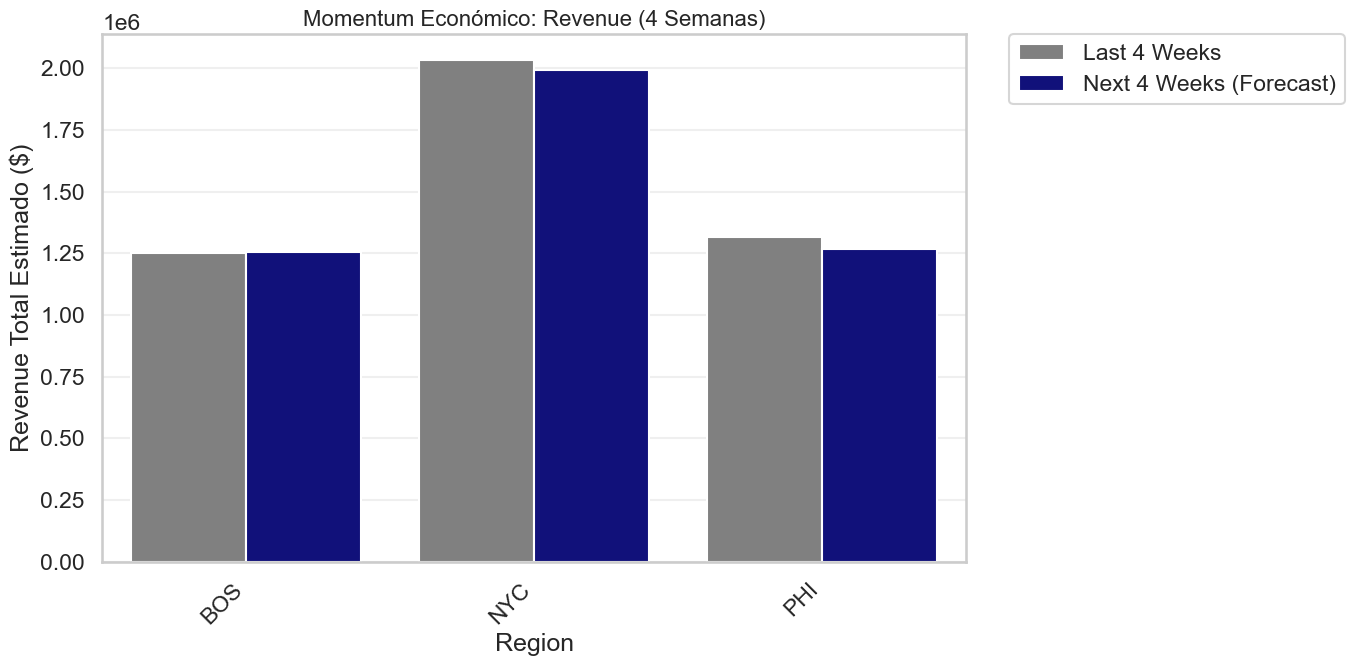


--- Resumen de Momentum (revenue) por Region ---
BOS: ↗️ +0.20%  (Pasado: 1,252,157 | Futuro: 1,254,672)
NYC: ↘️ -2.04%  (Pasado: 2,034,782 | Futuro: 1,993,188)
PHI: ↘️ -3.80%  (Pasado: 1,315,479 | Futuro: 1,265,557)


In [156]:
plot_revenue_momentum(df_viz=df_viz_lasso, groupby_col= 'Region')

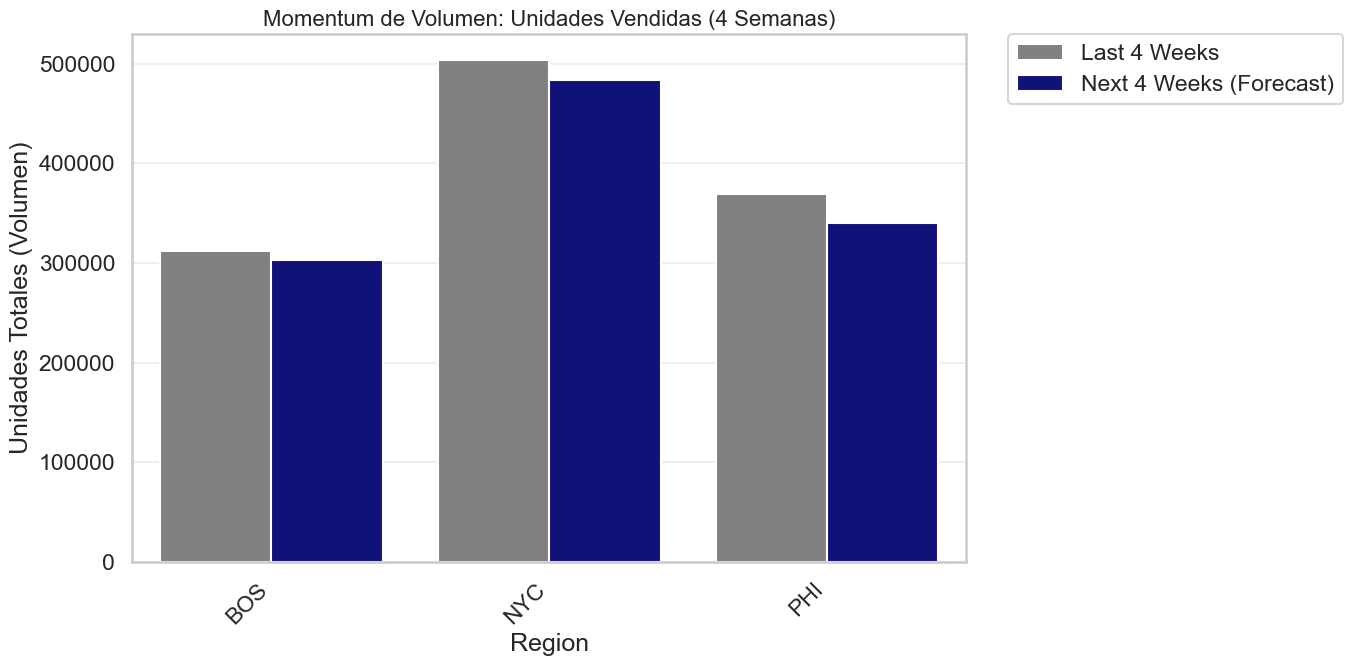


--- Resumen de Momentum (units) por Region ---
BOS: ↘️ -2.65%  (Pasado: 311,687 | Futuro: 303,434)
NYC: ↘️ -4.08%  (Pasado: 504,233 | Futuro: 483,682)
PHI: ↘️ -7.87%  (Pasado: 369,172 | Futuro: 340,108)


In [266]:
plot_revenue_momentum(df_viz=df_viz_lasso, groupby_col= 'Region', metric_mode='units')

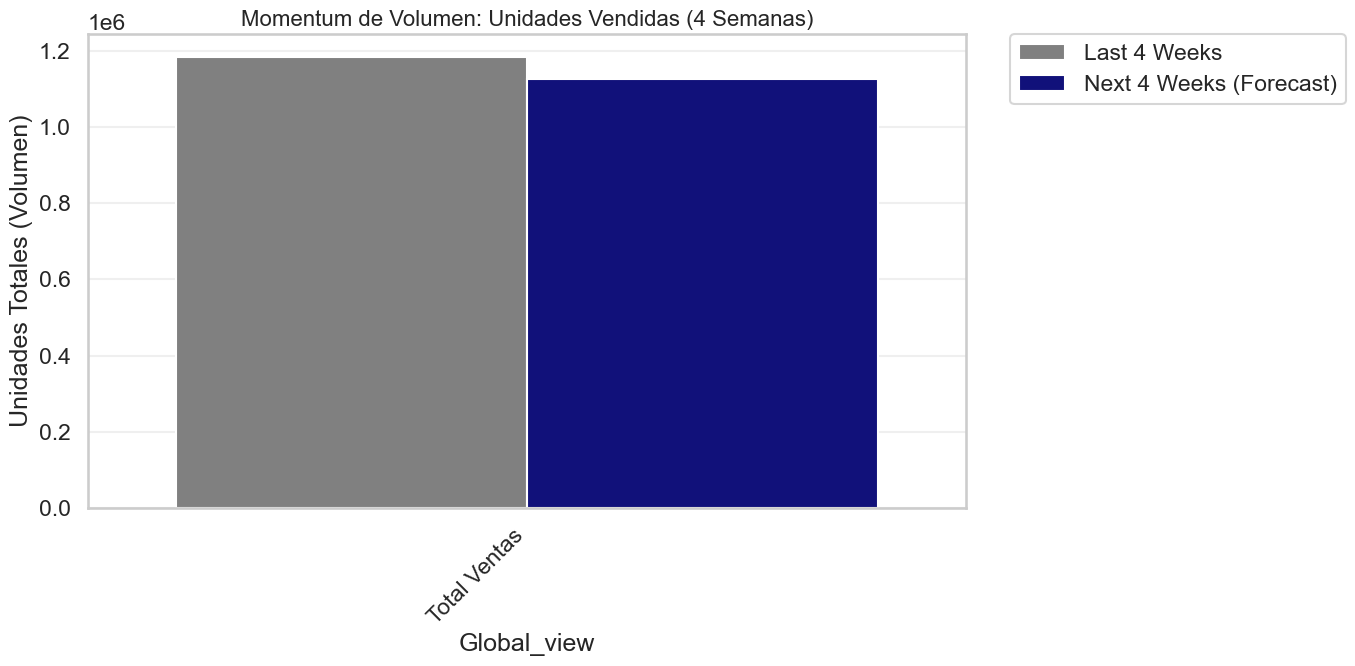


--- Resumen de Momentum (units) por Global_View ---
Total Ventas: ↘️ -4.88%  (Pasado: 1,185,092 | Futuro: 1,127,225)


In [270]:
plot_revenue_momentum(df_viz=df_viz_lasso, groupby_col= 'Global_View', metric_mode='units')

Comparando: Pasado (Wk 271-274) vs Futuro (Wk 275-278)


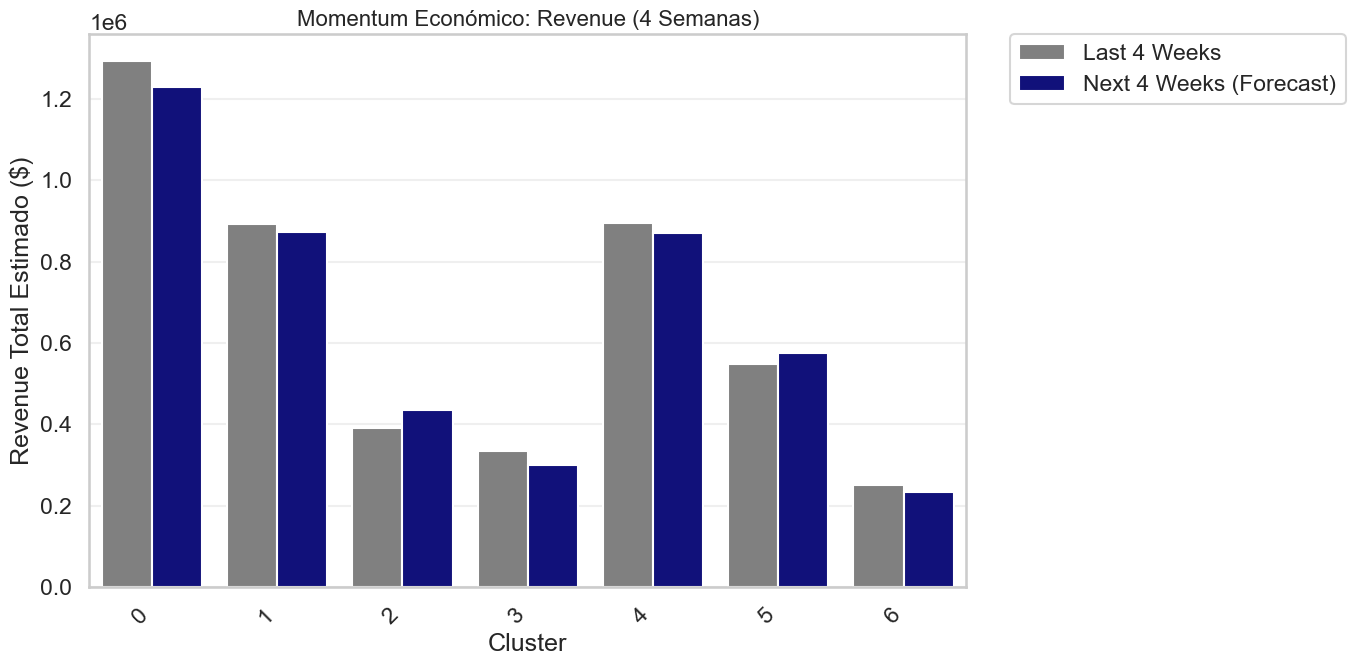


--- Resumen de Momentum (revenue) por cluster ---
2: ↗️ +11.21%  (Pasado: 390,280 | Futuro: 434,017)
5: ↗️ +4.86%  (Pasado: 547,875 | Futuro: 574,492)
1: ↘️ -2.14%  (Pasado: 891,772 | Futuro: 872,702)
4: ↘️ -2.64%  (Pasado: 894,042 | Futuro: 870,437)
0: ↘️ -5.03%  (Pasado: 1,293,932 | Futuro: 1,228,841)
6: ↘️ -6.77%  (Pasado: 250,900 | Futuro: 233,913)
3: ↘️ -10.37%  (Pasado: 333,617 | Futuro: 299,016)


In [158]:
plot_revenue_momentum(df_viz=df_viz_lasso,groupby_col= 'cluster')

Comparando: Pasado (Wk 271-274) vs Futuro (Wk 275-278)


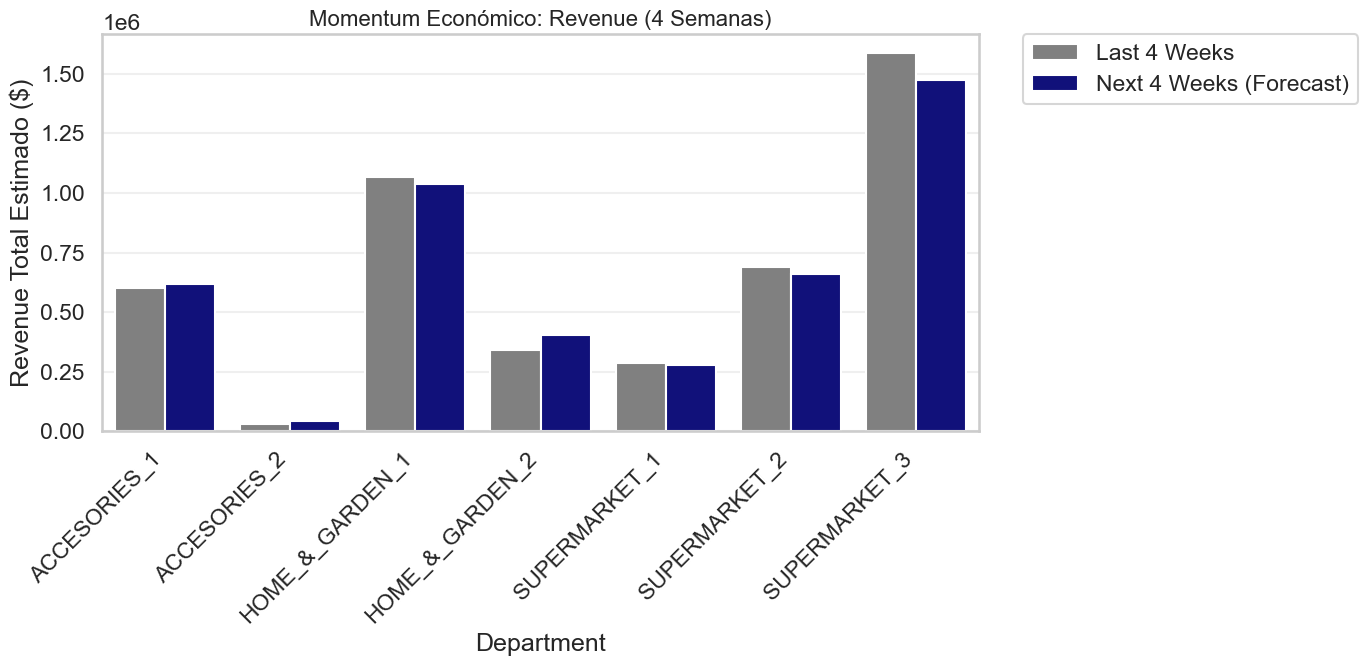


--- Resumen de Momentum (revenue) por department ---
ACCESORIES_2: ↗️ +44.86%  (Pasado: 29,632 | Futuro: 42,925)
HOME_&_GARDEN_2: ↗️ +17.70%  (Pasado: 342,820 | Futuro: 403,510)
ACCESORIES_1: ↗️ +2.67%  (Pasado: 601,676 | Futuro: 617,732)
SUPERMARKET_1: ↘️ -2.75%  (Pasado: 287,258 | Futuro: 279,364)
HOME_&_GARDEN_1: ↘️ -2.75%  (Pasado: 1,065,264 | Futuro: 1,035,921)
SUPERMARKET_2: ↘️ -4.58%  (Pasado: 690,265 | Futuro: 658,649)
SUPERMARKET_3: ↘️ -6.95%  (Pasado: 1,585,502 | Futuro: 1,475,315)


In [157]:
plot_revenue_momentum(df_viz=df_viz_lasso,groupby_col= 'department')

--- Analysis Periods ---
Past (Real): Weeks 271 to 274
Future (Pred): Weeks 275 to 278


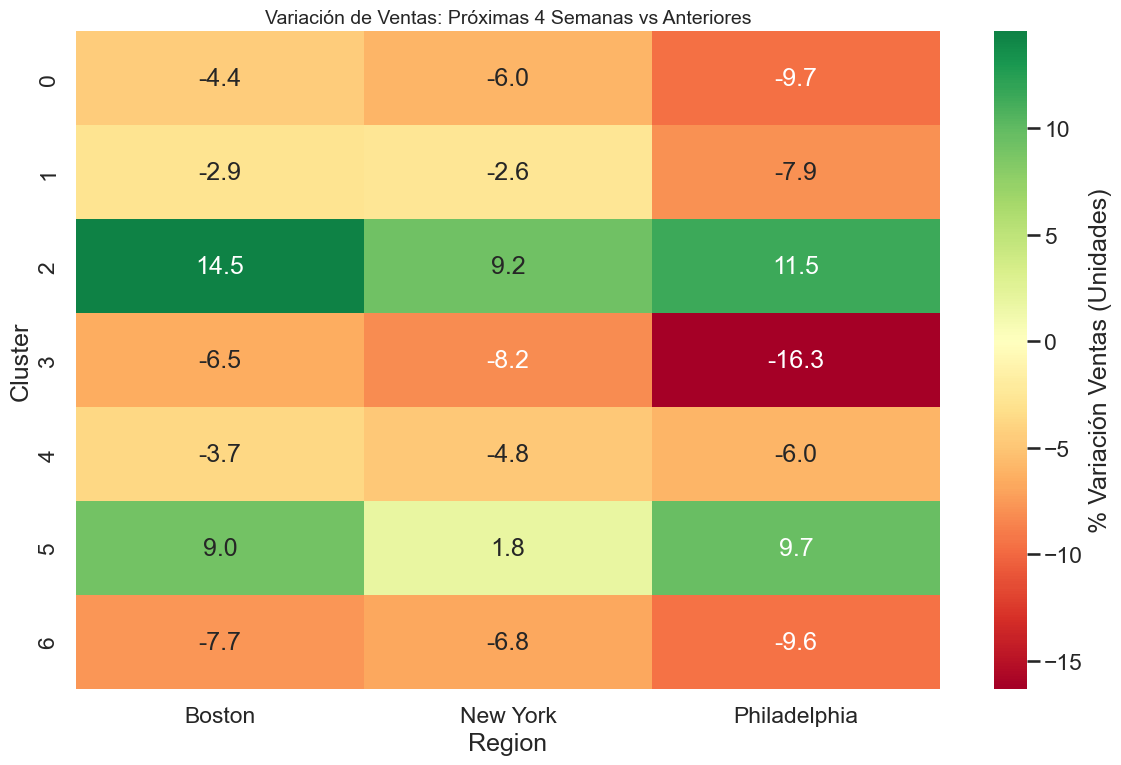

In [179]:
plot_simple_growth_heatmap(df_viz_lasso, groupby_cols=['cluster', 'region'])

Comparando: Pasado (Wk 271-274) vs Futuro (Wk 275-278)


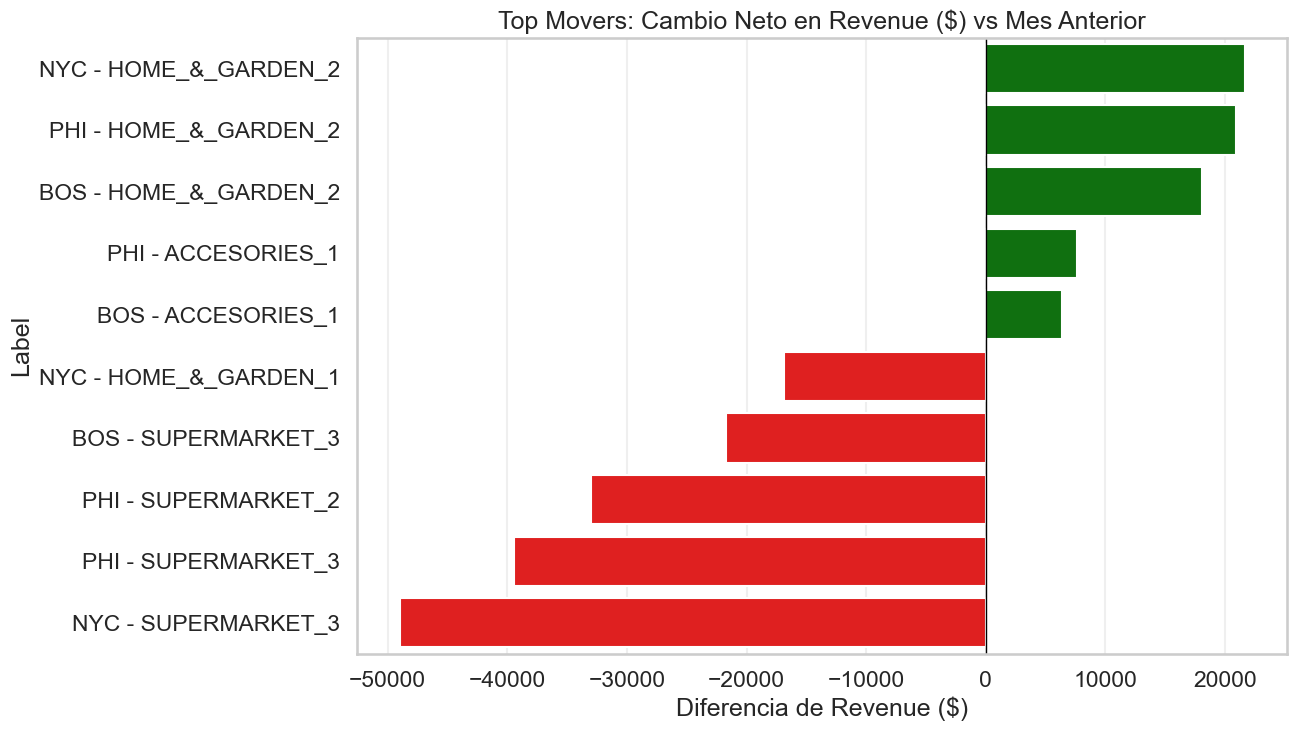

In [139]:
plot_top_movers(df_viz_lasso)

--- Analysis Periods ---
Past (Real): Weeks 271 to 274
Future (Pred): Weeks 275 to 278


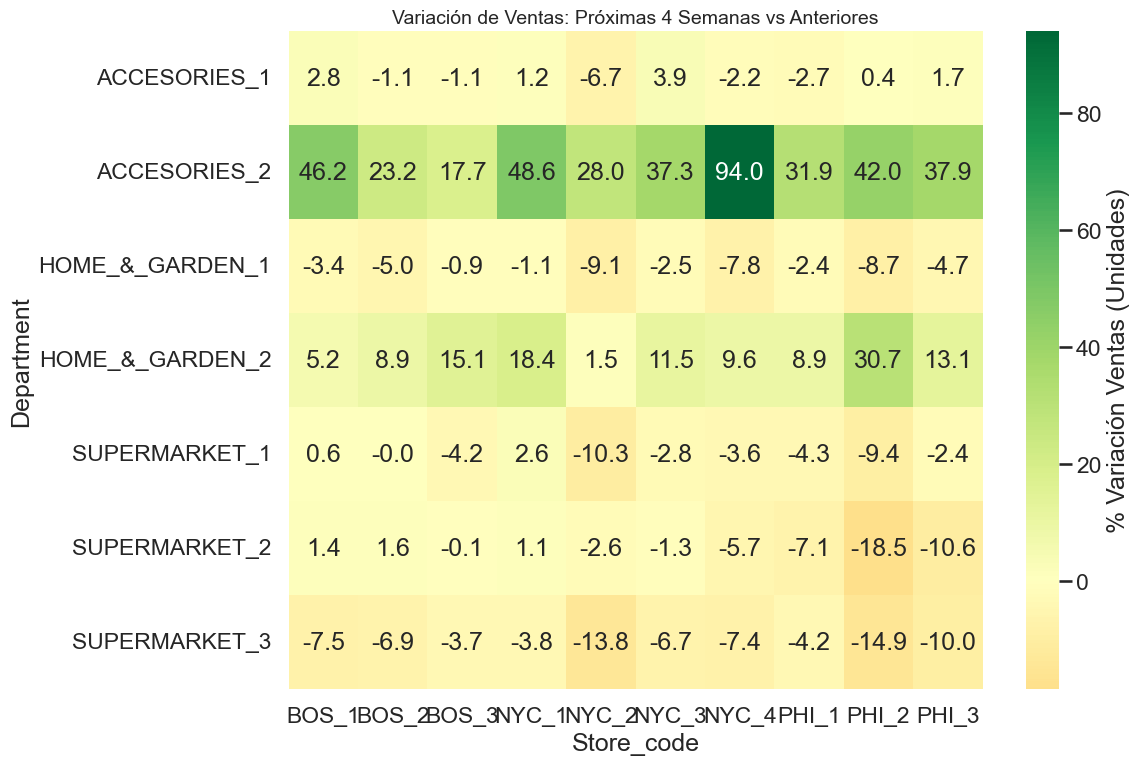

In [189]:
plot_simple_growth_heatmap(df_viz_lasso, groupby_cols=[ 'department','store_code'])

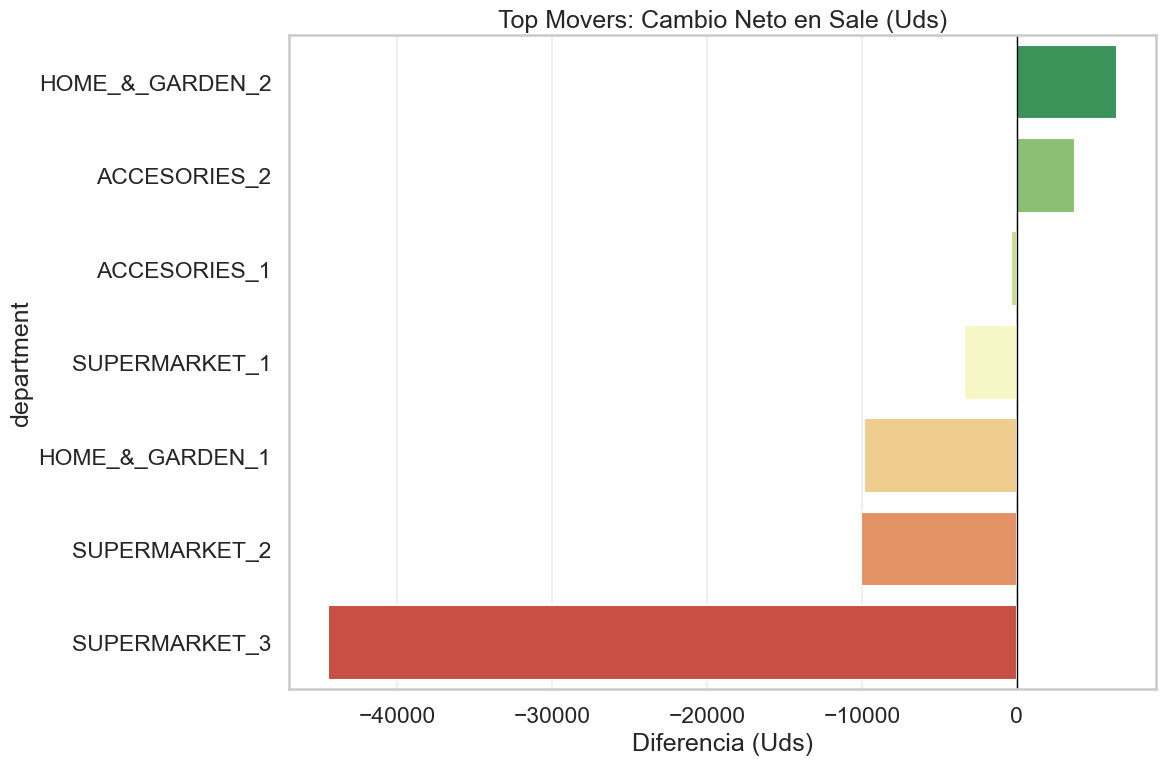

In [218]:
plot_top_movers(df_viz=df_viz_lasso, metric_mode='sale', dept_col='department')

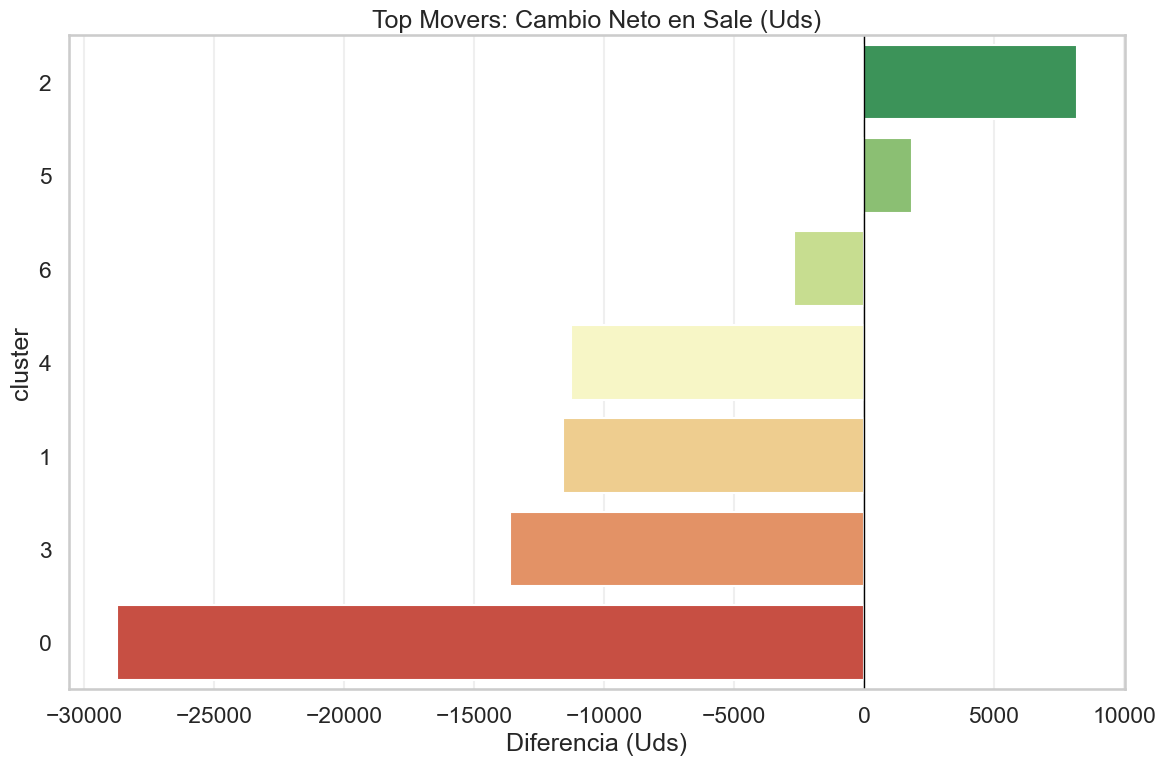

In [246]:
df_viz_lasso_2 = df_viz_lasso.copy()
df_viz_lasso_2['cluster'] = df_viz_lasso_2['cluster'].astype(str)
df_viz_lasso_2['cluster'].head()

plot_top_movers(df_viz=df_viz_lasso_2, metric_mode='sale', dept_col='cluster')

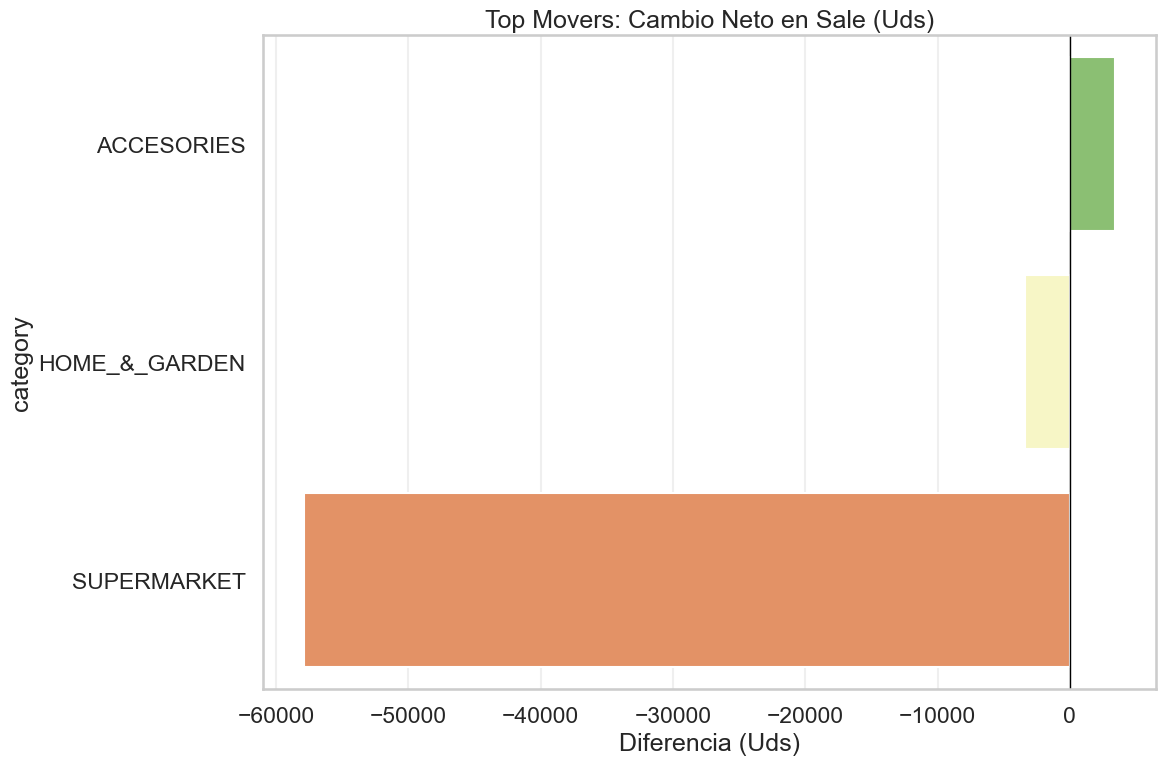

In [248]:
plot_top_movers(df_viz=df_viz_lasso_2, metric_mode='sale', dept_col='category')

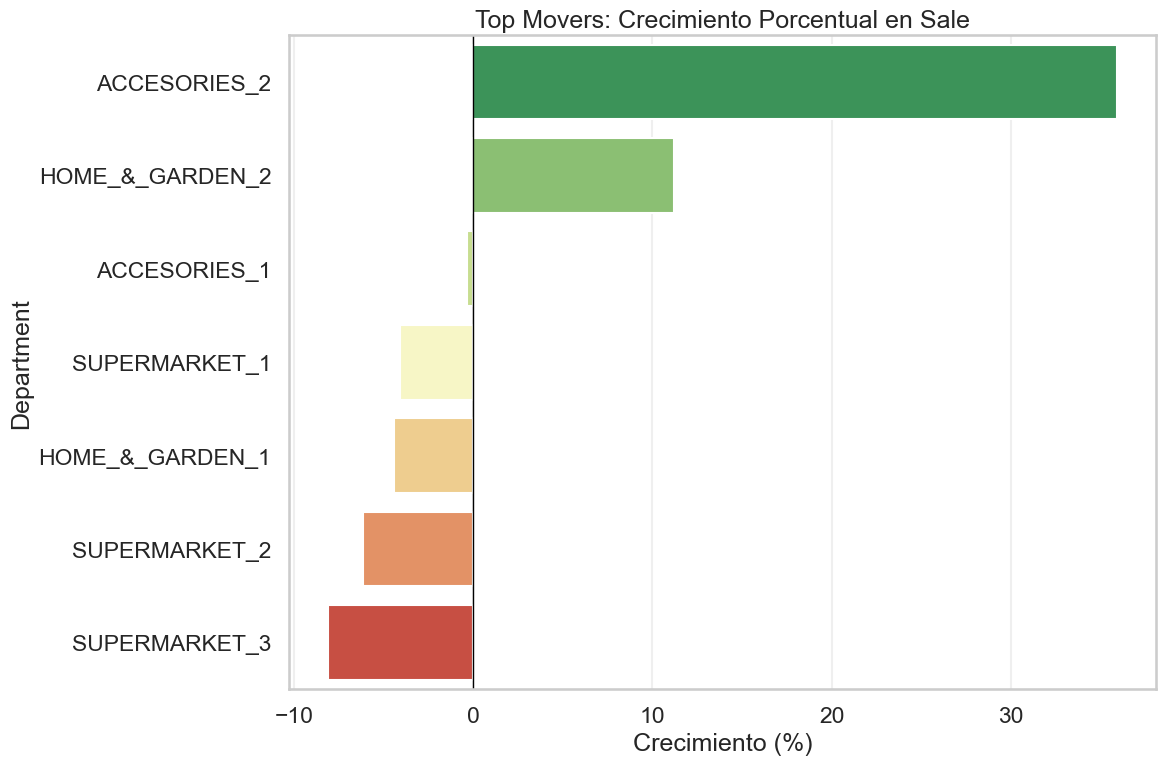


--- Resumen de Items y Crecimiento (department) ---
Métrica analizada: Unidades

- ACCESORIES_2         | Items: 1490 | Crecimiento: ↗️  35.89%
Total Dif. Sales: ↗️   3793
- HOME_&_GARDEN_2      | Items: 5150 | Crecimiento: ↗️  11.23%
Total Dif. Sales: ↗️   6446
- ACCESORIES_1         | Items: 4160 | Crecimiento: ↘️  -0.35%
Total Dif. Sales: ↘️   -347
- SUPERMARKET_1        | Items: 2160 | Crecimiento: ↘️  -4.07%
Total Dif. Sales: ↘️  -3421
- HOME_&_GARDEN_1      | Items: 5320 | Crecimiento: ↘️  -4.42%
Total Dif. Sales: ↘️  -9844
- ACCESORIES_1         | Items: 4160 | Crecimiento: ↘️  -0.35%
Total Dif. Sales: ↘️   -347
- SUPERMARKET_1        | Items: 2160 | Crecimiento: ↘️  -4.07%
Total Dif. Sales: ↘️  -3421
- HOME_&_GARDEN_1      | Items: 5320 | Crecimiento: ↘️  -4.42%
Total Dif. Sales: ↘️  -9844
- SUPERMARKET_2        | Items: 3980 | Crecimiento: ↘️  -6.17%
Total Dif. Sales: ↘️ -10040
- SUPERMARKET_3        | Items: 8230 | Crecimiento: ↘️  -8.10%
Total Dif. Sales: ↘️ -44455


In [289]:
plot_top_movers_pct(df_viz=df_viz_lasso_2, metric_mode='sale', dept_col='department')

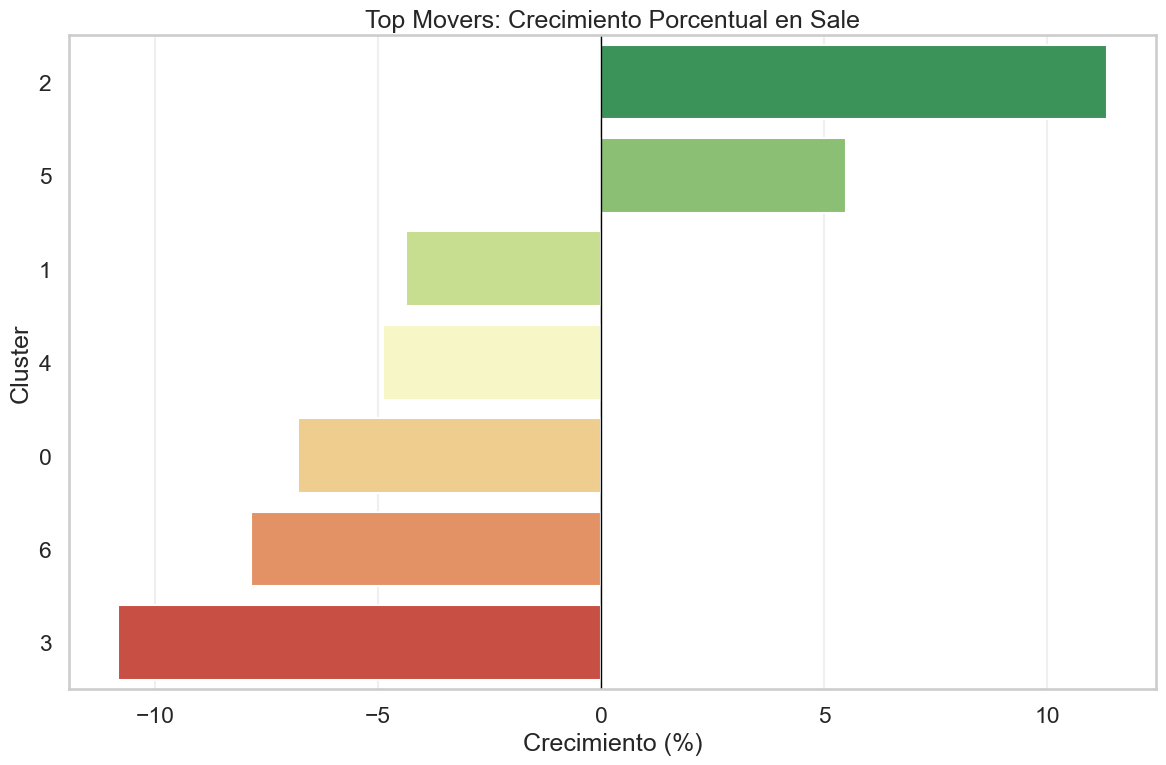


--- Resumen de Items y Crecimiento (cluster) ---
Métrica analizada: Unidades

- 2                    | Items: 3130 | Crecimiento: ↗️  11.33%
Total Dif. Sales: ↗️   8183
- 5                    | Items: 2410 | Crecimiento: ↗️   5.49%
Total Dif. Sales: ↗️   1830
- 1                    | Items: 6360 | Crecimiento: ↘️  -4.37%
Total Dif. Sales: ↘️ -11564
- 4                    | Items: 6070 | Crecimiento: ↘️  -4.89%
Total Dif. Sales: ↘️ -11281
- 0                    | Items: 10130 | Crecimiento: ↘️  -6.78%
Total Dif. Sales: ↘️ -28739
- 1                    | Items: 6360 | Crecimiento: ↘️  -4.37%
Total Dif. Sales: ↘️ -11564
- 4                    | Items: 6070 | Crecimiento: ↘️  -4.89%
Total Dif. Sales: ↘️ -11281
- 0                    | Items: 10130 | Crecimiento: ↘️  -6.78%
Total Dif. Sales: ↘️ -28739
- 6                    | Items:  780 | Crecimiento: ↘️  -7.84%
Total Dif. Sales: ↘️  -2679
- 3                    | Items: 1610 | Crecimiento: ↘️ -10.82%
Total Dif. Sales: ↘️ -13616


In [290]:
plot_top_movers_pct(df_viz=df_viz_lasso_2, metric_mode='sale', dept_col='cluster')